In [1]:
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
import numpy as np
from copy import deepcopy as cdc

from datetime import datetime as dt
import re
def extract_timestamps(series:pd.Series) -> pd.Series:
    timestamp = series.str.extract('_(\d{4}-[\-\d_T]*)DLC', expand=False)
    return pd.to_datetime(timestamp, format="%Y-%m-%dT%H_%M_%S")
##need to have filename column as type str in order for datetime extraction to be used, won't run on Posix type

import statsmodels.api as sm
from statsmodels.formula.api import ols
from scipy import stats

h5_newmice="/Users/mollyshallow/Desktop/opto_metrics_result/20230530_newcohort_LD_test.h5"
h5_oldmice="/Users/mollyshallow/Desktop/opto_metrics_result/20230530_oldcohorts_LD_test.h5"

# h5='/Users/mollyshallow/Desktop/20221028_allmice_alltrials_LD.h5'
# h5_old='/Users/mollyshallow/Desktop/20221011_allmice_alltrials_LD_01.h5'

In [5]:
df_old=pd.read_hdf(h5_oldmice, key='df')
with open('folderlist.txt', 'w') as f_out:
    f_out.write('\n'.join(df_old['folder_path'].astype('str')))
df_old['filename']=df_old['filename'].astype('str')
# type(df_all['filename'][0])
df_old=df_old[df_old['filename'].str.contains('0896|0897|0898|0893|0895')]
df_old['capduration']=df_old['captureT']-df_old['timetointercept']

df_new=pd.read_hdf(h5_newmice, key='df')
with open('folderlist.txt', 'w') as f_out:
    f_out.write('\n'.join(df_new['folder_path'].astype('str')))
df_new['filename']=df_new['filename'].astype('str')
# type(df_all['filename'][0])
df_new=df_new[df_new['filename'].str.contains('1337|1429|1430')]
df_new['capduration']=df_new['captureT']-df_new['timetointercept']

df_all=pd.concat([df_old, df_new], ignore_index=True)

fr=200

nandf=cdc(df_all)
nans=np.where(nandf['captureT']>=120)
nanvals=nandf['captureT'].iloc[nans[0]]
nandf=nandf.replace({'captureT':nanvals.values}, np.nan)

nan_attacks=np.where(nandf['timetointercept']>=120)
nan_attackvals=nandf['timetointercept'].iloc[nan_attacks[0]]
nandf=nandf.replace({'timetointercept':nan_attackvals.values}, np.nan)

nan_approach=np.where(nandf['timetoapproach']>=120)
nan_approachvals=nandf['timetoapproach'].iloc[nan_approach[0]]
nandf=nandf.replace({'timetoapproach':nan_approachvals.values}, np.nan)

nandf['capduration']=nandf['captureT']-nandf['timetointercept']

#unfortunately, intercept time was initially calculated from the start of the trial not from the cricket drop, attemtping to correct for this 
# in correcting for this, realized that a bunch of the intercept frames are for some reason before the cricket drop, not quite sure how this is happening because dist data doesnt align
nandf['corrected_timetointercept']=(nandf['interceptframe']-nandf['cricketdrop'])/fr
nandf['corrected_capduration']=nandf['captureT']-nandf['corrected_timetointercept']



test_nandf=cdc(nandf)
test_nandf= test_nandf.drop(test_nandf[test_nandf.trials_to_drop == 'both'].index)

drops=np.where(nandf['trials_to_drop']=='both')[0]
drops

test_nandf=cdc(nandf)
test_nandf= test_nandf.drop(test_nandf[test_nandf.trials_to_drop == 'both'].index)

test=extract_timestamps(test_nandf["filename"])

test=test.to_list()
test_nandf['timestamps']=test

start_cohort1_baseline_l = dt.strptime('2022-02-10', "%Y-%m-%d")
end_cohort1_baseline_l = dt.strptime('2022-02-15', "%Y-%m-%d")

start_cohort1_baseline_d = dt.strptime('2022-02-16', "%Y-%m-%d")
end_cohort1_baseline_d = dt.strptime('2022-02-21', "%Y-%m-%d")

start_cohort1_l = dt.strptime('2022-02-22', "%Y-%m-%d")
end_cohort1_l = dt.strptime('2022-03-02', "%Y-%m-%d")

start_cohort1_d = dt.strptime('2022-03-03', "%Y-%m-%d")
end_cohort1_d = dt.strptime('2022-03-12', "%Y-%m-%d")

start_cohort2_baseline_l = dt.strptime('2022-07-11', "%Y-%m-%d")
end_cohort2_baseline_l = dt.strptime('2022-07-14', "%Y-%m-%d")

start_cohort2_baseline_d = dt.strptime('2022-07-15', "%Y-%m-%d")
end_cohort2_baseline_d = dt.strptime('2022-07-22', "%Y-%m-%d")

start_cohort2_l = dt.strptime('2022-07-20', "%Y-%m-%d")
end_cohort2_l = dt.strptime('2022-07-26', "%Y-%m-%d")

start_cohort2_d = dt.strptime('2022-07-27', "%Y-%m-%d")
end_cohort2_d = dt.strptime('2022-08-25', "%Y-%m-%d")


start_cohort3_baseline_l = dt.strptime('2022-12-07', "%Y-%m-%d")
end_cohort3_baseline_l = dt.strptime('2022-12-13', "%Y-%m-%d")

start_cohort3_baseline_d = dt.strptime('2023-01-05', "%Y-%m-%d")
end_cohort3_baseline_d = dt.strptime('2023-01-11', "%Y-%m-%d")

start_cohort3_l = dt.strptime('2023-01-13', "%Y-%m-%d")
end_cohort3_l = dt.strptime('2023-01-22', "%Y-%m-%d")

start_cohort3_d = dt.strptime('2023-01-23', "%Y-%m-%d")
end_cohort3_d = dt.strptime('2023-01-29', "%Y-%m-%d")

indices=np.asarray(test_nandf.index)

for i in indices:
    if start_cohort1_baseline_l<=test_nandf['timestamps'][i]<=start_cohort1_baseline_d:
        if test_nandf['condition'][i]!=[5,6]:
            test_nandf.at[i, 'condition']='baseline_l'
            # print(test_nandf['condition'].iloc[i])
  
    elif start_cohort1_baseline_d<=test_nandf['timestamps'][i]<=start_cohort1_l:
        if test_nandf['condition'][i]!=[5,6]:
            # print(test_nandf['folder_path'].iloc[i])
            # print(test_nandf['condition'].iloc[i])
            test_nandf.at[i, 'condition']='baseline_d'
            # print(test_nandf['condition'].iloc[i])
        
    elif start_cohort2_baseline_l<=test_nandf['timestamps'][i]<=start_cohort2_baseline_d:
        if test_nandf['condition'][i]!=[5,6]:
            test_nandf.at[i, 'condition']='baseline_l'
        
    elif start_cohort2_baseline_d<=test_nandf['timestamps'][i]<=start_cohort2_l:
        if test_nandf['condition'][i]!=[5,6]:
            test_nandf.at[i, 'condition']='baseline_d'
        
    elif start_cohort3_baseline_l<=test_nandf['timestamps'][i]<=start_cohort3_baseline_d:
        if test_nandf['condition'][i]!=[7,8]:
            test_nandf.at[i, 'condition']='baseline_l'
        
    elif start_cohort3_baseline_d<=test_nandf['timestamps'][i]<=start_cohort3_l:
        if test_nandf['condition'][i]!=[7,8]:
            test_nandf.at[i, 'condition']='baseline_d'
            
indices=np.asarray(test_nandf.index)
for i in indices:
    if test_nandf['condition'][i]=='9':
        test_nandf.at[i, 'condition']='2'

conds_keep=test_nandf[test_nandf['condition'].str.contains('1|2', na=False)]
cleaned_conds_keep=conds_keep[conds_keep['filename'].str.contains('0893|0895|0896|0897|0898|1429|1430')]
cleaned_conds_keep

hue_order=[1,0]
palette=['#2976bb','#929591']

##need to check corrected cap durations on this one, but geos should be fine to work with for now



##also double check this df to make sure that I'm not including baseline no laser trials, think that is probably why n for no laser is about double what it is for laser

In [24]:
#in some trials, its finding the intercept frame before the drop frame, find a way to re-calculate time to intercept on these
fr = 200
DIST_THRESH = 5

needs_fix = (
    nandf['interceptframe'].notna() &
    nandf['cricketdrop'].notna() &
    (nandf['interceptframe'] < nandf['cricketdrop'])
)

needs_fix.sum()  # sanity check

nandf['corrected_interceptframe'] = nandf['interceptframe']

def find_post_drop_intercept(dist, drop, thresh=DIST_THRESH):
    """
    dist : list/array of distances
    drop : cricketdrop frame
    """
    try:
        dist_arr = np.asarray(dist, dtype=float)
    except Exception:
        return np.nan

    if drop >= len(dist_arr):
        return np.nan

    post = dist_arr[int(drop):]
    idx = np.where(post < thresh)[0]

    if len(idx) == 0:
        return np.nan

    return int(drop + idx[0])

for i in nandf.index[needs_fix]:
    nandf.at[i, 'corrected_interceptframe'] = find_post_drop_intercept(
        nandf.at[i, 'dist'],
        nandf.at[i, 'cricketdrop']
    )

nandf['corrected_timetointercept'] = (
    nandf['corrected_interceptframe'] - nandf['cricketdrop']
) / fr

nandf.loc[
    nandf['corrected_interceptframe'].isna(),
    'corrected_timetointercept'
] = np.nan

nandf['corrected_capduration'] = (
    nandf['captureT'] - nandf['corrected_timetointercept']
)
fixed = needs_fix & nandf['corrected_interceptframe'].notna()
print(f"Intercepts needing fix: {needs_fix.sum()}")
print(f"Intercepts fixed: {fixed.sum()}")

nandf.loc[
    nandf['corrected_interceptframe'] < nandf['cricketdrop'],
    ['interceptframe', 'cricketdrop', 'corrected_interceptframe']
]


Intercepts needing fix: 1298
Intercepts fixed: 1298


,interceptframe,cricketdrop,corrected_interceptframe


In [28]:
test_nandf=cdc(nandf)
test_nandf= test_nandf.drop(test_nandf[test_nandf.trials_to_drop == 'both'].index)

drops=np.where(nandf['trials_to_drop']=='both')[0]
drops

test_nandf=cdc(nandf)
test_nandf= test_nandf.drop(test_nandf[test_nandf.trials_to_drop == 'both'].index)

test=extract_timestamps(test_nandf["filename"])

test=test.to_list()
test_nandf['timestamps']=test

start_cohort1_baseline_l = dt.strptime('2022-02-10', "%Y-%m-%d")
end_cohort1_baseline_l = dt.strptime('2022-02-15', "%Y-%m-%d")

start_cohort1_baseline_d = dt.strptime('2022-02-16', "%Y-%m-%d")
end_cohort1_baseline_d = dt.strptime('2022-02-21', "%Y-%m-%d")

start_cohort1_l = dt.strptime('2022-02-22', "%Y-%m-%d")
end_cohort1_l = dt.strptime('2022-03-02', "%Y-%m-%d")

start_cohort1_d = dt.strptime('2022-03-03', "%Y-%m-%d")
end_cohort1_d = dt.strptime('2022-03-12', "%Y-%m-%d")

start_cohort2_baseline_l = dt.strptime('2022-07-11', "%Y-%m-%d")
end_cohort2_baseline_l = dt.strptime('2022-07-14', "%Y-%m-%d")

start_cohort2_baseline_d = dt.strptime('2022-07-15', "%Y-%m-%d")
end_cohort2_baseline_d = dt.strptime('2022-07-22', "%Y-%m-%d")

start_cohort2_l = dt.strptime('2022-07-20', "%Y-%m-%d")
end_cohort2_l = dt.strptime('2022-07-26', "%Y-%m-%d")

start_cohort2_d = dt.strptime('2022-07-27', "%Y-%m-%d")
end_cohort2_d = dt.strptime('2022-08-25', "%Y-%m-%d")


start_cohort3_baseline_l = dt.strptime('2022-12-07', "%Y-%m-%d")
end_cohort3_baseline_l = dt.strptime('2022-12-13', "%Y-%m-%d")

start_cohort3_baseline_d = dt.strptime('2023-01-05', "%Y-%m-%d")
end_cohort3_baseline_d = dt.strptime('2023-01-11', "%Y-%m-%d")

start_cohort3_l = dt.strptime('2023-01-13', "%Y-%m-%d")
end_cohort3_l = dt.strptime('2023-01-22', "%Y-%m-%d")

start_cohort3_d = dt.strptime('2023-01-23', "%Y-%m-%d")
end_cohort3_d = dt.strptime('2023-01-29', "%Y-%m-%d")

indices=np.asarray(test_nandf.index)

for i in indices:
    if start_cohort1_baseline_l<=test_nandf['timestamps'][i]<=start_cohort1_baseline_d:
        if test_nandf['condition'][i]!=[5,6]:
            test_nandf.at[i, 'condition']='baseline_l'
            # print(test_nandf['condition'].iloc[i])
  
    elif start_cohort1_baseline_d<=test_nandf['timestamps'][i]<=start_cohort1_l:
        if test_nandf['condition'][i]!=[5,6]:
            # print(test_nandf['folder_path'].iloc[i])
            # print(test_nandf['condition'].iloc[i])
            test_nandf.at[i, 'condition']='baseline_d'
            # print(test_nandf['condition'].iloc[i])
        
    elif start_cohort2_baseline_l<=test_nandf['timestamps'][i]<=start_cohort2_baseline_d:
        if test_nandf['condition'][i]!=[5,6]:
            test_nandf.at[i, 'condition']='baseline_l'
        
    elif start_cohort2_baseline_d<=test_nandf['timestamps'][i]<=start_cohort2_l:
        if test_nandf['condition'][i]!=[5,6]:
            test_nandf.at[i, 'condition']='baseline_d'
        
    elif start_cohort3_baseline_l<=test_nandf['timestamps'][i]<=start_cohort3_baseline_d:
        if test_nandf['condition'][i]!=[7,8]:
            test_nandf.at[i, 'condition']='baseline_l'
        
    elif start_cohort3_baseline_d<=test_nandf['timestamps'][i]<=start_cohort3_l:
        if test_nandf['condition'][i]!=[7,8]:
            test_nandf.at[i, 'condition']='baseline_d'
            
indices=np.asarray(test_nandf.index)
for i in indices:
    if test_nandf['condition'][i]=='9':
        test_nandf.at[i, 'condition']='2'

conds_keep=test_nandf[test_nandf['condition'].str.contains('1|2', na=False)]
cleaned_conds_keep=conds_keep[conds_keep['filename'].str.contains('0893|0895|0896|0897|0898|1429|1430')]
cleaned_conds_keep

hue_order=[1,0]
palette=['#2976bb','#929591']

In [25]:
nandf

,filename,folder_path,condition,laser_value,dist,cricket_spd,mouse_spd,az,captureT,cricketdrop,...,prob_inter,prob_capture,timetointercept,interceptframe,c_length,capduration,trials_to_drop,corrected_timetointercept,corrected_capduration,corrected_interceptframe
0,/Volumes/Projects/PreyCapture/ZIActivation/202...,2022-02-03_10-35-15_mouse-0896,test,NaN,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[2.8795219943601467, 2.442993623570855, 1.0383...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",NaN,23677.0,...,1.000000,0.500000,105.110,21022.0,5.44500,NaN,NaN,0.000,NaN,23677.0
1,/Volumes/Projects/PreyCapture/ZIActivation/202...,2022-02-03_10-48-30_mouse-0897,test,NaN,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[8.198352308904875, 9.166484098923334, 9.41997...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",99.920,45034.0,...,0.500000,1.000000,62.520,12504.0,4.10750,37.400,NaN,58.375,41.545,56709.0
2,/Volumes/Projects/PreyCapture/ZIActivation/202...,2022-02-04_10-34-40_mouse-0897,test,NaN,"[46.392508377380324, 47.23411538032969, 47.337...","[3.9652614660669916, 4.119093399691461, 4.1241...","[50.618691414766595, 50.71237504843739, 50.828...","[nan, 111.63212588755803, 104.85524437232709, ...",NaN,0.0,...,0.062500,0.500000,NaN,54497.0,259.39575,NaN,NaN,272.485,NaN,54497.0
3,/Volumes/Projects/PreyCapture/ZIActivation/202...,2022-02-04_9-56-15_mouse-0896,test,NaN,"[40.04921463768118, 40.035394536679895, 40.026...","[1.2688213867795146, 1.3035432250095929, 1.311...","[3.0117482064091323, 3.2035749056084173, 3.922...","[81.05892397374892, 80.5885024990399, 77.60461...",NaN,0.0,...,0.030303,1.000000,NaN,114748.0,47.50325,NaN,NaN,573.740,NaN,114748.0
4,/Volumes/Projects/PreyCapture/ZIActivation/202...,2022-02-07_13-59-24_mouse-0898,5,NaN,"[40.89803428142533, 41.589963686138944, 41.583...","[12.590891895604264, 12.590891895604264, 12.58...","[1.2404139363968412, 1.216827476662106, 1.4645...","[139.4622072253276, 140.52615233536343, 140.77...",NaN,0.0,...,0.125000,1.000000,NaN,87863.0,39.82925,NaN,NaN,439.315,NaN,87863.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2435,/Volumes/Projects/PreyCapture/ZIActivation/202...,2023-01-29_13-25-16_mouse-1430,9,1.0,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[4.686184402668794, 5.375521759637996, 7.19742...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",22.525,1805.0,...,0.666667,0.250000,6.905,1381.0,9.36850,15.620,left_only,2.580,19.945,2321.0
2436,/Volumes/Projects/PreyCapture/ZIActivation/202...,2023-01-29_13-27-15_mouse-1430,9,0.0,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[1.593484666671011, 1.7669192009721417, 1.8651...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",12.125,1513.0,...,0.200000,1.000000,11.625,2325.0,10.74700,0.500,left_only,4.060,8.065,2325.0
2437,/Volumes/Projects/PreyCapture/ZIActivation/202...,2023-01-29_13-29-34_mouse-1430,9,1.0,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[13.55084575241241, 15.911738188176692, 18.134...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",6.740,1766.0,...,1.000000,1.000000,6.720,1344.0,10.24200,0.020,left_only,1.070,5.670,1980.0
2438,/Volumes/Projects/PreyCapture/ZIActivation/202...,2023-01-29_13-30-57_mouse-1430,9,0.0,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[5.6081144264218015, 6.058750344073401, 6.2490...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",NaN,1494.0,...,0.263158,0.100000,27.820,5564.0,7.58625,NaN,left_only,20.350,NaN,5564.0


In [29]:
cleaned_conds_keep

,filename,folder_path,condition,laser_value,dist,cricket_spd,mouse_spd,az,captureT,cricketdrop,...,prob_capture,timetointercept,interceptframe,c_length,capduration,trials_to_drop,corrected_timetointercept,corrected_capduration,corrected_interceptframe,timestamps
244,/Volumes/Projects/PreyCapture/ZIActivation/202...,2022-02-22_10-05-07_mouse-0897,1,1.0,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[1.4692367137209918, 2.779779701312001, 3.2017...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",19.145,2312.0,...,0.142857,5.350,1070.0,11.96500,13.795,NaN,5.330,13.815,3378.0,2022-02-22 10:05:07
245,/Volumes/Projects/PreyCapture/ZIActivation/202...,2022-02-22_10-07-02_mouse-0897,1,1.0,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[8.757072790716952, 9.362620173911946, 9.82083...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",7.435,2005.0,...,0.333333,1.970,394.0,7.51450,5.465,NaN,1.670,5.765,2339.0,2022-02-22 10:07:02
246,/Volumes/Projects/PreyCapture/ZIActivation/202...,2022-02-22_10-12-42_mouse-0897,1,1.0,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[1.0548578586351982, 1.1435315586646064, 1.217...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",1.665,2246.0,...,1.000000,1.640,328.0,10.95325,0.025,NaN,1.310,0.355,2508.0,2022-02-22 10:12:42
247,/Volumes/Projects/PreyCapture/ZIActivation/202...,2022-02-22_10-14-33_mouse-0897,1,0.0,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[8.447304574249497, 8.829336439003862, 10.5655...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",8.040,1781.0,...,1.000000,3.460,692.0,14.81550,4.580,NaN,3.335,4.705,2448.0,2022-02-22 10:14:33
248,/Volumes/Projects/PreyCapture/ZIActivation/202...,2022-02-22_10-16-01_mouse-0897,1,0.0,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[5.550975346948177, 5.2380705840289234, 5.6036...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",6.510,1125.0,...,0.500000,5.670,1134.0,11.11225,0.840,NaN,0.045,6.465,1134.0,2022-02-22 10:16:01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2435,/Volumes/Projects/PreyCapture/ZIActivation/202...,2023-01-29_13-25-16_mouse-1430,2,1.0,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[4.686184402668794, 5.375521759637996, 7.19742...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",22.525,1805.0,...,0.250000,6.905,1381.0,9.36850,15.620,left_only,2.580,19.945,2321.0,2023-01-29 13:25:16
2436,/Volumes/Projects/PreyCapture/ZIActivation/202...,2023-01-29_13-27-15_mouse-1430,2,0.0,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[1.593484666671011, 1.7669192009721417, 1.8651...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",12.125,1513.0,...,1.000000,11.625,2325.0,10.74700,0.500,left_only,4.060,8.065,2325.0,2023-01-29 13:27:15
2437,/Volumes/Projects/PreyCapture/ZIActivation/202...,2023-01-29_13-29-34_mouse-1430,2,1.0,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[13.55084575241241, 15.911738188176692, 18.134...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",6.740,1766.0,...,1.000000,6.720,1344.0,10.24200,0.020,left_only,1.070,5.670,1980.0,2023-01-29 13:29:34
2438,/Volumes/Projects/PreyCapture/ZIActivation/202...,2023-01-29_13-30-57_mouse-1430,2,0.0,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[5.6081144264218015, 6.058750344073401, 6.2490...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",NaN,1494.0,...,0.100000,27.820,5564.0,7.58625,NaN,left_only,20.350,NaN,5564.0,2023-01-29 13:30:57


In [37]:
from scipy.stats import ranksums

# Assuming your dataframe is called df
# Drop NaNs in relevant columns
df_clean = cleaned_conds_keep.dropna(subset=["corrected_capduration", "laser_value", "condition"])

# Container for results
results = []

# Loop through each condition (e.g., 1 and 2)
for condition, group in df_clean.groupby("condition"):
    # Split by laser_value (0 vs 1)
    group0 = group[group["laser_value"] == 0]["corrected_capduration"].dropna()
    group1 = group[group["laser_value"] == 1]["corrected_capduration"].dropna()
    
    if len(group0) > 1 and len(group1) > 1:
        # Perform rank-sum test
        stat, pval = ranksums(group0, group1)
        results.append({
            "condition": condition,
            "laser_value_0_n": len(group0),
            "laser_value_1_n": len(group1),
            "statistic": stat,
            "p_value": pval
        })
    else:
        results.append({
            "condition": condition,
            "laser_value_0_n": len(group0),
            "laser_value_1_n": len(group1),
            "statistic": None,
            "p_value": None
        })

# Convert to DataFrame for easy viewing
ranksum_results = pd.DataFrame(results)
print(ranksum_results)

  condition  laser_value_0_n  laser_value_1_n  statistic   p_value
0         1              214              220   0.848905  0.395934
1         2              239              252   1.769742  0.076770


In [46]:
cleaned_conds_keep.to_csv('/Volumes/Projects/PreyCapture/ZIActivation/all_mice_lightdark.csv')

In [5]:
darkpalette=['#030aa7','#000000']

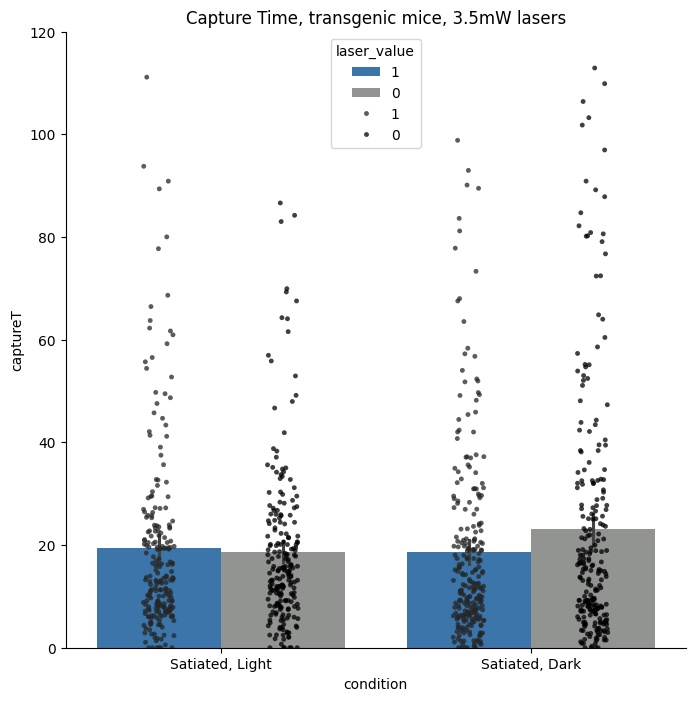

In [34]:
plt.figure(figsize=(8,8))
ax=sns.barplot(data=cleaned_conds_keep, x='condition', y='captureT', hue='laser_value', palette=palette, hue_order=hue_order)
ax= sns.stripplot(x='condition', y='captureT', hue='laser_value',dodge=True, data=cleaned_conds_keep, palette='dark:black', size=3.5, alpha=0.75, hue_order=hue_order)
plt.title('Capture Time, transgenic mice, 3.5mW lasers')
plt.ylim(0,120)
# plt.yticks(np.arange(0,130,10))
plt.xticks([0,1],['Satiated, Light', 'Satiated, Dark'])
sns.despine()

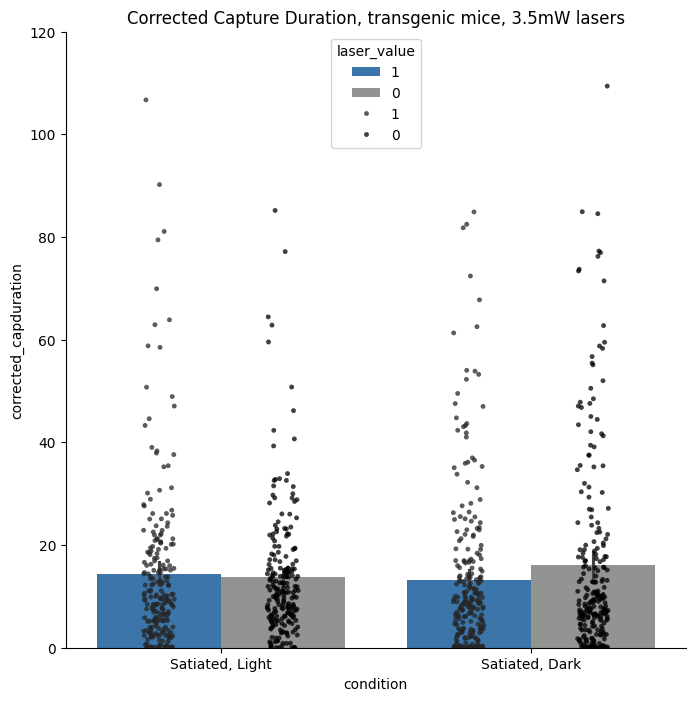

In [32]:
plt.figure(figsize=(8,8))
ax=sns.barplot(data=cleaned_conds_keep, x='condition', y='corrected_capduration', hue='laser_value', palette=palette, hue_order=hue_order)
ax= sns.stripplot(x='condition', y='corrected_capduration', hue='laser_value',dodge=True, data=cleaned_conds_keep, palette='dark:black', size=3.5, alpha=0.75, hue_order=hue_order)
plt.title('Corrected Capture Duration, transgenic mice, 3.5mW lasers')
plt.ylim(0,120)
# plt.yticks(np.arange(0,130,10))
plt.xticks([0,1],['Satiated, Light', 'Satiated, Dark'])
sns.despine()

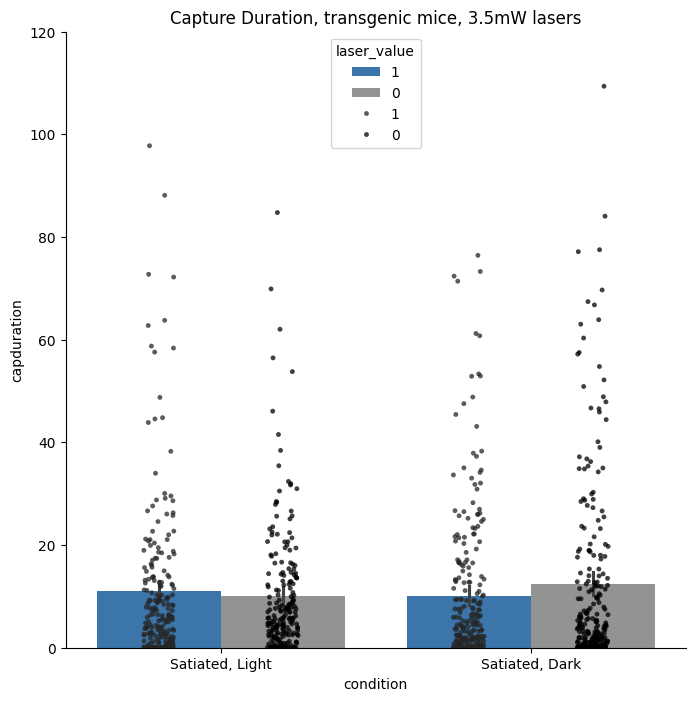

In [33]:
plt.figure(figsize=(8,8))
ax=sns.barplot(data=cleaned_conds_keep, x='condition', y='capduration', hue='laser_value', palette=palette, hue_order=hue_order)
ax= sns.stripplot(x='condition', y='capduration', hue='laser_value',dodge=True, data=cleaned_conds_keep, palette='dark:black', size=3.5, alpha=0.75, hue_order=hue_order)
plt.title('Capture Duration, transgenic mice, 3.5mW lasers')
plt.ylim(0,120)
# plt.yticks(np.arange(0,130,10))
plt.xticks([0,1],['Satiated, Light', 'Satiated, Dark'])
sns.despine()

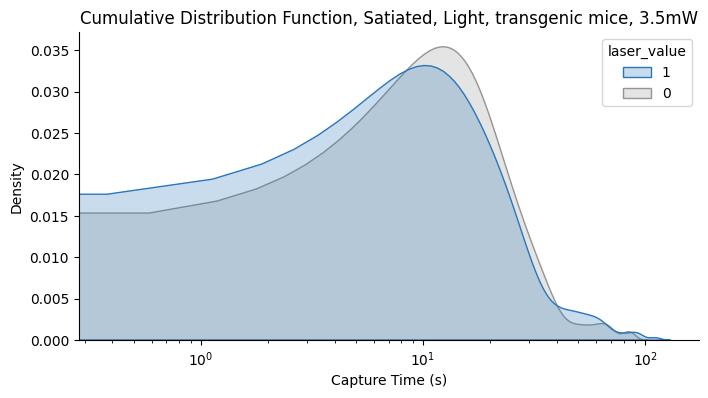

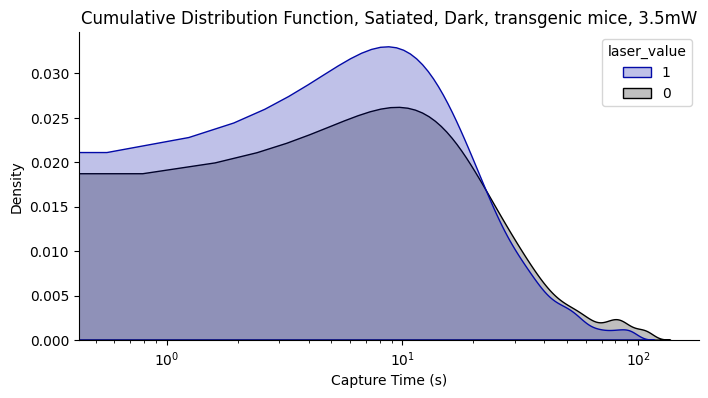

In [35]:
darkpalette=['#030aa7','#000000']

fig1= plt.figure(figsize=(8,4))
ax=sns.kdeplot(data=cleaned_conds_keep.iloc[np.where(cleaned_conds_keep['condition']=='1')], x='captureT', hue='laser_value',hue_order=hue_order, palette=palette, fill=True, common_norm=False)
ax.set_xscale('log')
plt.xlabel('Capture Time (s)')
plt.title('Cumulative Distribution Function, Satiated, Light, transgenic mice, 3.5mW')
# plt.xticks(np.arange(0, 175,25))
# plt.xlim(0, 120)
# plt.ylim(0, 0.06)
sns.despine()
# plt.savefig('/Users/mollyshallow/Desktop/Wehr_Lab/ZIActivationPlots/groupdata/captureduration_kdelight_allmice_nonorm_clip24.pdf')

fig2= plt.figure(figsize=(8,4))
ax=sns.kdeplot(data=cleaned_conds_keep.iloc[np.where(cleaned_conds_keep['condition']=='2')], x='captureT', hue='laser_value',hue_order=hue_order, palette=darkpalette, fill=True,common_norm=False)
ax.set_xscale('log')
plt.xlabel('Capture Time (s)')
plt.title('Cumulative Distribution Function, Satiated, Dark, transgenic mice, 3.5mW')
# plt.xticks(np.arange(-50, 325,25))
# plt.xlim(-0, 120)
# plt.ylim(0, 0.06)
sns.despine()

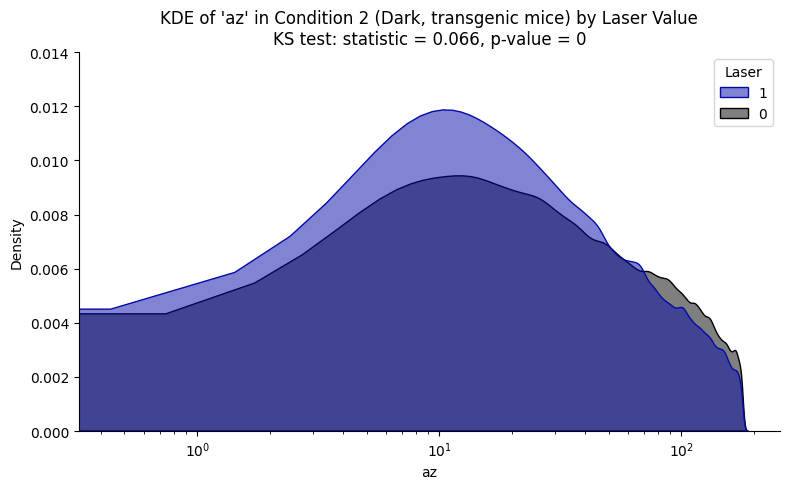

In [41]:

from scipy.stats import ks_2samp

# Settings
geometry = 'az'           # or 'dist', 'mouse_spd', 'cricket_spd'
condition_filter = '2'      # the condition you want to examine (e.g., 'dark', 1, etc.)

# Build long-form data list
long_data = []

for _, row in cleaned_conds_keep.iterrows():
    if row['condition'] == condition_filter and isinstance(row[geometry], np.ndarray):
        for val in row[geometry]:
            if pd.notnull(val):
                long_data.append({
                    'Value': val,
                    'Laser': row['laser_value']
                })

# Convert to DataFrame
kde_df = pd.DataFrame(long_data)
kde_df = kde_df.dropna(subset=['Laser'])

# Separate values by laser group
laser_0 = kde_df[kde_df['Laser'] == 0]['Value']
laser_1 = kde_df[kde_df['Laser'] == 1]['Value']

# Run KS test
ks_stat, ks_pval = ks_2samp(laser_0, laser_1)

# Plot KDE
plt.figure(figsize=(8, 5))
sns.kdeplot(data=kde_df, x='Value', hue='Laser', fill=True, common_norm=False, alpha=0.5, hue_order=hue_order, palette=darkpalette,)



plt.title(f"KDE of '{geometry}' in Condition {condition_filter} (Dark, transgenic mice) by Laser Value\n"
          f"KS test: statistic = {ks_stat:.3f}, p-value = {ks_pval:.3g}")
plt.xlabel(geometry)
plt.xscale('log')
plt.ylabel("Density")
# plt.xlim(0,190)
plt.ylim(0,0.014)
plt.tight_layout()
sns.despine()
plt.show()


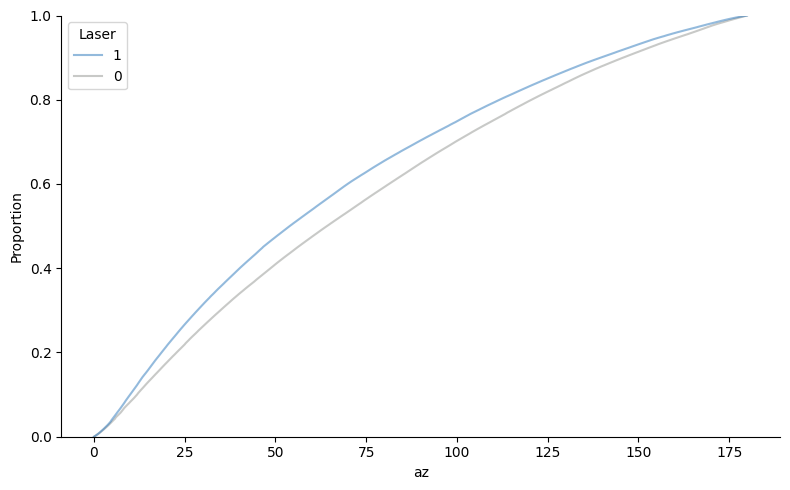

In [129]:
plt.figure(figsize=(8, 5))
sns.ecdfplot(data=kde_df, x='Value', hue='Laser', stat='proportion', alpha=0.5, hue_order=hue_order, palette=palette,)
plt.xlabel(geometry)
plt.tight_layout()
sns.despine()
plt.show()

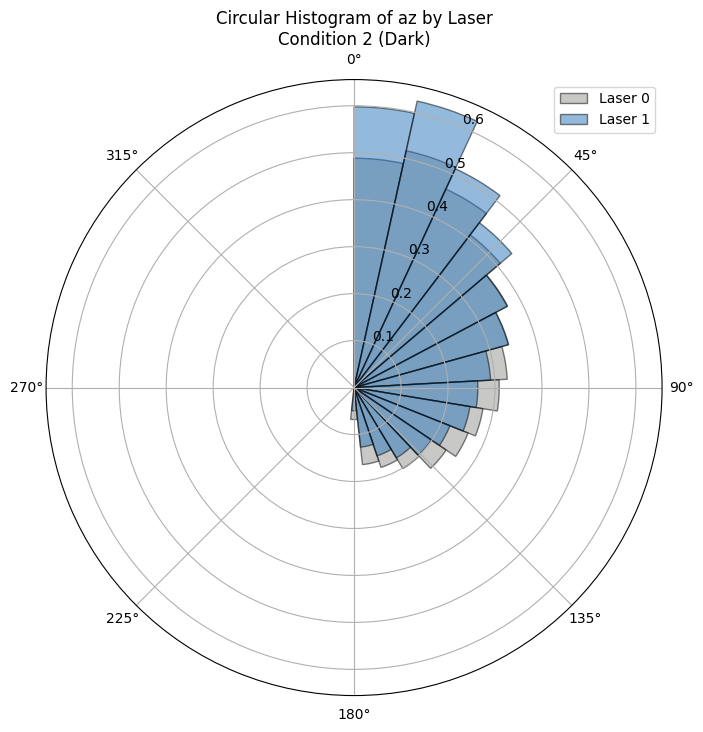

In [130]:
laser_0_angles = np.deg2rad(kde_df[kde_df['Laser'] == 0]['Value'].dropna())
laser_1_angles = np.deg2rad(kde_df[kde_df['Laser'] == 1]['Value'].dropna())

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, polar=True)

# Rotate so that zero is at the top (12 o'clock)
ax.set_theta_zero_location("N")  # "N" = North (top)

# Optional: set direction of increasing angle to clockwise (default is counterclockwise)
ax.set_theta_direction(-1)

bins = np.linspace(0, 2 * np.pi, 30)

ax.hist(laser_0_angles, bins=bins, alpha=0.5, label='Laser 0', density=True, edgecolor='black', color=palette[1])
ax.hist(laser_1_angles, bins=bins, alpha=0.5, label='Laser 1', density=True,edgecolor='black', color=palette[0])

ax.set_title(f'Circular Histogram of {geometry} by Laser\nCondition {condition_filter} (Dark)')
ax.legend()
plt.show()

#### might need to change az code a little bit so that its not agnostic to L vs R, right now have the absolute value of the angles rather than it being 0 to 180 on one side and 0 to -180 on the other, could try to change this so plot is symmetric

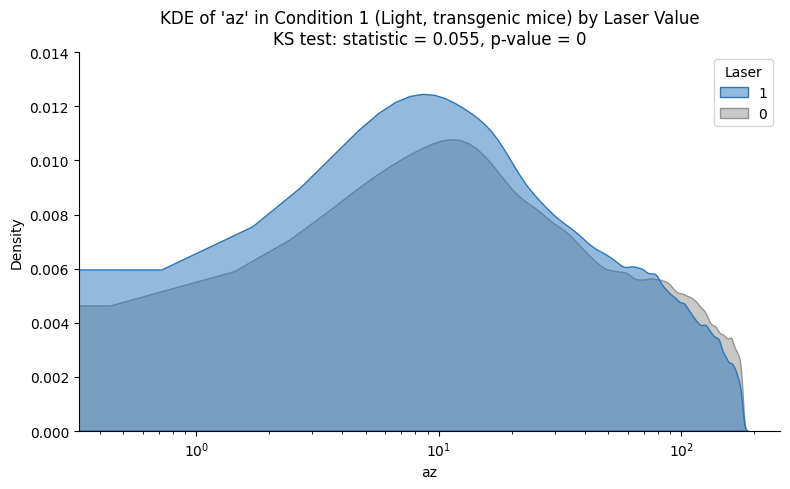

In [40]:


# Settings
geometry = 'az'           # or 'dist', 'mouse_spd', 'cricket_spd'
condition_filter = '1'      # the condition you want to examine (e.g., 'dark', 1, etc.)

# Build long-form data list
long_data = []

for _, row in cleaned_conds_keep.iterrows():
    if row['condition'] == condition_filter and isinstance(row[geometry], np.ndarray):
        for val in row[geometry]:
            if pd.notnull(val):
                long_data.append({
                    'Value': val,
                    'Laser': row['laser_value']
                })

# Convert to DataFrame
kde_df = pd.DataFrame(long_data)
kde_df = kde_df.dropna(subset=['Laser'])

# Separate values by laser group
laser_0 = kde_df[kde_df['Laser'] == 0]['Value']
laser_1 = kde_df[kde_df['Laser'] == 1]['Value']

# Run KS test
ks_stat, ks_pval = ks_2samp(laser_0, laser_1)

# Plot KDE
plt.figure(figsize=(8, 5))
sns.kdeplot(data=kde_df, x='Value', hue='Laser', fill=True, common_norm=False, alpha=0.5, hue_order=hue_order, palette=palette,)
plt.title(f"KDE of '{geometry}' in Condition {condition_filter} (Light, transgenic mice) by Laser Value\n"
          f"KS test: statistic = {ks_stat:.3f}, p-value = {ks_pval:.3g}")
plt.xlabel(geometry)
plt.xscale('log')
plt.ylabel("Density")
# plt.xlim(0,190)
plt.ylim(0,0.014)
plt.tight_layout()
sns.despine()
plt.show()


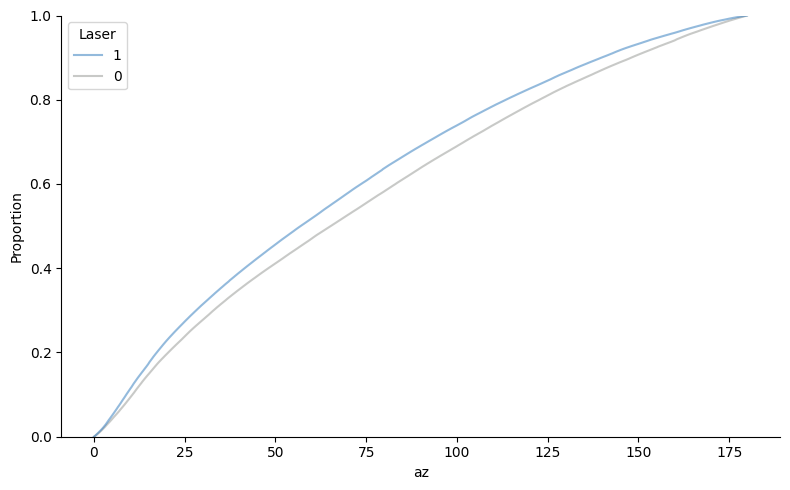

In [133]:
plt.figure(figsize=(8, 5))
sns.ecdfplot(data=kde_df, x='Value', hue='Laser', stat='proportion', alpha=0.5, hue_order=hue_order, palette=palette,)
plt.xlabel(geometry)
plt.tight_layout()
sns.despine()
plt.show()

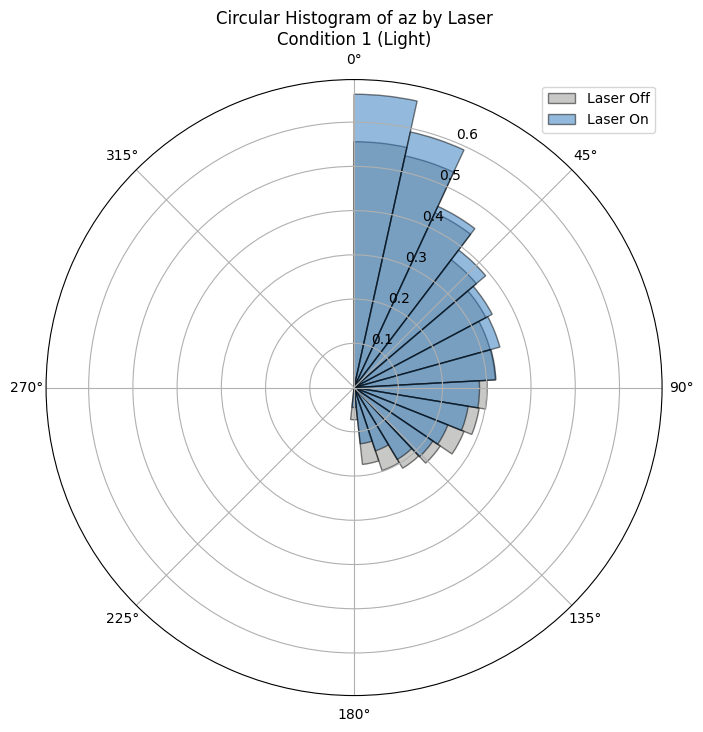

In [134]:
laser_0_angles = np.deg2rad(kde_df[kde_df['Laser'] == 0]['Value'].dropna())
laser_1_angles = np.deg2rad(kde_df[kde_df['Laser'] == 1]['Value'].dropna())

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, polar=True)

# Rotate so that zero is at the top (12 o'clock)
ax.set_theta_zero_location("N")  # "N" = North (top)

# Optional: set direction of increasing angle to clockwise (default is counterclockwise)
ax.set_theta_direction(-1)

bins = np.linspace(0, 2 * np.pi, 30)

ax.hist(laser_0_angles, bins=bins, alpha=0.5, label='Laser Off', density=True, edgecolor='black', color=palette[1])
ax.hist(laser_1_angles, bins=bins, alpha=0.5, label='Laser On', density=True,edgecolor='black', color=palette[0])

ax.set_title(f'Circular Histogram of {geometry} by Laser\nCondition {condition_filter} (Light)')
ax.legend()
plt.show()

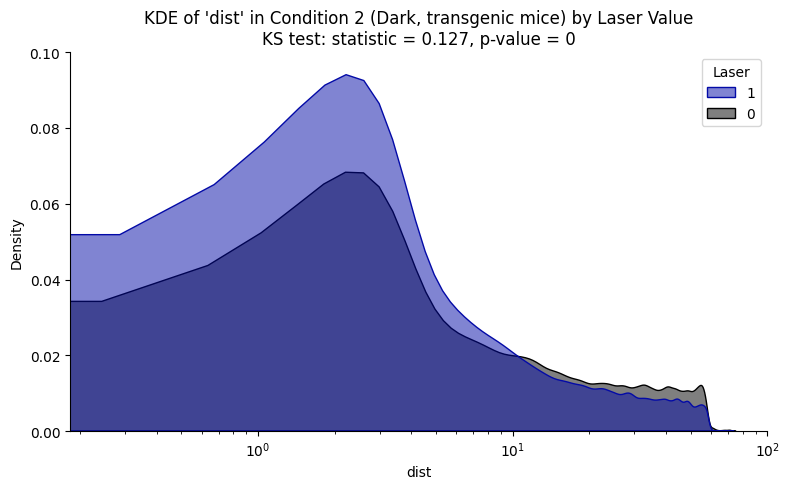

In [42]:


# Settings
geometry = 'dist'           # or 'dist', 'mouse_spd', 'cricket_spd'
condition_filter = '2'      # the condition you want to examine (e.g., 'dark', 1, etc.)

# Build long-form data list
long_data = []

for _, row in cleaned_conds_keep.iterrows():
    if row['condition'] == condition_filter and isinstance(row[geometry], np.ndarray):
        for val in row[geometry]:
            if pd.notnull(val):
                long_data.append({
                    'Value': val,
                    'Laser': row['laser_value']
                })

# Convert to DataFrame
kde_df = pd.DataFrame(long_data)
kde_df = kde_df.dropna(subset=['Laser'])

# Separate values by laser group
laser_0 = kde_df[kde_df['Laser'] == 0]['Value']
laser_1 = kde_df[kde_df['Laser'] == 1]['Value']

# Run KS test
ks_stat, ks_pval = ks_2samp(laser_0, laser_1)

# Plot KDE
plt.figure(figsize=(8, 5))
sns.kdeplot(data=kde_df, x='Value', hue='Laser', fill=True, common_norm=False, alpha=0.5, hue_order=hue_order, palette=darkpalette,)
plt.title(f"KDE of '{geometry}' in Condition {condition_filter} (Dark, transgenic mice) by Laser Value\n"
          f"KS test: statistic = {ks_stat:.3f}, p-value = {ks_pval:.3g}")
plt.xlabel(geometry)
plt.ylabel("Density")
plt.xscale('log')
# plt.xlim(0,60)
plt.ylim(0,0.10)
plt.tight_layout()
sns.despine()
plt.show()


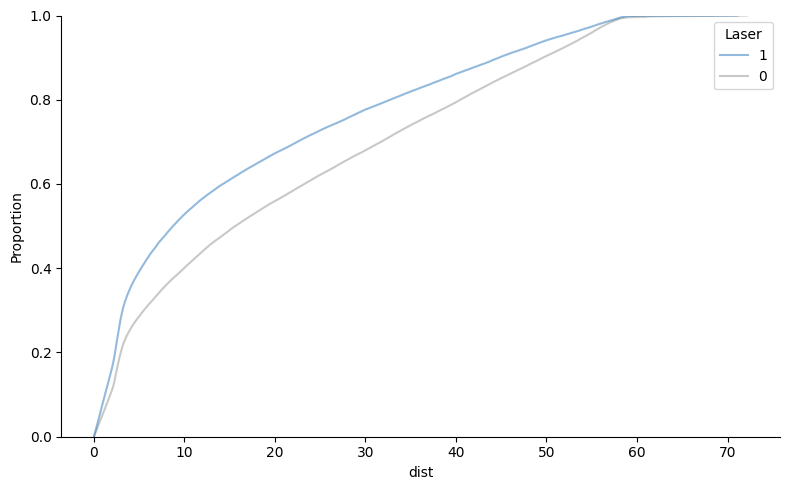

In [137]:
plt.figure(figsize=(8, 5))
sns.ecdfplot(data=kde_df, x='Value', hue='Laser', stat='proportion', alpha=0.5, hue_order=hue_order, palette=palette,)
plt.xlabel(geometry)
plt.tight_layout()
sns.despine()
plt.show()

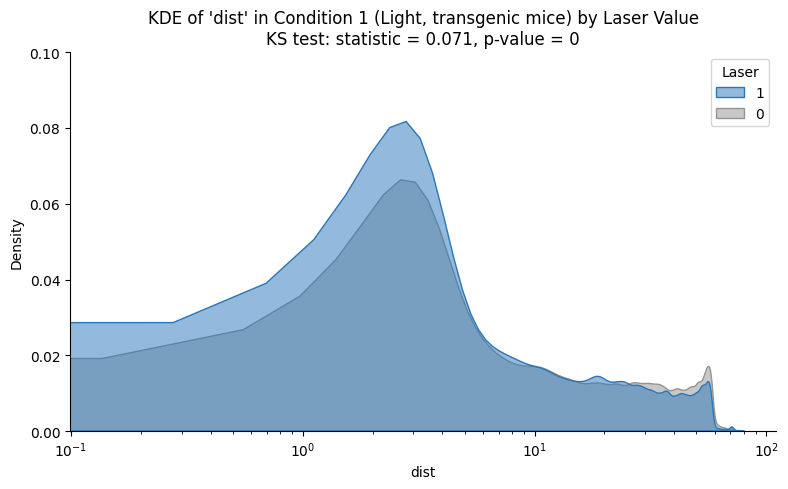

In [43]:
geometry = 'dist'           # or 'dist', 'mouse_spd', 'cricket_spd'
condition_filter = '1'      # the condition you want to examine (e.g., 'dark', 1, etc.)

# Build long-form data list
long_data = []

for _, row in cleaned_conds_keep.iterrows():
    if row['condition'] == condition_filter and isinstance(row[geometry], np.ndarray):
        for val in row[geometry]:
            if pd.notnull(val):
                long_data.append({
                    'Value': val,
                    'Laser': row['laser_value']
                })

# Convert to DataFrame
kde_df = pd.DataFrame(long_data)
kde_df = kde_df.dropna(subset=['Laser'])

# Separate values by laser group
laser_0 = kde_df[kde_df['Laser'] == 0]['Value']
laser_1 = kde_df[kde_df['Laser'] == 1]['Value']

# Run KS test
ks_stat, ks_pval = ks_2samp(laser_0, laser_1)

# Plot KDE
plt.figure(figsize=(8, 5))
sns.kdeplot(data=kde_df, x='Value', hue='Laser', fill=True, common_norm=False, alpha=0.5, hue_order=hue_order, palette=palette,)
plt.title(f"KDE of '{geometry}' in Condition {condition_filter} (Light, transgenic mice) by Laser Value\n"
          f"KS test: statistic = {ks_stat:.3f}, p-value = {ks_pval:.3g}")
plt.xlabel(geometry)
plt.ylabel("Density")
plt.xscale('log')
# plt.xlim(0,60)
plt.ylim(0,0.10)
plt.tight_layout()
sns.despine()
plt.show()

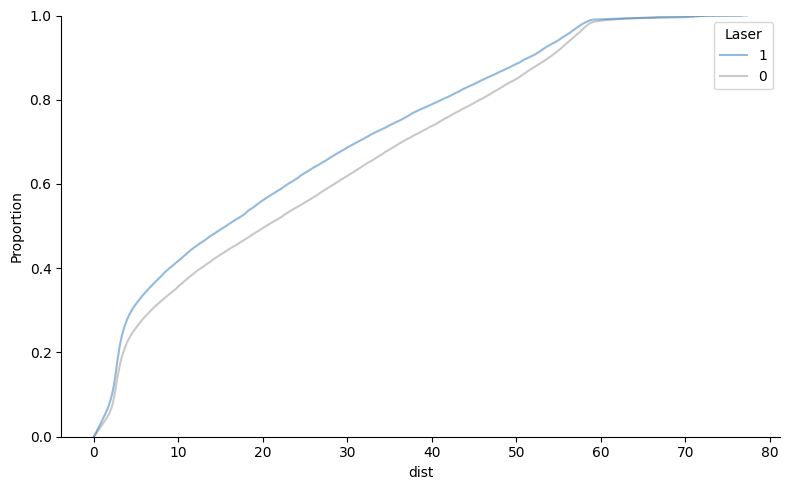

In [140]:
plt.figure(figsize=(8, 5))
sns.ecdfplot(data=kde_df, x='Value', hue='Laser', stat='proportion', alpha=0.5, hue_order=hue_order, palette=palette,)
plt.xlabel(geometry)
plt.tight_layout()
sns.despine()
plt.show()

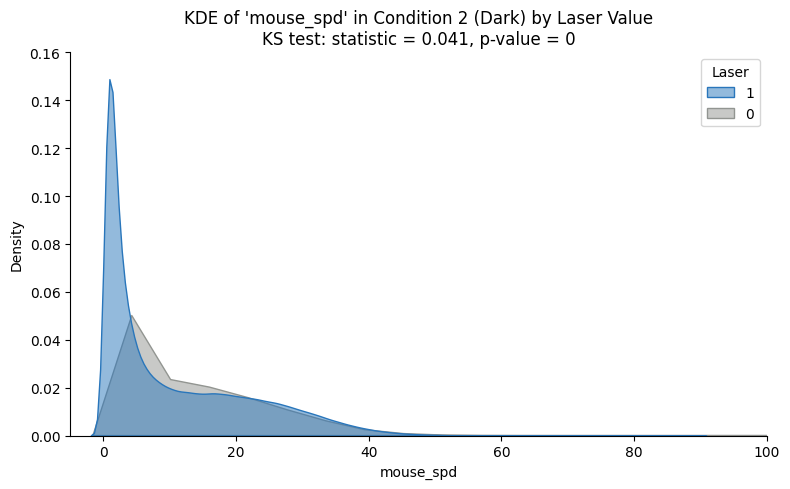

In [62]:
geometry = 'mouse_spd'           # or 'dist', 'mouse_spd', 'cricket_spd'
condition_filter = '2'      # the condition you want to examine (e.g., 'dark', 1, etc.)

# Build long-form data list
long_data = []

for _, row in cleaned_conds_keep.iterrows():
    if row['condition'] == condition_filter and isinstance(row[geometry], np.ndarray):
        for val in row[geometry]:
            if pd.notnull(val):
                long_data.append({
                    'Value': val,
                    'Laser': row['laser_value']
                })

# Convert to DataFrame
kde_df = pd.DataFrame(long_data)
kde_df = kde_df.dropna(subset=['Laser'])

# Separate values by laser group
laser_0 = kde_df[kde_df['Laser'] == 0]['Value']
laser_1 = kde_df[kde_df['Laser'] == 1]['Value']

# Run KS test
ks_stat, ks_pval = ks_2samp(laser_0, laser_1)

# Plot KDE
plt.figure(figsize=(8, 5))
sns.kdeplot(data=kde_df, x='Value', hue='Laser', fill=True, common_norm=False, alpha=0.5, hue_order=hue_order, palette=darkpalette,)
plt.title(f"KDE of '{geometry}' in Condition {condition_filter} (Dark) by Laser Value\n"
          f"KS test: statistic = {ks_stat:.3f}, p-value = {ks_pval:.3g}")
plt.xlabel(geometry)
plt.xlim(-5,100)
plt.ylim(0,0.16)
plt.ylabel("Density")
plt.tight_layout()
sns.despine()
plt.show()

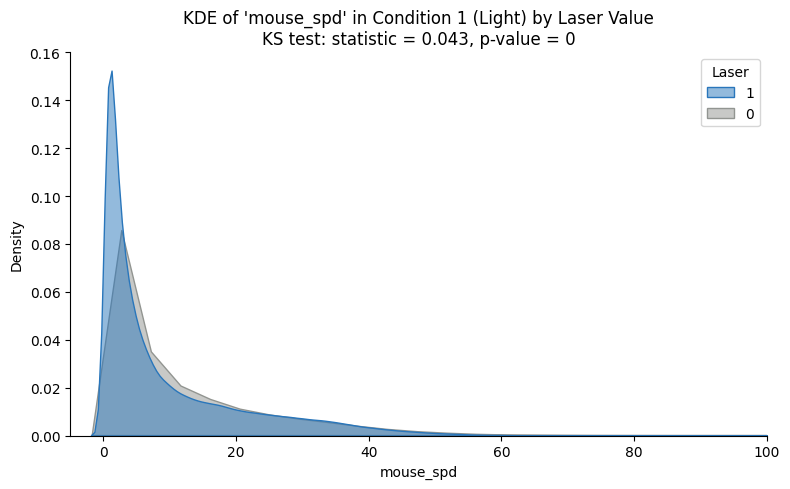

In [63]:
geometry = 'mouse_spd'           # or 'dist', 'mouse_spd', 'cricket_spd'
condition_filter = '1'      # the condition you want to examine (e.g., 'dark', 1, etc.)

# Build long-form data list
long_data = []

for _, row in cleaned_conds_keep.iterrows():
    if row['condition'] == condition_filter and isinstance(row[geometry], np.ndarray):
        for val in row[geometry]:
            if pd.notnull(val):
                long_data.append({
                    'Value': val,
                    'Laser': row['laser_value']
                })

# Convert to DataFrame
kde_df = pd.DataFrame(long_data)
kde_df = kde_df.dropna(subset=['Laser'])

# Separate values by laser group
laser_0 = kde_df[kde_df['Laser'] == 0]['Value']
laser_1 = kde_df[kde_df['Laser'] == 1]['Value']

# Run KS test
ks_stat, ks_pval = ks_2samp(laser_0, laser_1)

# Plot KDE
plt.figure(figsize=(8, 5))
sns.kdeplot(data=kde_df, x='Value', hue='Laser', fill=True, common_norm=False, alpha=0.5, hue_order=hue_order, palette=palette,)
plt.title(f"KDE of '{geometry}' in Condition {condition_filter} (Light) by Laser Value\n"
          f"KS test: statistic = {ks_stat:.3f}, p-value = {ks_pval:.3g}")
plt.xlabel(geometry)
plt.xlim(-5,100)
plt.ylim(0,0.16)
plt.ylabel("Density")
plt.tight_layout()
sns.despine()
plt.show()

In [251]:
cleaned_conds_keep

,filename,folder_path,condition,laser_value,dist,cricket_spd,mouse_spd,az,captureT,cricketdrop,...,interceptframe,c_length,capduration,trials_to_drop,corrected_timetointercept,corrected_capduration,corrected_interceptframe,timestamps,dist_100_after_drop,dist_50_after_drop
244,/Volumes/Projects/PreyCapture/ZIActivation/202...,2022-02-22_10-05-07_mouse-0897,1,1.0,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[1.4692367137209918, 2.779779701312001, 3.2017...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",19.145,2312.0,...,1070.0,11.96500,13.795,NaN,5.330,13.815,3378.0,2022-02-22 10:05:07,48.989210,48.989210
245,/Volumes/Projects/PreyCapture/ZIActivation/202...,2022-02-22_10-07-02_mouse-0897,1,1.0,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[8.757072790716952, 9.362620173911946, 9.82083...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",7.435,2005.0,...,394.0,7.51450,5.465,NaN,1.670,5.765,2339.0,2022-02-22 10:07:02,29.405086,29.405086
246,/Volumes/Projects/PreyCapture/ZIActivation/202...,2022-02-22_10-12-42_mouse-0897,1,1.0,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[1.0548578586351982, 1.1435315586646064, 1.217...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",1.665,2246.0,...,328.0,10.95325,0.025,NaN,1.310,0.355,2508.0,2022-02-22 10:12:42,37.463732,37.463732
247,/Volumes/Projects/PreyCapture/ZIActivation/202...,2022-02-22_10-14-33_mouse-0897,1,0.0,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[8.447304574249497, 8.829336439003862, 10.5655...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",8.040,1781.0,...,692.0,14.81550,4.580,NaN,3.335,4.705,2448.0,2022-02-22 10:14:33,26.247858,26.247858
248,/Volumes/Projects/PreyCapture/ZIActivation/202...,2022-02-22_10-16-01_mouse-0897,1,0.0,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[5.550975346948177, 5.2380705840289234, 5.6036...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",6.510,1125.0,...,1134.0,11.11225,0.840,NaN,0.045,6.465,1134.0,2022-02-22 10:16:01,47.023457,47.023457
249,/Volumes/Projects/PreyCapture/ZIActivation/202...,2022-02-22_10-17-31_mouse-0897,1,0.0,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[0.8210146759869101, 1.4328383724616365, 1.668...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",5.665,919.0,...,438.0,8.57675,3.475,NaN,0.410,5.255,1001.0,2022-02-22 10:17:31,11.528032,11.528032
250,/Volumes/Projects/PreyCapture/ZIActivation/202...,2022-02-22_10-19-26_mouse-0897,1,1.0,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[5.316961148407369, 6.346741648182302, 8.05999...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",2.890,2305.0,...,548.0,8.59425,0.150,NaN,0.800,2.090,2465.0,2022-02-22 10:19:26,23.622505,23.622505
251,/Volumes/Projects/PreyCapture/ZIActivation/202...,2022-02-22_10-22-12_mouse-0897,1,1.0,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[9.392174592883375, 13.649065704900531, 15.629...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",11.140,3999.0,...,1696.0,4.68900,2.660,NaN,8.205,2.935,5640.0,2022-02-22 10:22:12,30.904494,30.904494
252,/Volumes/Projects/PreyCapture/ZIActivation/202...,2022-02-22_10-24-06_mouse-0897,1,0.0,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[16.088667851845024, 16.978035452031886, 18.47...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",10.660,1014.0,...,2120.0,5.18775,0.060,NaN,5.530,5.130,2120.0,2022-02-22 10:24:06,55.288475,55.288475
253,/Volumes/Projects/PreyCapture/ZIActivation/202...,2022-02-22_10-25-47_mouse-0897,1,0.0,"[nan, nan, nan, nan, nan, nan, n

### look into whether there are differential effects of laser across days (maybe even down to the trial level)

In [272]:
## extract mouse#, day# and trial#
df = cleaned_conds_keep.copy()

df['mouse_id'] = (
    df['folder_path']
    .str.extract(r'mouse-(\d+)')
)

df['mouse_id'].value_counts()

df['date'] = df['timestamps'].dt.date

# Ensure timestamps are datetime
df['timestamps'] = pd.to_datetime(
    df['timestamps']
)

# Extract calendar day
df['date'] = df['timestamps'].dt.date

# Create day number WITHIN mouse × condition
df['day_in_condition'] = (
    df
    .groupby(['mouse_id', 'condition'])['date']
    .transform(lambda x: pd.factorize(x)[0] + 1)
)

df = df.sort_values(
    ['mouse_id', 'condition', 'day_in_condition', 'timestamps']
)

df['trial_in_day'] = (
    df
    .groupby(['mouse_id', 'condition', 'day_in_condition'])
    .cumcount() + 1
)


## plot capture time and duration across days 

def plot_capture_metric_across_days(
    df,
    metric_col='captureT',
    condition_col='condition',
    laser_col='laser_value',
    mouse_col='mouse_id',
    day_col='day_in_condition',
    conditions=('1', '2'),
    max_days=5,
    palette=None,
    figsize=(6, 4),
    title=None
):
    """
    Plot capture metric across days WITHIN condition,
    comparing laser ON vs OFF, limited to the first `max_days` per mouse.
    """

    if palette is None:
        palette = {
            0.0: '#4C72B0',  # laser OFF
            1.0: '#DD8452'   # laser ON
        }

    plot_df = (
        df[[metric_col, condition_col, laser_col, mouse_col, day_col]]
        .dropna()
        .copy()
    )

    plot_df = plot_df[plot_df[condition_col].isin(conditions)]

    # -----------------------------------------------
    # Keep only the first `max_days` per mouse & condition
    # -----------------------------------------------
    plot_df = (
        plot_df[plot_df[day_col] <= max_days]
    )

    # ------------------------------------------------
    # Per-mouse per-day mean
    # ------------------------------------------------
    mouse_day = (
        plot_df
        .groupby([mouse_col, condition_col, laser_col, day_col])[metric_col]
        .mean()
        .reset_index()
    )

    # ------------------------------------------------
    # Population summary
    # ------------------------------------------------
    summary = (
        mouse_day
        .groupby([condition_col, laser_col, day_col])[metric_col]
        .agg(['mean', 'sem'])
        .reset_index()
    )

    # ------------------------------------------------
    # Plot
    # ------------------------------------------------
    g = sns.FacetGrid(
        summary,
        col=condition_col,
        col_order=list(conditions),
        hue=laser_col,
        palette=palette,
        height=figsize[1],
        aspect=1.2,
        sharex=True,
        sharey=True
    )

    g.map_dataframe(
        sns.lineplot,
        x=day_col,
        y='mean',
        marker='o'
    )

    for ax, cond in zip(g.axes.flat, conditions):
        for laser in summary[laser_col].unique():
            sub = summary[
                (summary[condition_col] == cond) &
                (summary[laser_col] == laser)
            ]
            ax.errorbar(
                sub[day_col],
                sub['mean'],
                yerr=sub['sem'],
                fmt='none',
                capsize=3,
                alpha=0.7
            )

    g.add_legend(title='Laser')
    g.set_axis_labels('Day in condition', metric_col)
    g.set_titles('Condition {col_name}')

    if title:
        g.fig.suptitle(title, y=1.05)

    sns.despine()
    plt.tight_layout()
    plt.show()



## within day, plot across trials



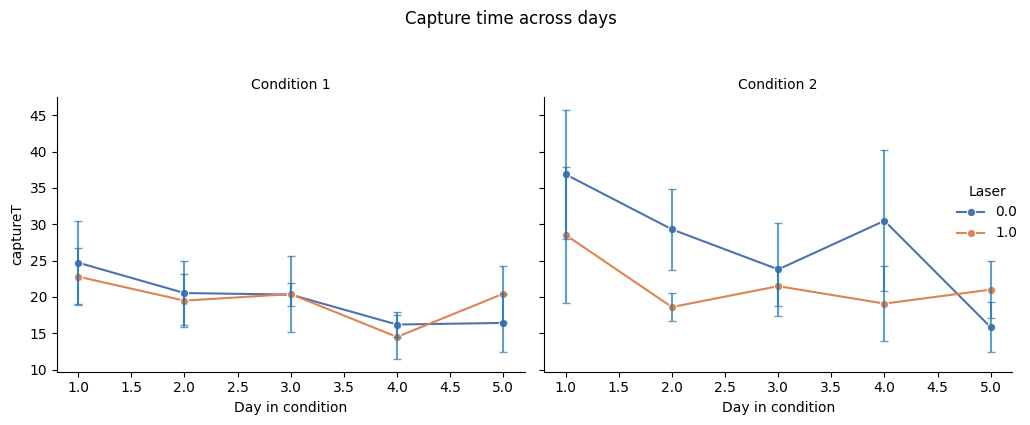

In [273]:
plot_capture_metric_across_days(
    df,
    metric_col='captureT',
    title='Capture time across days'
)


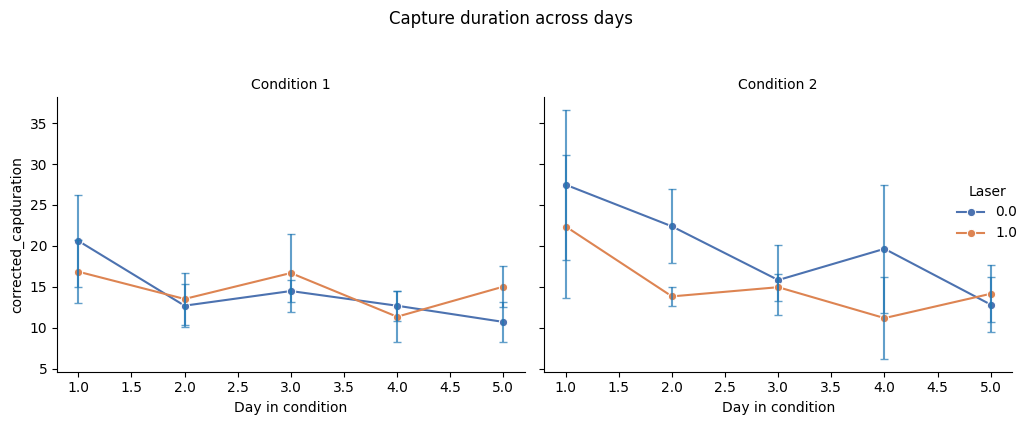

In [274]:
plot_capture_metric_across_days(
    df,
    metric_col='corrected_capduration',
    title='Capture duration across days'
)

In [324]:
def plot_capture_metric_variability(
    df,
    metric_col='captureT',
    condition_col='condition',
    laser_col='laser_value',
    mouse_col='mouse_id',
    day_col='day_in_condition',
    conditions=('1', '2'),
    max_days=5,
    palette=None,
    figsize=(10, 4),
    title=None,
    plot_type='violin'  # 'violin' or 'box'
):
    """
    Plot variability of a capture metric across days using
    boxplots or violin plots (distribution-based variability),
    faceted by condition and comparing laser ON vs OFF.
    """

    if palette is None:
        palette = {
            0.0: '#4C72B0',  # laser OFF
            1.0: '#DD8452'   # laser ON
        }

    # ------------------------------------
    # Filter data
    # ------------------------------------
    plot_df = (
        df[[metric_col, condition_col, laser_col, mouse_col, day_col]]
        .dropna(subset=[metric_col])
        .copy()
    )

    plot_df = plot_df[plot_df[condition_col].isin(conditions)]
    plot_df = plot_df[plot_df[day_col] <= max_days]

    # ------------------------------------
    # Faceted plotting
    # ------------------------------------
    g = sns.FacetGrid(
        plot_df,
        col=condition_col,
        col_order=list(conditions),
        height=figsize[1],
        aspect=1.3,
        sharey=True
    )

    if plot_type == 'violin':
        g.map_dataframe(
            sns.violinplot,
            x=day_col,
            y=metric_col,
            hue=laser_col,
            palette=palette,
            cut=0,
            inner='quartile',
            linewidth=1
        )

    elif plot_type == 'box':
        g.map_dataframe(
            sns.boxplot,
            x=day_col,
            y=metric_col,
            hue=laser_col,
            palette=palette,
            showfliers=True
        )

    else:
        raise ValueError("plot_type must be 'violin' or 'box'")

    # ------------------------------------
    # Formatting
    # ------------------------------------
    g.add_legend(title='Laser')
    g.set_axis_labels('Day in condition', metric_col)
    g.set_titles('Condition {col_name}')

    if title:
        g.fig.suptitle(title, y=1.05)

    sns.despine()
    plt.tight_layout()
    plt.show()


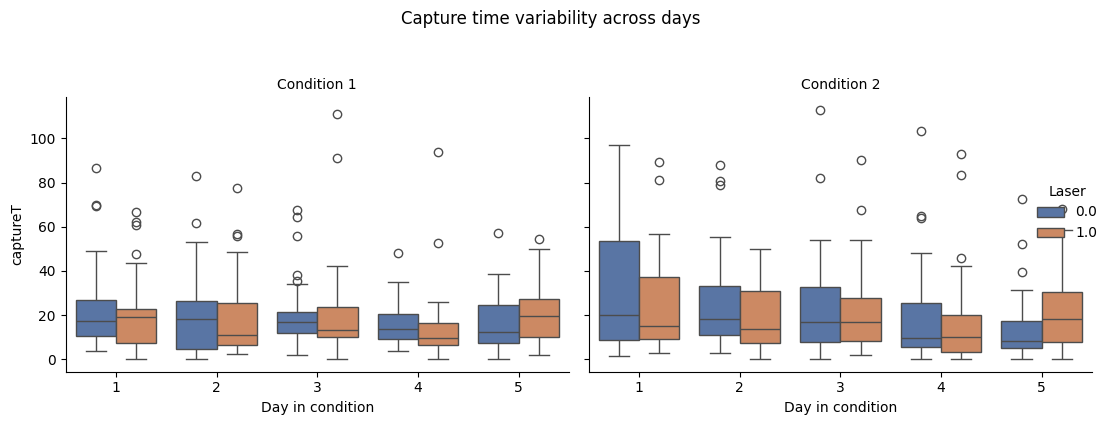

In [326]:
plot_capture_metric_variability(
    df,
    metric_col='captureT',
    plot_type='box',
    title='Capture time variability across days'
)


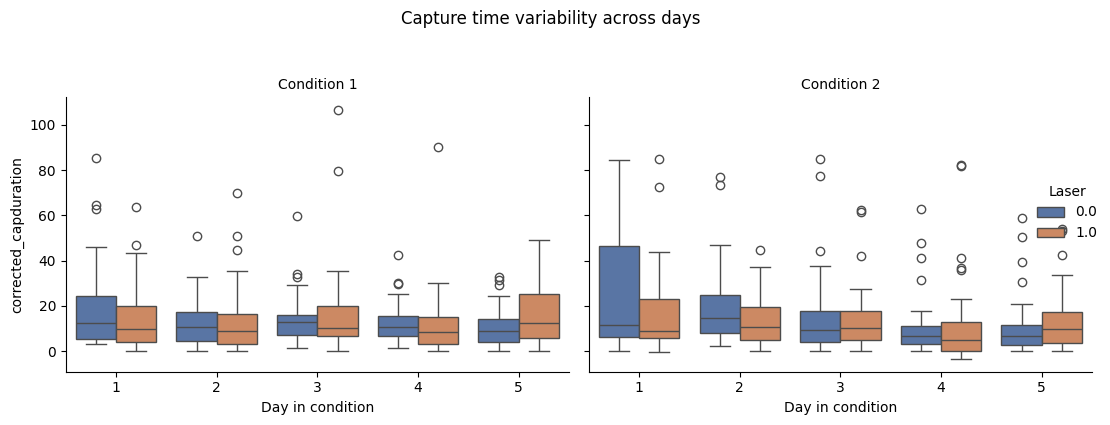

In [327]:
plot_capture_metric_variability(
    df,
    metric_col='corrected_capduration',
    plot_type='box',
    title='Capture time variability across days'
)


In [286]:
def plot_capture_metric_across_trials(
    df,
    metric_col='captureT',
    condition_col='condition',
    laser_col='laser_value',
    mouse_col='mouse_id',
    day_col='day_in_condition',
    trial_col='trial_in_day',
    conditions=('1', '2'),
    max_trials=10,
    palette=None,
    figsize=(6, 4),
    title=None
):
    """
    Plot capture metric across trials WITHIN day and condition,
    comparing laser ON vs OFF, limited to the first `max_trials` per day per mouse.
    """

    if palette is None:
        palette = {
            0.0: '#4C72B0',  # laser OFF
            1.0: '#DD8452'   # laser ON
        }

    plot_df = (
        df[[metric_col, condition_col, laser_col, mouse_col, day_col, trial_col]]
        .dropna()
        .copy()
    )

    # Filter conditions
    plot_df = plot_df[plot_df[condition_col].isin(conditions)]

    # Limit trials per day
    plot_df = plot_df[plot_df[trial_col] <= max_trials]

    # -----------------------------------------------
    # Per-mouse per-trial average (if multiple measurements per trial)
    # -----------------------------------------------
    mouse_trial = (
        plot_df
        .groupby([mouse_col, condition_col, laser_col, day_col, trial_col])[metric_col]
        .mean()
        .reset_index()
    )

    # -----------------------------------------------
    # Population summary (mean ± SEM across mice)
    # -----------------------------------------------
    summary = (
        mouse_trial
        .groupby([condition_col, laser_col, day_col, trial_col])[metric_col]
        .agg(['mean', 'sem'])
        .reset_index()
    )

    # -----------------------------------------------
    # Plot
    # -----------------------------------------------
    g = sns.FacetGrid(
        summary,
        col=condition_col,
        col_order=list(conditions),
        hue=laser_col,
        palette=palette,
        height=figsize[1],
        aspect=1.2,
        sharex=True,
        sharey=True
    )

    g.map_dataframe(
        sns.lineplot,
        x=trial_col,
        y='mean',
        marker='o'
    )

    # Add error bars
    for ax, cond in zip(g.axes.flat, conditions):
        for laser in summary[laser_col].unique():
            sub = summary[
                (summary[condition_col] == cond) &
                (summary[laser_col] == laser)
            ]
            ax.errorbar(
                sub[trial_col],
                sub['mean'],
                yerr=sub['sem'],
                fmt='none',
                capsize=3,
                alpha=0.7
            )

    g.add_legend(title='Laser')
    g.set_axis_labels('Trial in day', metric_col)
    g.set_titles('Condition {col_name}')

    if title:
        g.fig.suptitle(title, y=1.05)

    sns.despine()
    plt.tight_layout()
    plt.show()


In [295]:
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.nonparametric.smoothers_lowess import lowess
import numpy as np
import pandas as pd

def plot_capture_metric_across_trials(
    df,
    metric_col='captureT',
    condition_col='condition',
    laser_col='laser_value',
    mouse_col='mouse_id',
    trial_col='trial_in_day',
    max_trials=None,
    conditions=('1', '2'),
    palette=None,
    figsize=(8, 5),
    title=None,
    smooth_frac=0.3
):
    """
    Plot trial-by-trial capture metric for each condition,
    preserving interleaved laser ON/OFF trials.
    Each mouse is a line, points colored by laser value.
    Lowess curves per laser condition show smoothed trends.
    """

    if palette is None:
        palette = {0.0: '#4C72B0', 1.0: '#DD8452'}

    # Filter data
    plot_df = df[df[condition_col].isin(conditions)].copy()
    plot_df = plot_df.dropna(subset=[metric_col, trial_col, laser_col])

    # Optionally limit to first N trials
    if max_trials is not None:
        plot_df = plot_df[plot_df[trial_col] <= max_trials]

    for cond in conditions:
        plt.figure(figsize=figsize)
        cond_df = plot_df[plot_df[condition_col] == cond]

        # Plot trial points per mouse, color by laser
        sns.scatterplot(
            data=cond_df,
            x=trial_col,
            y=metric_col,
            hue=laser_col,
            palette=palette,
            alpha=0.6,
            s=25
        )

        # Overlay LOWESS smoothed curves per laser value
        for laser_val in cond_df[laser_col].unique():
            laser_df = cond_df[cond_df[laser_col] == laser_val]

            # Aggregate across mice by trial (to avoid overlapping lines)
            # Flatten all trial/metric points
            x = laser_df[trial_col].values
            y = laser_df[metric_col].values

            # Only do smoothing if enough points
            if len(x) > 5:
                smooth = lowess(y, x, frac=smooth_frac)
                plt.plot(
                    smooth[:, 0],
                    smooth[:, 1],
                    color=palette[laser_val],
                    lw=2,
                    label=f'Laser {int(laser_val)} trend'
                )

        plt.xlabel('Trial in day')
        plt.ylabel(metric_col)
        plt.title(f'{metric_col} across trials - Condition {cond}')
        plt.legend()
        plt.grid(alpha=0.3)
        sns.despine()
        plt.tight_layout()
        plt.show()


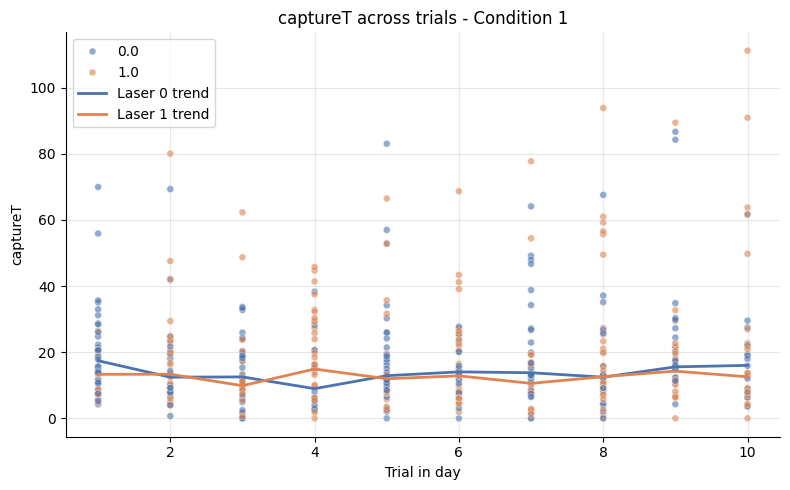

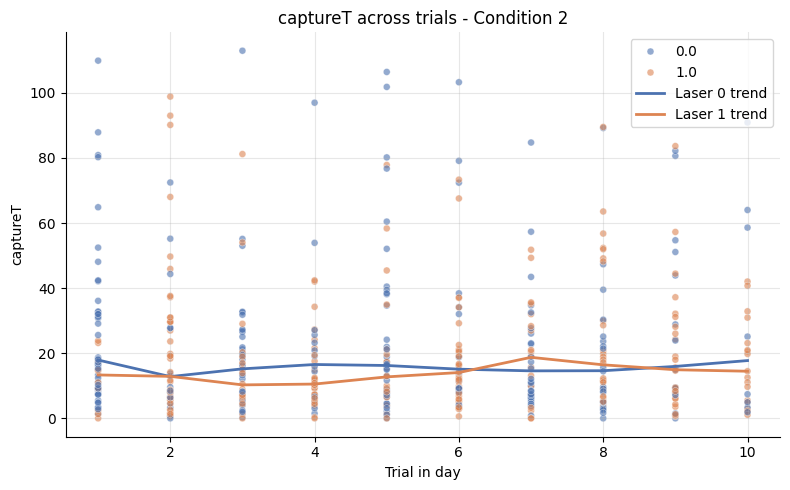

In [296]:
plot_capture_metric_across_trials(
    df=df,
    metric_col='captureT',
    max_trials=10  # optional
)


In [300]:
def plot_capture_metric_trials_grid(
    df,
    metric_col='captureT',
    condition_col='condition',
    laser_col='laser_value',
    mouse_col='mouse_id',
    day_col='day_in_condition',
    trial_col='trial_in_day',
    max_days=5,
    max_trials=None,
    conditions=('1', '2'),
    palette=None,
    figsize=(12, 10),
    smooth_frac=0.3,
    n_boot=200,
    outlier_method='iqr',   # method for detecting outliers
    outlier_mult=1.5
):
    """
    Plot capture metric trial-by-trial, separate subplot per day per condition.
    Scatter points colored by laser, LOWESS curves per laser with bootstrap CI.
    Outliers are removed from LOWESS but plotted as faded points.
    """

    if palette is None:
        palette = {0.0: '#4C72B0', 1.0: '#DD8452'}

    plot_df = df[df[condition_col].isin(conditions)].copy()
    plot_df = plot_df.dropna(subset=[metric_col, trial_col, laser_col, day_col])

    # Limit to first N days and optional max_trials
    plot_df = plot_df[plot_df[day_col] <= max_days]
    if max_trials is not None:
        plot_df = plot_df[plot_df[trial_col] <= max_trials]

    fig, axes = plt.subplots(max_days, len(conditions), figsize=figsize, sharex=True, sharey=True)
    if max_days == 1 and len(conditions) == 1:
        axes = np.array([[axes]])
    elif max_days == 1 or len(conditions) == 1:
        axes = axes.reshape(max_days, len(conditions))

    for i, day in enumerate(range(1, max_days + 1)):
        for j, cond in enumerate(conditions):
            ax = axes[i, j]
            day_cond_df = plot_df[(plot_df[day_col] == day) & (plot_df[condition_col] == cond)]

            for laser_val in day_cond_df[laser_col].unique():
                laser_df = day_cond_df[day_cond_df[laser_col] == laser_val].copy()

                # -------------------------
                # Detect outliers using IQR
                # -------------------------
                Q1 = laser_df[metric_col].quantile(0.25)
                Q3 = laser_df[metric_col].quantile(0.75)
                IQR = Q3 - Q1
                lower = Q1 - outlier_mult * IQR
                upper = Q3 + outlier_mult * IQR

                inliers = laser_df[(laser_df[metric_col] >= lower) & (laser_df[metric_col] <= upper)]
                outliers = laser_df[(laser_df[metric_col] < lower) | (laser_df[metric_col] > upper)]

                # -------------------------
                # Plot outliers as faded points
                # -------------------------
                if not outliers.empty:
                    ax.scatter(
                        outliers[trial_col],
                        outliers[metric_col],
                        color=palette[laser_val],
                        alpha=0.2,
                        s=25,
                        label='_nolegend_'
                    )

                x = inliers[trial_col].values
                y = inliers[metric_col].values

                if len(x) > 5:
                    # LOWESS fit
                    smooth = lowess(y, x, frac=smooth_frac)
                    ax.plot(smooth[:, 0], smooth[:, 1], color=palette[laser_val], lw=2)

                    # Bootstrap CI
                    boot_lines = []
                    for _ in range(n_boot):
                        idx = np.random.choice(len(x), size=len(x), replace=True)
                        y_boot = y[idx]
                        smooth_boot = lowess(y_boot, x[idx], frac=smooth_frac)
                        boot_lines.append(np.interp(smooth[:, 0], smooth_boot[:, 0], smooth_boot[:, 1]))
                    boot_lines = np.array(boot_lines)
                    lower_ci = np.percentile(boot_lines, 2.5, axis=0)
                    upper_ci = np.percentile(boot_lines, 97.5, axis=0)
                    ax.fill_between(smooth[:, 0], lower_ci, upper_ci, color=palette[laser_val], alpha=0.2)

            # Scatter all points (faded for inliers already plotted in LOWESS)
            ax.scatter(
                day_cond_df[day_cond_df[laser_col] == 0][trial_col],
                day_cond_df[day_cond_df[laser_col] == 0][metric_col],
                color=palette[0.0],
                alpha=0.6,
                s=25
            )
            ax.scatter(
                day_cond_df[day_cond_df[laser_col] == 1][trial_col],
                day_cond_df[day_cond_df[laser_col] == 1][metric_col],
                color=palette[1.0],
                alpha=0.6,
                s=25
            )

            ax.set_title(f'Condition {cond} - Day {day}')
            ax.set_xlabel('Trial in day')
            ax.set_ylabel(metric_col)
            ax.grid(alpha=0.3)
            sns.despine(ax=ax)

    # Legend
    handles = [plt.Line2D([0], [0], marker='o', color='w', label=f'Laser {int(k)}',
                          markerfacecolor=v, markersize=8) for k, v in palette.items()]
    axes[0, -1].legend(handles=handles, loc='upper right')

    plt.tight_layout()
    plt.show()


/opt/anaconda3/envs/preycapanalysis/lib/python3.9/site-packages/statsmodels/nonparametric/smoothers_lowess.py:226: RuntimeWarning: invalid value encountered in divide
  res, _ = _lowess(y, x, x, np.ones_like(x),
/opt/anaconda3/envs/preycapanalysis/lib/python3.9/site-packages/statsmodels/nonparametric/smoothers_lowess.py:226: RuntimeWarning: invalid value encountered in divide
  res, _ = _lowess(y, x, x, np.ones_like(x),
/opt/anaconda3/envs/preycapanalysis/lib/python3.9/site-packages/statsmodels/nonparametric/smoothers_lowess.py:226: RuntimeWarning: invalid value encountered in divide
  res, _ = _lowess(y, x, x, np.ones_like(x),
/opt/anaconda3/envs/preycapanalysis/lib/python3.9/site-packages/statsmodels/nonparametric/smoothers_lowess.py:226: RuntimeWarning: invalid value encountered in divide
  res, _ = _lowess(y, x, x, np.ones_like(x),
/opt/anaconda3/envs/preycapanalysis/lib/python3.9/site-packages/statsmodels/nonparametric/smoothers_lowess.py:226: RuntimeWarning: invalid value encount

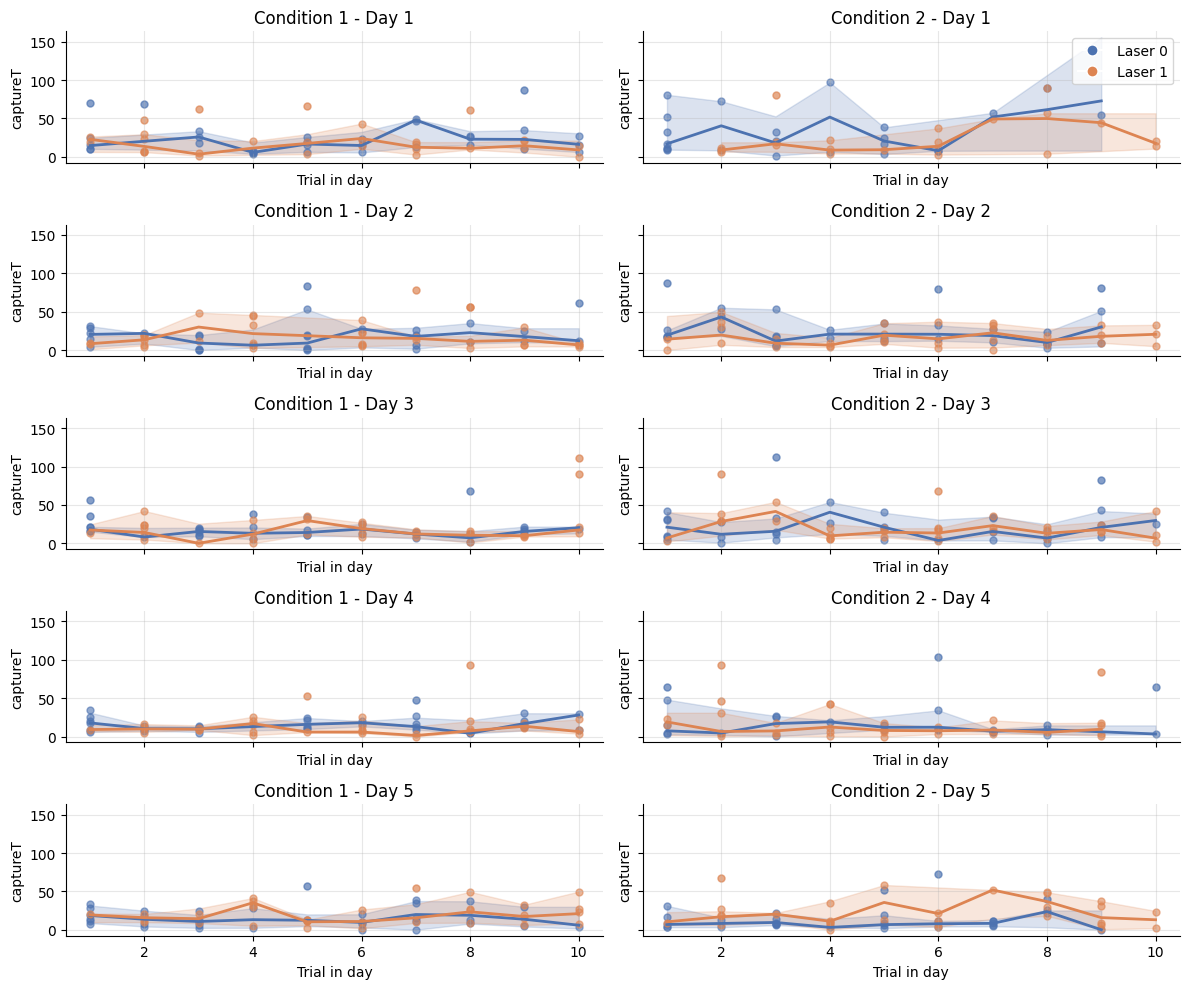

In [304]:
plot_capture_metric_trials_grid(
    df=df,
    metric_col='captureT',
    max_days=5,
    max_trials=10
)


In [330]:
# from statsmodels.nonparametric.smoothers_lowess import lowess
# import numpy as np
# import matplotlib.pyplot as plt
# import seaborn as sns

def plot_capture_metric_trials_collapsed(
    df,
    metric_col='captureT',
    condition_col='condition',
    laser_col='laser_value',
    day_col='day_in_condition',
    trial_col='trial_in_day',
    max_days=5,
    max_trials=None,
    conditions=('1', '2'),
    palette=None,
    smooth_frac=0.3,
    n_boot=200,
    outlier_mult=1.5,
    figsize=(10, 4),
    title=None
):
    """
    Plot trial-by-trial trends COLLAPSED across days (within condition),
    with LOWESS curves and bootstrap confidence intervals per laser value.
    """

    if palette is None:
        palette = {0.0: '#4C72B0', 1.0: '#DD8452'}

    plot_df = df[df[condition_col].isin(conditions)].copy()
    plot_df = plot_df.dropna(subset=[metric_col, trial_col, laser_col, day_col])
    plot_df = plot_df[plot_df[day_col] <= max_days]

    if max_trials is not None:
        plot_df = plot_df[plot_df[trial_col] <= max_trials]

    fig, axes = plt.subplots(1, len(conditions), figsize=figsize, sharey=True)
    if len(conditions) == 1:
        axes = [axes]

    for ax, cond in zip(axes, conditions):
        cond_df = plot_df[plot_df[condition_col] == cond]

        for laser_val in cond_df[laser_col].unique():
            laser_df = cond_df[cond_df[laser_col] == laser_val]

            # -------------------------
            # Outlier detection (IQR)
            # -------------------------
            Q1 = laser_df[metric_col].quantile(0.25)
            Q3 = laser_df[metric_col].quantile(0.75)
            IQR = Q3 - Q1
            lower = Q1 - outlier_mult * IQR
            upper = Q3 + outlier_mult * IQR

            inliers = laser_df[
                (laser_df[metric_col] >= lower) &
                (laser_df[metric_col] <= upper)
            ]
            outliers = laser_df[
                (laser_df[metric_col] < lower) |
                (laser_df[metric_col] > upper)
            ]

            # Plot outliers (faded)
            if not outliers.empty:
                ax.scatter(
                    outliers[trial_col],
                    outliers[metric_col],
                    color=palette[laser_val],
                    alpha=0.2,
                    s=25,
                    label='_nolegend_'
                )

            # Plot inlier scatter
            ax.scatter(
                inliers[trial_col],
                inliers[metric_col],
                color=palette[laser_val],
                alpha=0.6,
                s=25
            )

            x = inliers[trial_col].values
            y = inliers[metric_col].values

            if len(x) > 10:
                # LOWESS
                smooth = lowess(y, x, frac=smooth_frac)
                ax.plot(smooth[:, 0], smooth[:, 1],
                        color=palette[laser_val], lw=2)

                # Bootstrap CI
                boot_lines = []
                for _ in range(n_boot):
                    idx = np.random.choice(len(x), size=len(x), replace=True)
                    smooth_boot = lowess(y[idx], x[idx], frac=smooth_frac)
                    boot_lines.append(
                        np.interp(smooth[:, 0], smooth_boot[:, 0], smooth_boot[:, 1])
                    )

                boot_lines = np.array(boot_lines)
                lower_ci = np.percentile(boot_lines, 2.5, axis=0)
                upper_ci = np.percentile(boot_lines, 97.5, axis=0)

                ax.fill_between(
                    smooth[:, 0], lower_ci, upper_ci,
                    color=palette[laser_val], alpha=0.25
                )

        ax.set_title(f'Condition {cond}')
        ax.set_xlabel('Trial in day')
        ax.grid(alpha=0.3)
        sns.despine(ax=ax)

    axes[0].set_ylabel(metric_col)

    # Legend
    handles = [
        plt.Line2D([0], [0], color=v, lw=3, label=f'Laser {int(k)}')
        for k, v in palette.items()
    ]
    axes[-1].legend(handles=handles, loc='upper right')

    if title:
        fig.suptitle(title, y=1.05)

    plt.tight_layout()
    plt.show()


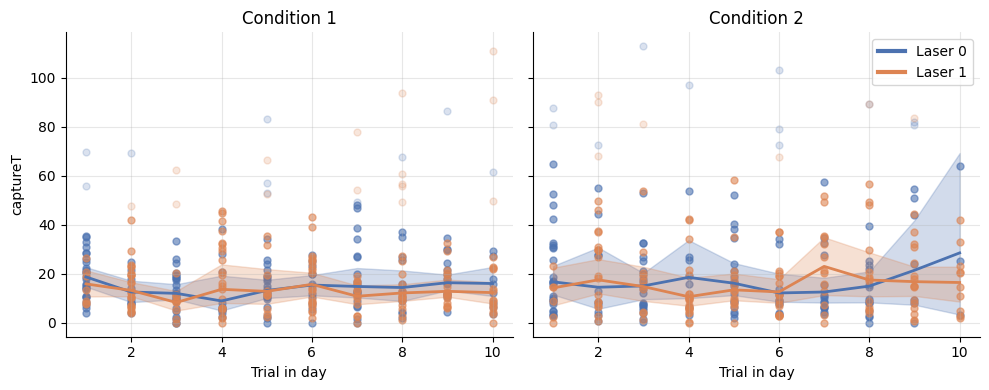

In [331]:
plot_capture_metric_trials_collapsed(
    df=df,
    metric_col='captureT',
    max_days=5,
    max_trials=10
)

In [305]:
def plot_capture_boxplots_trials(
    df,
    metric_col='captureT',
    condition_col='condition',
    laser_col='laser_value',
    mouse_col='mouse_id',
    day_col='day_in_condition',
    trial_col='trial_in_day',
    max_days=5,
    max_trials=None,
    conditions=('1', '2'),
    palette=None,
    figsize=(14, 10)
):
    """
    Plot box plots of capture metric per trial, per day and condition,
    colored by laser value, in a 5x2 grid (days x conditions).
    """

    if palette is None:
        palette = {0.0: '#4C72B0', 1.0: '#DD8452'}

    plot_df = df[df[condition_col].isin(conditions)].copy()
    plot_df = plot_df.dropna(subset=[metric_col, trial_col, laser_col, day_col])
    plot_df = plot_df[plot_df[day_col] <= max_days]

    if max_trials is not None:
        plot_df = plot_df[plot_df[trial_col] <= max_trials]

    fig, axes = plt.subplots(max_days, len(conditions), figsize=figsize, sharey=True, sharex=True)
    if max_days == 1 and len(conditions) == 1:
        axes = np.array([[axes]])
    elif max_days == 1 or len(conditions) == 1:
        axes = axes.reshape(max_days, len(conditions))

    for i, day in enumerate(range(1, max_days + 1)):
        for j, cond in enumerate(conditions):
            ax = axes[i, j]
            day_cond_df = plot_df[(plot_df[day_col] == day) & (plot_df[condition_col] == cond)]

            sns.boxplot(
                data=day_cond_df,
                x=trial_col,
                y=metric_col,
                hue=laser_col,
                palette=palette,
                ax=ax,
                width=0.6,
                showfliers=True  # shows outliers
            )

            ax.set_title(f'Condition {cond} - Day {day}')
            ax.set_xlabel('Trial in day')
            if j == 0:
                ax.set_ylabel(metric_col)
            else:
                ax.set_ylabel('')
            ax.grid(alpha=0.3)
            sns.despine(ax=ax)

    # Legend
    handles, labels = axes[0, -1].get_legend_handles_labels()
    axes[0, -1].legend(handles=handles, labels=[f'Laser {l}' for l in labels], loc='upper right')

    plt.tight_layout()
    plt.show()


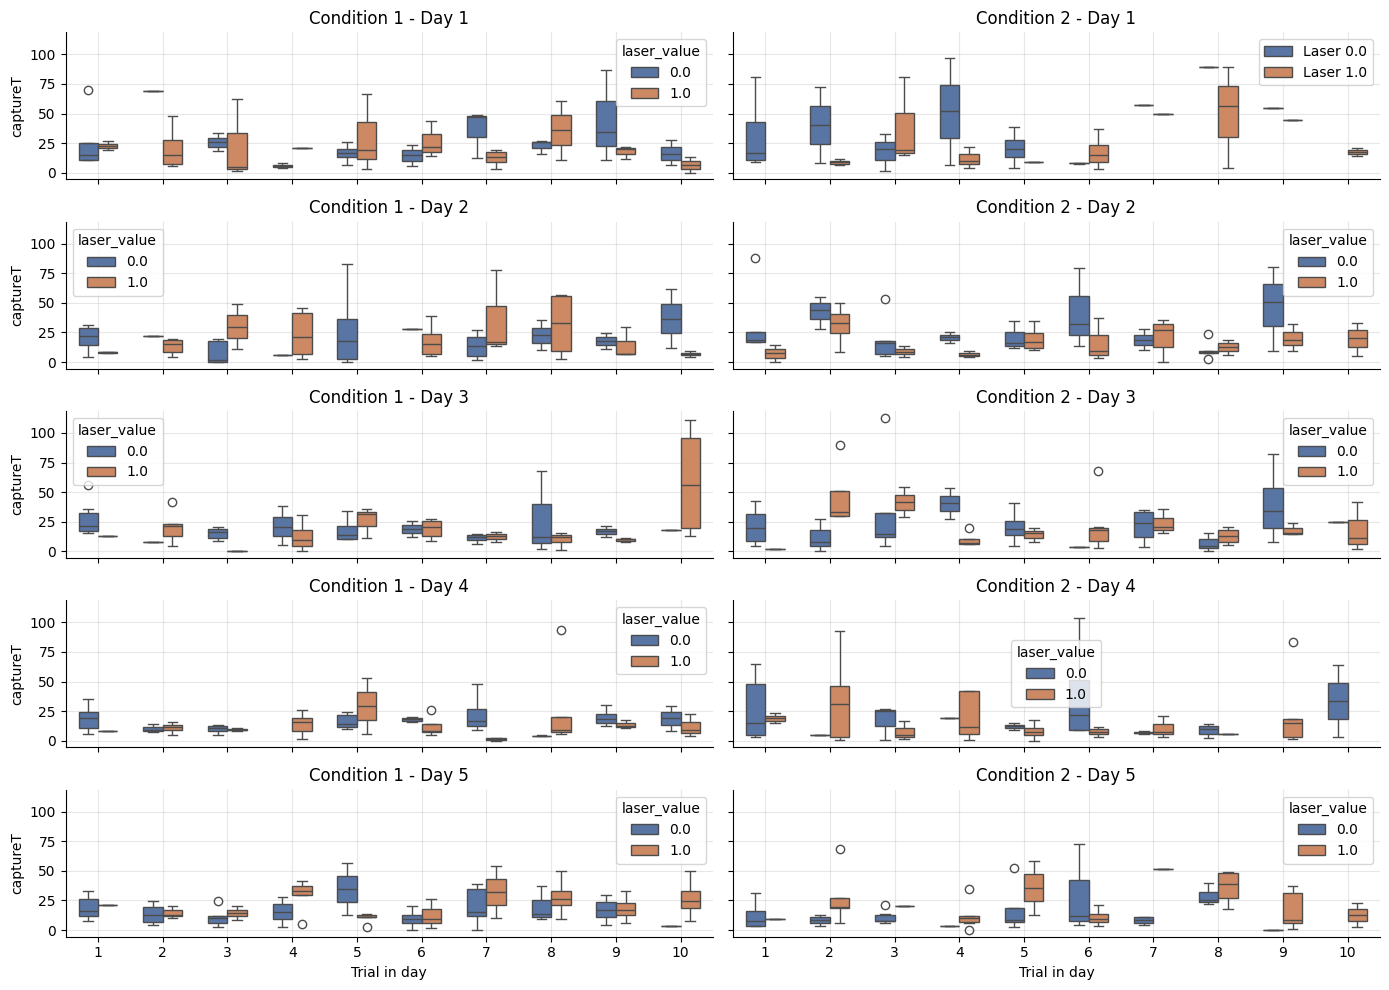

In [306]:
plot_capture_boxplots_trials(
    df=df,
    metric_col='captureT',
    max_days=5,
    max_trials=10
)

### looking at failure rate across days and trials as well

In [318]:
def compute_failure_rate(
    df,
    metric_col='captureT',
    mouse_col='mouse_id',
    condition_col='condition',
    laser_col='laser_value',
    day_col='day_in_condition',
    max_days=5
):
    """
    Compute failure rate (fraction of NaN metric values)
    per mouse × condition × laser × day.
    """

    tmp = df.copy()
    tmp = tmp[tmp[day_col] <= max_days]

    # Trial is a failure if metric is NaN
    tmp['failed'] = tmp[metric_col].isna().astype(int)

    failure_df = (
        tmp
        .groupby([mouse_col, condition_col, laser_col, day_col])
        .agg(
            n_trials=(metric_col, 'size'),
            n_failures=('failed', 'sum')
        )
        .reset_index()
    )

    failure_df['failure_rate'] = (
        failure_df['n_failures'] / failure_df['n_trials']
    )

    return failure_df

def plot_failure_rate_across_days(
    failure_df,
    condition_col='condition',
    laser_col='laser_value',
    day_col='day_in_condition',
    conditions=('1', '2'),
    palette=None,
    figsize=(6, 4),
    title='Failure rate across days'
):
    """
    Plot failure rate across days WITHIN condition,
    comparing laser ON vs OFF.
    """

    if palette is None:
        palette = {
            0.0: '#4C72B0',  # laser OFF
            1.0: '#DD8452'   # laser ON
        }

    plot_df = failure_df[failure_df[condition_col].isin(conditions)].copy()

    # Population summary (mouse-level)
    summary = (
        plot_df
        .groupby([condition_col, laser_col, day_col])['failure_rate']
        .agg(['mean', 'sem'])
        .reset_index()
    )

    g = sns.FacetGrid(
        summary,
        col=condition_col,
        col_order=list(conditions),
        hue=laser_col,
        palette=palette,
        height=figsize[1],
        aspect=1.2,
        sharex=True,
        sharey=True
    )

    g.map_dataframe(
        sns.lineplot,
        x=day_col,
        y='mean',
        marker='o'
    )

    for ax, cond in zip(g.axes.flat, conditions):
        for laser in summary[laser_col].unique():
            sub = summary[
                (summary[condition_col] == cond) &
                (summary[laser_col] == laser)
            ]
            ax.errorbar(
                sub[day_col],
                sub['mean'],
                yerr=sub['sem'],
                fmt='none',
                capsize=3,
                alpha=0.7
            )

        ax.set_ylim(0, 1)

    g.add_legend(title='Laser')
    g.set_axis_labels('Day in condition', 'Failure rate')
    g.set_titles('Condition {col_name}')

    if title:
        g.fig.suptitle(title, y=1.05)

    sns.despine()
    plt.ylim(-0.05,0.25)
    plt.tight_layout()
    plt.show()


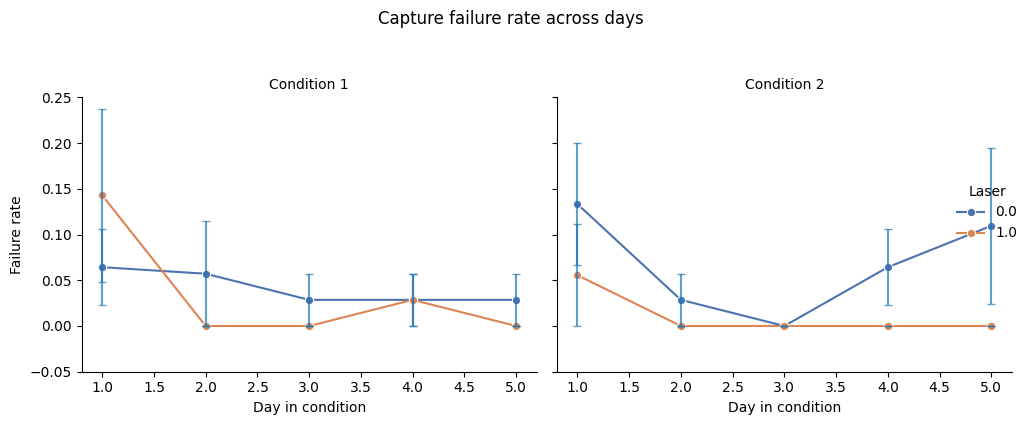

In [319]:
failure_df = compute_failure_rate(
    df=df,
    metric_col='captureT',   # or 'corrected_capduration'
    max_days=5
)

plot_failure_rate_across_days(
    failure_df,
    title='Capture failure rate across days'
)


In [322]:
def compute_trial_failure_rate(
    df,
    metric_col='captureT',
    mouse_col='mouse_id',
    condition_col='condition',
    laser_col='laser_value',
    day_col='day_in_condition',
    trial_col='trial_in_day',
    max_days=5
):
    """
    Compute failure rate per trial index within day,
    aggregated across mice.
    """

    tmp = df.copy()
    tmp = tmp[tmp[day_col] <= max_days]

    # Failure indicator
    tmp['failed'] = tmp[metric_col].isna().astype(int)

    # Mouse-level trial failure
    mouse_trial = (
        tmp
        .groupby([
            mouse_col,
            condition_col,
            laser_col,
            day_col,
            trial_col
        ])['failed']
        .mean()   # mean is 0 or 1 at mouse-level
        .reset_index()
    )

    # Population summary across mice
    summary = (
        mouse_trial
        .groupby([
            condition_col,
            laser_col,
            day_col,
            trial_col
        ])['failed']
        .agg(['mean', 'sem', 'count'])
        .reset_index()
        .rename(columns={'mean': 'failure_rate'})
    )

    return summary

def plot_trial_failure_grid(
    failure_df,
    condition_col='condition',
    laser_col='laser_value',
    day_col='day_in_condition',
    trial_col='trial_in_day',
    conditions=('1', '2'),
    palette=None,
    figsize=(14, 10),
    title='Trial-wise failure rate within day'
):
    """
    Plot failure rate per trial index in a 5x2 grid:
    rows = days, columns = conditions
    """

    if palette is None:
        palette = {
            0.0: '#4C72B0',  # laser OFF
            1.0: '#DD8452'   # laser ON
        }

    max_days = failure_df[day_col].max()

    fig, axes = plt.subplots(
        max_days,
        len(conditions),
        figsize=figsize,
        sharex=True,
        sharey=True
    )

    if max_days == 1:
        axes = axes[np.newaxis, :]

    for i, day in enumerate(sorted(failure_df[day_col].unique())):
        for j, cond in enumerate(conditions):
            ax = axes[i, j]

            sub = failure_df[
                (failure_df[day_col] == day) &
                (failure_df[condition_col] == cond)
            ]

            for laser in sorted(sub[laser_col].unique()):
                laser_sub = sub[sub[laser_col] == laser]

                ax.plot(
                    laser_sub[trial_col],
                    laser_sub['failure_rate'],
                    marker='o',
                    color=palette[laser],
                    label=f'Laser {int(laser)}'
                )

                ax.fill_between(
                    laser_sub[trial_col],
                    laser_sub['failure_rate'] - laser_sub['sem'],
                    laser_sub['failure_rate'] + laser_sub['sem'],
                    color=palette[laser],
                    alpha=0.25
                )

            ax.set_ylim(0, 1)
            ax.set_title(f'Cond {cond} – Day {day}')
            ax.grid(alpha=0.3)

            if i == max_days - 1:
                ax.set_xlabel('Trial in day')
            if j == 0:
                ax.set_ylabel('Failure rate')

            sns.despine(ax=ax)

    handles = [
        plt.Line2D([0], [0], color=palette[l], marker='o', label=f'Laser {int(l)}')
        for l in palette
    ]
    fig.legend(
        handles=handles,
        loc='upper right',
        title='Laser'
    )

    fig.suptitle(title, y=1.02)
    plt.ylim(-0.05, 1)
    plt.tight_layout()
    plt.show()


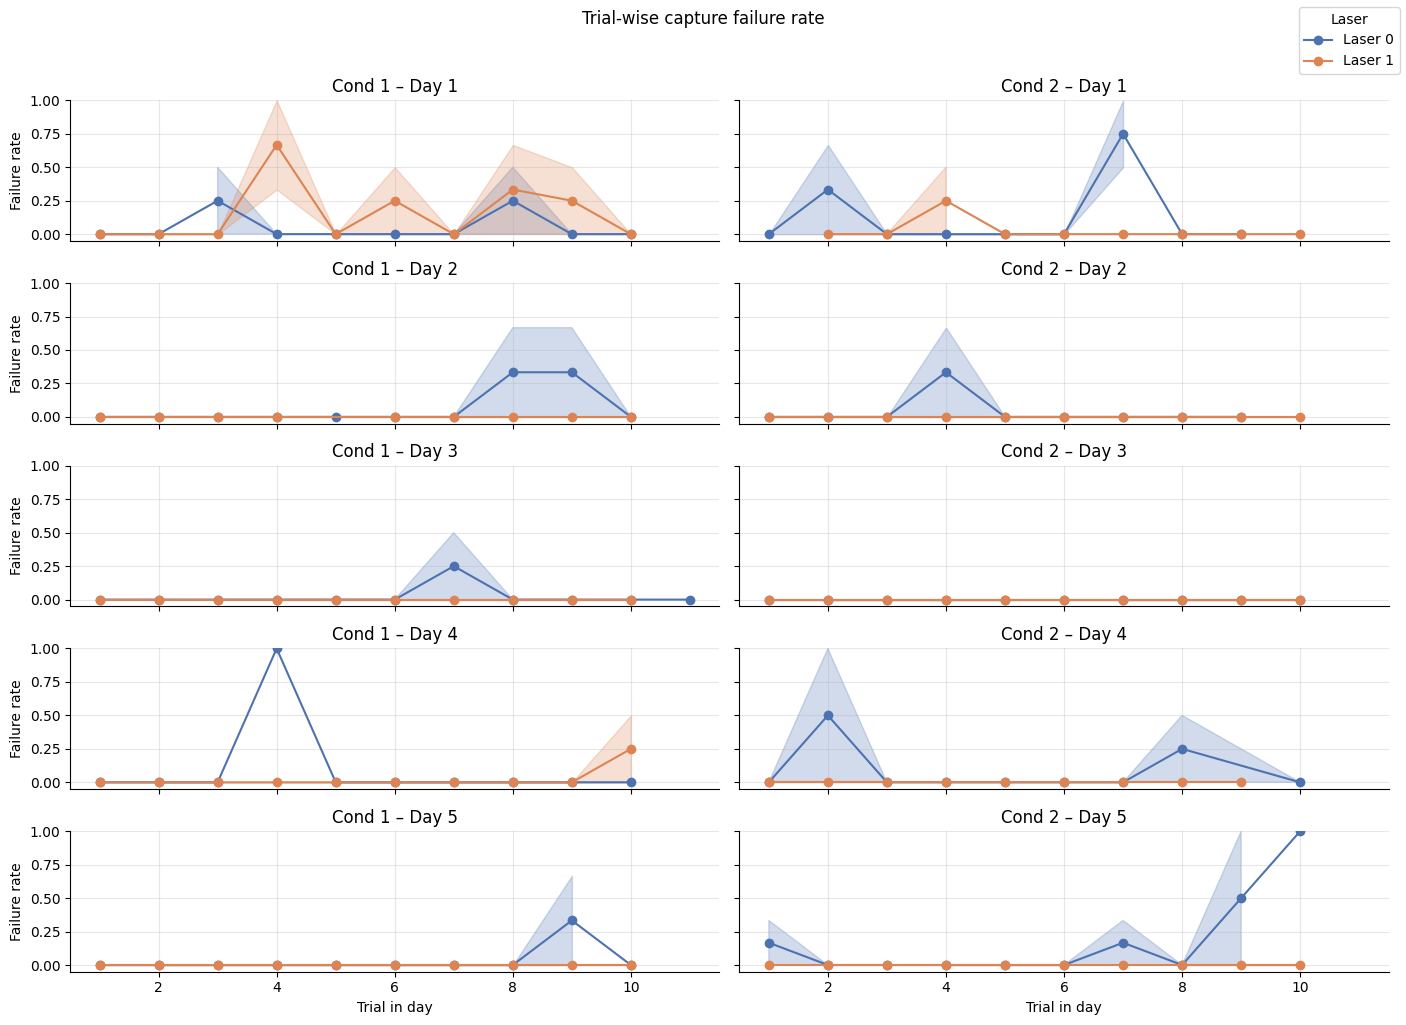

In [323]:
trial_failure_df = compute_trial_failure_rate(
    df=df,
    metric_col='captureT',   # or 'corrected_capduration'
    max_days=5
)

plot_trial_failure_grid(
    trial_failure_df,
    title='Trial-wise capture failure rate'
)


### look at whether the inital range has any impact on the capture time and duration

/var/folders/nz/8m30wy3d4w7dp3wwjxvnj47r0000gn/T/ipykernel_12726/352619183.py:24: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cleaned_conds_keep['dist_50_after_drop'] = np.nan


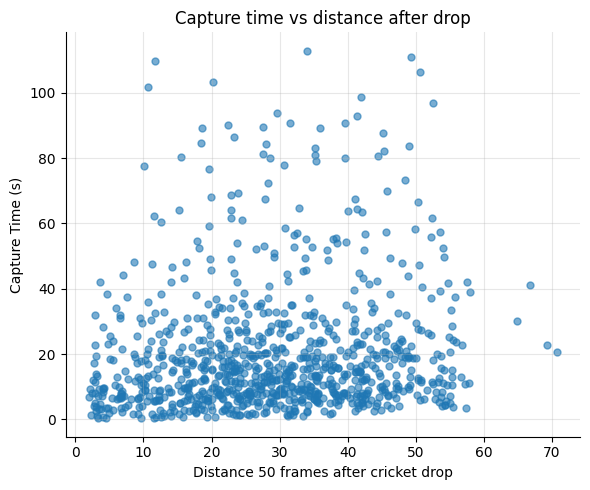

In [235]:
FRAME_OFFSET = 50

def dist_after_drop(dist, drop, offset=FRAME_OFFSET):
    try:
        dist_arr = np.asarray(dist, dtype=float)
    except Exception:
        return np.nan

    idx = int(drop + offset)

    if idx < 0 or idx >= len(dist_arr):
        return np.nan

    return dist_arr[idx]

mask = (
    cleaned_conds_keep['dist'].notna() &
    cleaned_conds_keep['cricketdrop'].notna() &
    cleaned_conds_keep['captureT'].notna() &
    (cleaned_conds_keep['cricketdrop'] + FRAME_OFFSET
     < cleaned_conds_keep['dist'].str.len())
)

cleaned_conds_keep['dist_50_after_drop'] = np.nan

for i in cleaned_conds_keep.index[mask]:
    cleaned_conds_keep.at[i, 'dist_50_after_drop'] = dist_after_drop(
        cleaned_conds_keep.at[i, 'dist'],
        cleaned_conds_keep.at[i, 'cricketdrop']
    )

mask.sum(), len(cleaned_conds_keep)

plot_df = cleaned_conds_keep.dropna(
    subset=['dist_50_after_drop', 'captureT']
)

plt.figure(figsize=(6,5))
plt.scatter(
    plot_df['dist_50_after_drop'],
    plot_df['captureT'],
    alpha=0.6,
    s=25
)

plt.xlabel('Distance 50 frames after cricket drop')
plt.ylabel('Capture Time (s)')
plt.title('Capture time vs distance after drop')
# plt.ylim(0,20)
# plt.xlim(0,20)
plt.grid(alpha=0.3)
plt.tight_layout()
sns.despine()
plt.show()

In [248]:
FRAME_OFFSET = 50

def dist_after_drop(dist, drop, offset=FRAME_OFFSET):
    try:
        dist_arr = np.asarray(dist, dtype=float)
    except Exception:
        return np.nan

    idx = int(drop + offset)

    if idx < 0 or idx >= len(dist_arr):
        return np.nan

    return dist_arr[idx]

mask = (
    cleaned_conds_keep['dist'].notna() &
    cleaned_conds_keep['cricketdrop'].notna() &
    cleaned_conds_keep['captureT'].notna() &
    (cleaned_conds_keep['cricketdrop'] + FRAME_OFFSET
     < cleaned_conds_keep['dist'].str.len())
)

cleaned_conds_keep['dist_50_after_drop'] = np.nan

for i in cleaned_conds_keep.index[mask]:
    cleaned_conds_keep.at[i, 'dist_50_after_drop'] = dist_after_drop(
        cleaned_conds_keep.at[i, 'dist'],
        cleaned_conds_keep.at[i, 'cricketdrop']
    )

mask.sum(), len(cleaned_conds_keep)

plot_df = cleaned_conds_keep.dropna(
    subset=['dist_50_after_drop', 'captureT']
).copy()

plot_df = plot_df[plot_df['condition'].isin(['1', '2'])]

## plotting


plot_df = cleaned_conds_keep.dropna(
    subset=['dist_50_after_drop', 'captureT']
).copy()

plot_df = plot_df[plot_df['condition'].isin(['1', '2'])]

# import numpy as np
# import seaborn as sns
# import matplotlib.pyplot as plt
from statsmodels.nonparametric.smoothers_lowess import lowess


def plot_capture_vs_distance_lowess(
    df,
    metric_col='captureT',
    dist_col='dist_50_after_drop',
    condition_col='condition',
    laser_col='laser_value',
    conditions=('1', '2'),
    frac=0.3,          # LOWESS smoothing parameter
    min_n=10,
    palette=None,
    figsize=(4, 4),
    title=None
):
    """
    Faceted scatter plot of capture metric vs distance with LOWESS curves
    per laser value, one panel per condition.
    """

    if palette is None:
        palette = {
            1.0: '#2976bb',  # laser OFF
            0.0: '#929591'   # laser ON
        }

    plot_df = (
        df[[dist_col, metric_col, condition_col, laser_col]]
        .dropna()
        .copy()
    )

    plot_df = plot_df[plot_df[condition_col].isin(conditions)]

    # ----------------------------
    # FacetGrid
    # ----------------------------
    g = sns.FacetGrid(
        plot_df,
        col=condition_col,
        col_order=list(conditions),
        hue=laser_col,
        palette=palette,
        height=figsize[1],
        aspect=1,
        sharex=True,
        sharey=True
    )

    # Scatter points
    g.map_dataframe(
        sns.scatterplot,
        x=dist_col,
        y=metric_col,
        alpha=0.5,
        s=30
    )

    # ----------------------------
    # LOWESS overlay
    # ----------------------------
    def add_lowess(data, color, **kwargs):
        if len(data) < min_n:
            return
        x = data[dist_col].values
        y = data[metric_col].values

        order = np.argsort(x)
        smoothed = lowess(
            y[order],
            x[order],
            frac=frac,
            return_sorted=True
        )

        plt.plot(
            smoothed[:, 0],
            smoothed[:, 1],
            color=color,
            lw=2
        )

    g.map_dataframe(add_lowess)

    # ----------------------------
    # Formatting
    # ----------------------------
    g.add_legend(title='Laser')

    g.set_axis_labels(
        'Distance 50 frames after cricket drop',
        metric_col
    )

    g.set_titles('Condition {col_name}')

    for ax in g.axes.flat:
        ax.grid(alpha=0.3)

    if title:
        g.fig.suptitle(title, y=1.05)

    sns.despine()
    plt.tight_layout()
    plt.show()


/var/folders/nz/8m30wy3d4w7dp3wwjxvnj47r0000gn/T/ipykernel_12726/2657190896.py:24: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cleaned_conds_keep['dist_50_after_drop'] = np.nan


In [249]:
palette=['#2976bb','#929591']

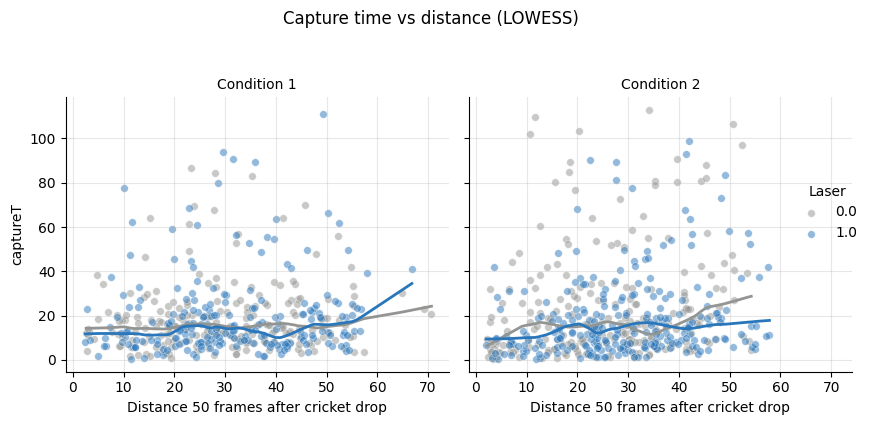

In [250]:
plot_capture_vs_distance_lowess(
    cleaned_conds_keep,
    metric_col='captureT',
    frac=0.25,
    title='Capture time vs distance (LOWESS)'
)


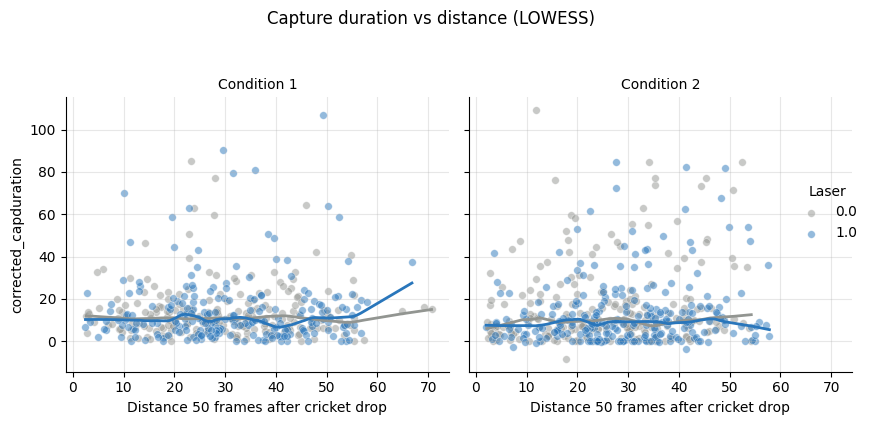

In [329]:
plot_capture_vs_distance_lowess(
    cleaned_conds_keep,
    metric_col='corrected_capduration',
    frac=0.25,
    title='Capture duration vs distance (LOWESS)'
)


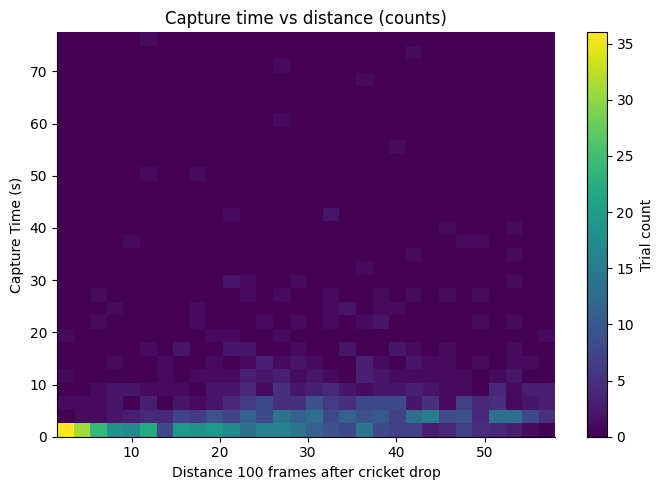

In [134]:
plt.figure(figsize=(7, 5))

h = plt.hist2d(
    plot_df['dist_100_after_drop'],
    plot_df['corrected_timetointercept'],
    bins=[30, 30],   # adjust bin resolution
    cmap='viridis'
)


plt.xlabel('Distance 100 frames after cricket drop')
plt.ylabel('Capture Time (s)')
plt.title('Capture time vs distance (counts)')
plt.colorbar(h[3], label='Trial count')
# plt.ylim(0,30)
# plt.xlim(1,30)
sns.despine()
plt.tight_layout()
plt.show()

In [136]:
def plot_metric_by_distance_bins(
    df,
    dist_col='dist_100_after_drop',
    metric_col='corrected_timetointercept',
    max_dist=60,
    dist_bin_size=2,
    metric_bin_size=10,
    plot_type='stacked',   # 'stacked' or 'heatmap'
    metric_label='Metric (s)',
    title=None,
):
    """
    Plot percentage distribution of a metric across distance bins.

    Percentages are normalized WITHIN each distance bin.

    Parameters
    ----------
    df : pandas.DataFrame
    dist_col : str
        Column containing distance values
    metric_col : str
        Column to bin and plot (e.g. capture time)
    max_dist : float
        Maximum distance to include
    dist_bin_size : float
        Bin width for distance
    metric_bin_size : float
        Bin width for metric (e.g. seconds)
    plot_type : str
        'stacked' or 'heatmap'
    metric_label : str
        Label for legend / y-axis
    title : str
        Plot title
    """

    # ----------------------------
    # Filter + cleanup
    # ----------------------------
    plot_df = (
        df[[dist_col, metric_col]]
        .dropna()
        .copy()
    )

    plot_df = plot_df[plot_df[dist_col] <= max_dist]

    if plot_df.empty:
        print("No data left after filtering.")
        return

    # ----------------------------
    # Define bins
    # ----------------------------
    dist_bins = np.arange(0, max_dist + dist_bin_size, dist_bin_size)

    max_metric = np.ceil(plot_df[metric_col].max() / metric_bin_size) * metric_bin_size
    metric_bins = np.arange(0, max_metric + metric_bin_size, metric_bin_size)

    metric_labels = [
        f'{int(metric_bins[i])}–{int(metric_bins[i+1])}'
        for i in range(len(metric_bins) - 1)
    ]

    # ----------------------------
    # Bin the data
    # ----------------------------
    plot_df['dist_bin'] = pd.cut(
        plot_df[dist_col],
        bins=dist_bins
    )

    plot_df['metric_bin'] = pd.cut(
        plot_df[metric_col],
        bins=metric_bins,
        labels=metric_labels,
        right=False
    )

    # ----------------------------
    # Count & normalize
    # ----------------------------
    counts = (
        plot_df
        .groupby(['dist_bin', 'metric_bin'])
        .size()
        .unstack(fill_value=0)
    )

    percentages = counts.div(counts.sum(axis=1), axis=0) * 100

    # ----------------------------
    # Plot
    # ----------------------------
    if plot_type == 'stacked':
        percentages.plot(
            kind='bar',
            stacked=True,
            figsize=(10, 5),
            colormap='Spectral'
        )

        plt.ylabel('Percentage of trials (%)')
        plt.xlabel('Distance bin')
        plt.legend(
            title=metric_label,
            bbox_to_anchor=(1.05, 1),
            loc='upper left'
        )

    elif plot_type == 'heatmap':
        plt.figure(figsize=(8, 5))
        sns.heatmap(
            percentages.T,
            cmap='Spectral',
            annot=True,
            fmt='.1f',
            cbar_kws={'label': 'Percentage (%)'}
        )

        plt.xlabel('Distance bin')
        plt.ylabel(metric_label)

    else:
        raise ValueError("plot_type must be 'stacked' or 'heatmap'")

    if title is not None:
        plt.title(title)

    plt.tight_layout()
    plt.show()


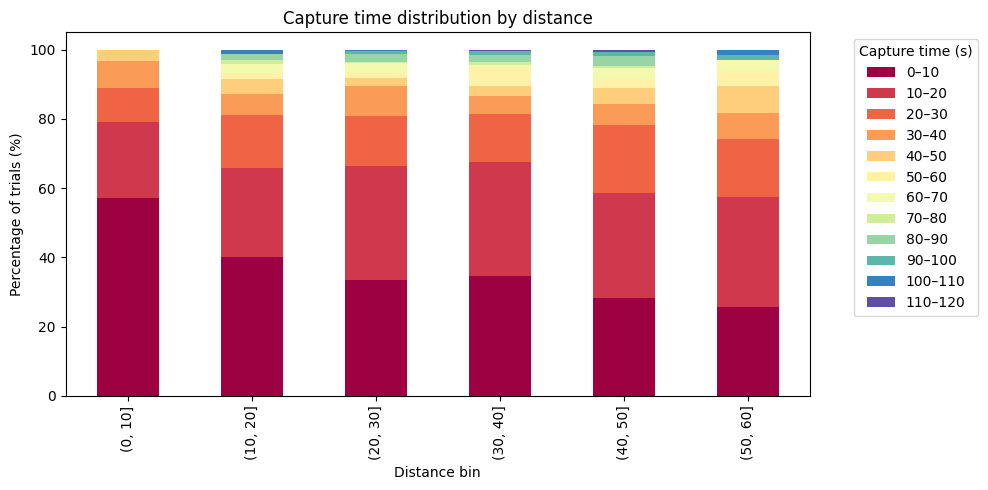

In [137]:
plot_metric_by_distance_bins(
    cleaned_conds_keep,
    metric_col='captureT',
    metric_label='Capture time (s)',
    metric_bin_size=10,
    dist_bin_size=10,
    plot_type='stacked',
    title='Capture time distribution by distance'
)


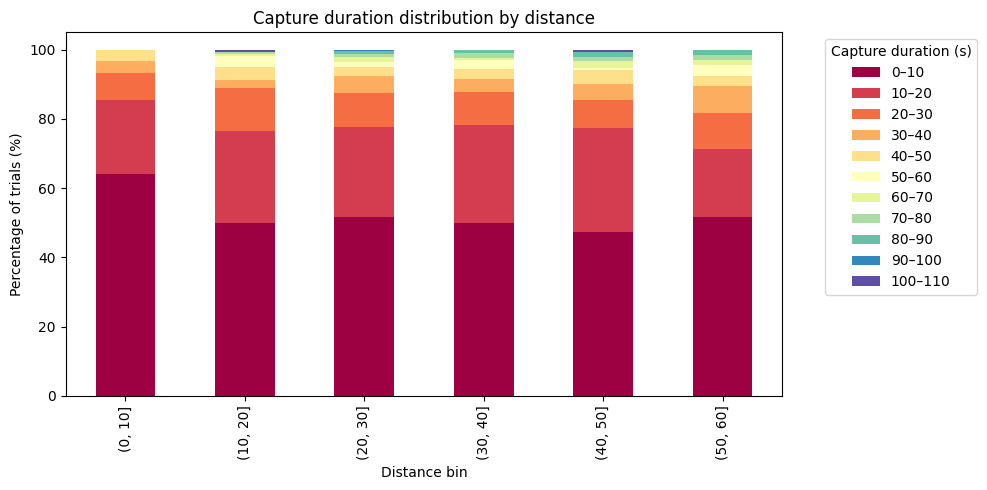

In [138]:
plot_metric_by_distance_bins(
    cleaned_conds_keep,
    metric_col='corrected_capduration',
    metric_label='Capture duration (s)',
    metric_bin_size=10,
    dist_bin_size=10,
    plot_type='stacked',
    title='Capture duration distribution by distance'
)

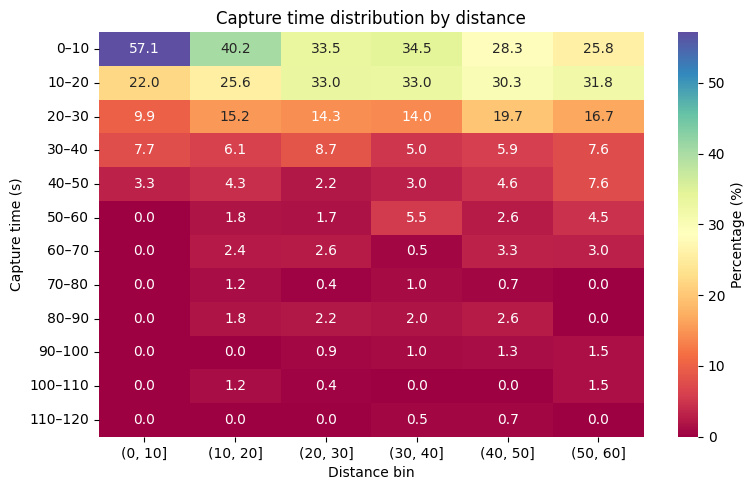

In [139]:
plot_metric_by_distance_bins(
    cleaned_conds_keep,
    metric_col='captureT',
    metric_label='Capture time (s)',
    metric_bin_size=10,
    dist_bin_size=10,
    plot_type='heatmap',
    title='Capture time distribution by distance'
)

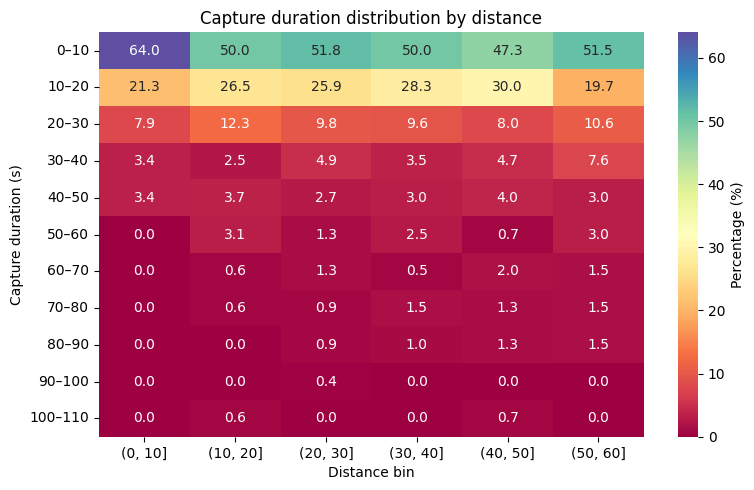

In [140]:
plot_metric_by_distance_bins(
    cleaned_conds_keep,
    metric_col='corrected_capduration',
    metric_label='Capture duration (s)',
    metric_bin_size=10,
    dist_bin_size=10,
    plot_type='heatmap',
    title='Capture duration distribution by distance'
)

In [141]:
# import pandas as pd
# import numpy as np
from scipy.stats import shapiro, levene, f_oneway, kruskal
import scikit_posthocs as sp

def distance_bin_statistics(df, dist_col='dist_bin', metric_col='corrected_timetointercept'):
    """
    Perform statistics to compare metric across distance bins.
    
    Parameters
    ----------
    df : pd.DataFrame
        Must include 'dist_bin' (categorical) and metric column.
    dist_col : str
        Column for distance bins
    metric_col : str
        Continuous variable to compare across bins
    
    Returns
    -------
    results : dict
        Contains:
        - 'normality': Shapiro p-values per bin
        - 'variance_homogeneity': Levene test p
        - 'overall_test': ANOVA or Kruskal-Wallis result
        - 'posthoc': Dunn test results (Bonferroni)
    """
    
    # --------------------------
    # Filter out bins with <3 trials
    # --------------------------
    valid_bins = df.groupby(dist_col).filter(lambda x: len(x) >= 3)
    
    if valid_bins.empty:
        raise ValueError("No distance bins have >= 3 trials. Adjust binning or filter criteria.")
    
    # --------------------------
    # Normality (Shapiro) per bin
    # --------------------------
    normality = {}
    for name, group in valid_bins.groupby(dist_col):
        stat, p = shapiro(group[metric_col])
        normality[name] = p
    
    # --------------------------
    # Homogeneity of variances (Levene)
    # --------------------------
    groups_list = [group[metric_col].values for _, group in valid_bins.groupby(dist_col)]
    stat_levene, p_levene = levene(*groups_list)
    
    # --------------------------
    # Decide test
    # --------------------------
    normal = all(p>0.05 for p in normality.values())
    equal_var = p_levene > 0.05
    
    if normal and equal_var:
        # Parametric ANOVA
        stat_overall, p_overall = f_oneway(*groups_list)
        test_name = 'ANOVA'
    else:
        # Non-parametric Kruskal-Wallis
        stat_overall, p_overall = kruskal(*groups_list)
        test_name = 'Kruskal-Wallis'
    
    # --------------------------
    # Post-hoc (Dunn's test, Bonferroni)
    # --------------------------
    # Convert distance bin to categorical codes for Dunn
    valid_bins = valid_bins.copy()
    valid_bins['dist_bin_code'] = valid_bins[dist_col].astype('category').cat.codes
    dunn = sp.posthoc_dunn(
        valid_bins,
        val_col=metric_col,
        group_col='dist_bin_code',
        p_adjust='bonferroni'
    )
    
    # Rename rows/cols to distance bin labels
    dunn.index = valid_bins[dist_col].astype('category').cat.categories
    dunn.columns = valid_bins[dist_col].astype('category').cat.categories
    
    # --------------------------
    # Return results
    # --------------------------
    results = {
        'normality': normality,
        'variance_homogeneity_p': p_levene,
        'overall_test': {'test': test_name, 'stat': stat_overall, 'p': p_overall},
        'posthoc': dunn
    }
    
    return results


In [142]:
# Make sure your df has distance bins (like in the plotting script)
plot_df = cleaned_conds_keep.dropna(subset=['dist_100_after_drop', 'captureT']).copy()
plot_df = plot_df[plot_df['dist_100_after_drop'] <= 60]

# Create distance bins (10-unit bins)
plot_df['dist_bin'] = pd.cut(plot_df['dist_100_after_drop'], bins=np.arange(0, 70, 10))

# Run statistics
stats_results = distance_bin_statistics(plot_df)

# View outputs
print("Normality per bin (Shapiro p-values):")
print(stats_results['normality'])
print("\nLevene p (variance homogeneity):", stats_results['variance_homogeneity_p'])
print("\nOverall test result:")
print(stats_results['overall_test'])
print("\nPost-hoc Dunn test (Bonferroni corrected):")
print(stats_results['posthoc'])


Normality per bin (Shapiro p-values):
{Interval(0, 10, closed='right'): 1.7443891275741765e-15, Interval(10, 20, closed='right'): 2.155809276741507e-21, Interval(20, 30, closed='right'): 3.1171466608395374e-23, Interval(30, 40, closed='right'): 4.870552964984922e-22, Interval(40, 50, closed='right'): 8.159464292910633e-19, Interval(50, 60, closed='right'): 2.911647153674884e-11}

Levene p (variance homogeneity): 0.1683503965881913

Overall test result:
{'test': 'Kruskal-Wallis', 'stat': 145.90368083457128, 'p': 9.936540099991731e-30}

Post-hoc Dunn test (Bonferroni corrected):
               (0, 10]      (10, 20]      (20, 30]      (30, 40]  \
(0, 10]   1.000000e+00  6.301113e-06  5.324516e-15  1.476995e-18   
(10, 20]  6.301113e-06  1.000000e+00  9.813977e-03  5.392863e-05   
(20, 30]  5.324516e-15  9.813977e-03  1.000000e+00  1.000000e+00   
(30, 40]  1.476995e-18  5.392863e-05  1.000000e+00  1.000000e+00   
(40, 50]  1.505839e-23  7.890491e-09  1.178321e-02  7.452510e-01   
(50, 60]

In [143]:
import pandas as pd

def summarize_dunn(dunn_matrix, df, dist_col='dist_bin', metric_col='corrected_timetointercept', alpha=0.05):
    """
    Summarize significant pairwise comparisons from a Dunn post-hoc matrix.
    
    Parameters
    ----------
    dunn_matrix : pd.DataFrame
        Dunn test p-values, rows/cols = distance bins
    df : pd.DataFrame
        Original data with distance bins and metric
    dist_col : str
        Column name for distance bins
    metric_col : str
        Column name for metric
    alpha : float
        Significance threshold (default 0.05)
    
    Returns
    -------
    summary : pd.DataFrame
        Columns: Bin 1, Bin 2, p-value, Mean Bin 1, Mean Bin 2, Direction
    """
    
    results = []
    # Iterate over upper triangle (no duplicates)
    bins = dunn_matrix.index
    for i in range(len(bins)):
        for j in range(i+1, len(bins)):
            bin1 = bins[i]
            bin2 = bins[j]
            pval = dunn_matrix.loc[bin1, bin2]
            if pval < alpha:
                mean1 = df[df[dist_col] == bin1][metric_col].mean()
                mean2 = df[df[dist_col] == bin2][metric_col].mean()
                if mean1 > mean2:
                    direction = f"{bin1} > {bin2}"
                elif mean1 < mean2:
                    direction = f"{bin1} < {bin2}"
                else:
                    direction = "equal"
                
                results.append({
                    'Bin 1': bin1,
                    'Bin 2': bin2,
                    'p-value': pval,
                    f'Mean {bin1}': mean1,
                    f'Mean {bin2}': mean2,
                    'Direction': direction
                })
    
    summary = pd.DataFrame(results)
    return summary


In [144]:
summary = summarize_dunn(stats_results['posthoc'], plot_df)
pd.set_option('display.max_rows', None)  # show all rows
summary


,Bin 1,Bin 2,p-value,"Mean (0, 10]","Mean (10, 20]",Direction,"Mean (20, 30]","Mean (30, 40]","Mean (40, 50]","Mean (50, 60]"
0,"(0, 10]","(10, 20]",6.301113e-06,2.15033,5.279238,"(0, 10] < (10, 20]",NaN,NaN,NaN,NaN
1,"(0, 10]","(20, 30]",5.324516e-15,2.15033,NaN,"(0, 10] < (20, 30]",5.763565,NaN,NaN,NaN
2,"(0, 10]","(30, 40]",1.476995e-18,2.15033,NaN,"(0, 10] < (30, 40]",NaN,6.1785,NaN,NaN
3,"(0, 10]","(40, 50]",1.505839e-23,2.15033,NaN,"(0, 10] < (40, 50]",NaN,NaN,7.241086,NaN
4,"(0, 10]","(50, 60]",7.303317e-18,2.15033,NaN,"(0, 10] < (50, 60]",NaN,NaN,NaN,7.051894
5,"(10, 20]","(20, 30]",9.813977e-03,NaN,5.279238,"(10, 20] < (20, 30]",5.763565,NaN,NaN,NaN
6,"(10, 20]","(30, 40]",5.392863e-05,NaN,5.279238,"(10, 20] < (30, 40]",NaN,6.1785,NaN,NaN
7,"(10, 20]","(40, 50]",7.890491e-09,NaN,5.279238,"(10, 20] < (40, 50]",NaN,NaN,7.241086,NaN
8,"(10, 20]","(50, 60]",1.310894e-06,NaN,5.279238,"(10, 20] < (50, 60]",NaN,NaN,NaN,7.051894
9,"(20, 30]","(40, 50]",1.178321e-02,NaN,NaN,"(20, 30] < (40, 50]",5.763565,NaN,7.241086,NaN


In [145]:
import matplotlib.pyplot as plt
import numpy as np

def plot_capture_vs_distance_with_stats(df, dist_col='dist_bin', metric_col='corrected_timetointercept',
                                        dunn_matrix=None, bin_labels=None, alpha=0.05,
                                        figsize=(10,5), bar_width=0.8, palette='tab10'):
    """
    Plot mean capture metric per distance bin with Dunn post-hoc significance annotations.
    
    Parameters
    ----------
    df : pd.DataFrame
        Data with distance bins and metric
    dist_col : str
        Column for distance bins
    metric_col : str
        Metric to plot
    dunn_matrix : pd.DataFrame, optional
        Dunn post-hoc p-value matrix
    bin_labels : list, optional
        Labels for x-axis bins
    alpha : float
        Significance threshold
    figsize : tuple
        Figure size
    bar_width : float
        Width of bars
    palette : str
        Matplotlib colormap
    """
    
    # Compute mean and sem per bin
    stats_df = df.groupby(dist_col)[metric_col].agg(['mean','sem']).reset_index()
    x = np.arange(len(stats_df))
    
    fig, ax = plt.subplots(figsize=figsize)
    ax.bar(x, stats_df['mean'], yerr=stats_df['sem'], width=bar_width, color=plt.get_cmap(palette).colors[:len(stats_df)], capsize=5)
    
    # X-axis labels
    if bin_labels is None:
        bin_labels = [str(b) for b in stats_df[dist_col]]
    ax.set_xticks(x)
    ax.set_xticklabels(bin_labels, rotation=45)
    ax.set_xlabel('Distance bin')
    ax.set_ylabel(metric_col)
    ax.set_title(f'{metric_col} by distance bin')
    
    # ----------------------
    # Add significance stars from Dunn matrix
    # ----------------------
    if dunn_matrix is not None:
        bins = stats_df[dist_col].tolist()
        y_max = stats_df['mean'].max() + stats_df['sem'].max() * 2
        h = y_max * 0.05  # height increment for stars
        star_count = 0
        
        for i in range(len(bins)):
            for j in range(i+1, len(bins)):
                pval = dunn_matrix.loc[bins[i], bins[j]]
                if pval < alpha:
                    # Decide number of stars
                    if pval < 0.001:
                        stars = '***'
                    elif pval < 0.01:
                        stars = '**'
                    else:
                        stars = '*'
                    
                    # Position stars above bars
                    y = y_max + star_count * h
                    x1, x2 = x[i], x[j]
                    ax.plot([x1, x1, x2, x2], [y, y+h/4, y+h/4, y], lw=1.5, c='k')  # line
                    ax.text((x1+x2)/2, y+h/4, stars, ha='center', va='bottom', color='k')
                    star_count += 1
    
    plt.tight_layout()
    plt.show()


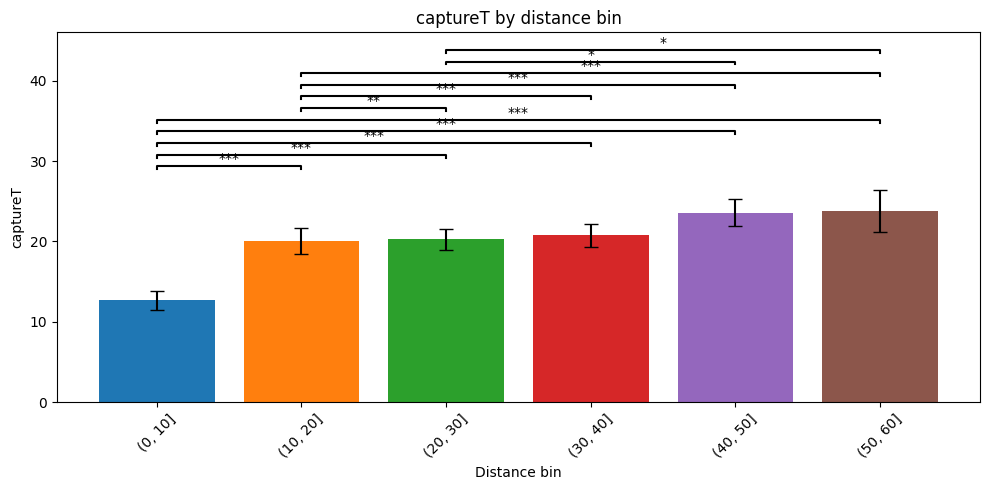

In [146]:
# Ensure plot_df has distance bins and is filtered
plot_df = cleaned_conds_keep.dropna(subset=['dist_100_after_drop', 'captureT']).copy()
plot_df = plot_df[plot_df['dist_100_after_drop'] <= 60]
plot_df['dist_bin'] = pd.cut(plot_df['dist_100_after_drop'], bins=np.arange(0, 62, 10))

# Run stats (if not done already)
stats_results = distance_bin_statistics(plot_df)

# Plot with stars
plot_capture_vs_distance_with_stats(
    plot_df,
    dist_col='dist_bin',
    metric_col='captureT',
    dunn_matrix=stats_results['posthoc']
)


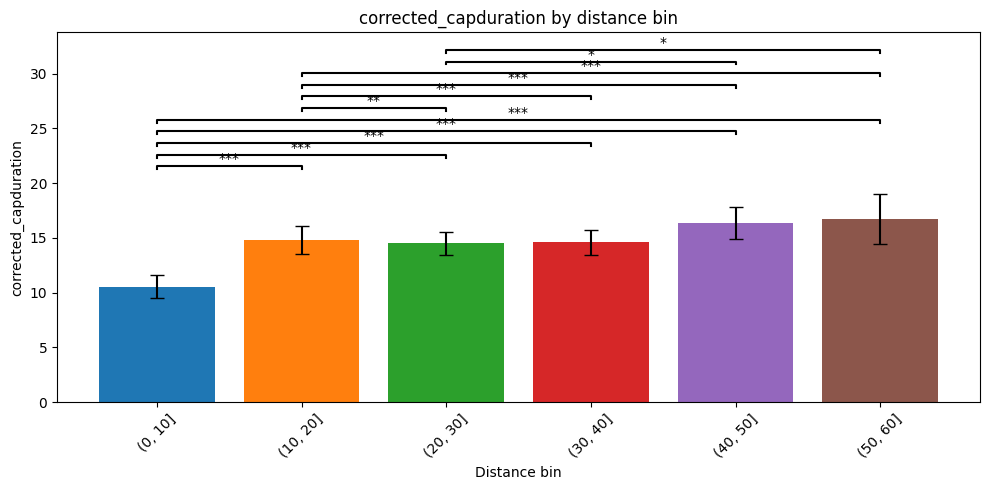

In [147]:
# Ensure plot_df has distance bins and is filtered
plot_df = cleaned_conds_keep.dropna(subset=['dist_100_after_drop', 'corrected_capduration']).copy()
plot_df = plot_df[plot_df['dist_100_after_drop'] <= 60]
plot_df['dist_bin'] = pd.cut(plot_df['dist_100_after_drop'], bins=np.arange(0, 62, 10))

# Run stats (if not done already)
stats_results = distance_bin_statistics(plot_df)

# Plot with stars
plot_capture_vs_distance_with_stats(
    plot_df,
    dist_col='dist_bin',
    metric_col='corrected_capduration',
    dunn_matrix=stats_results['posthoc']
)


### plot effect of laser on capture time and duration in the different distance bins

In [148]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import scikit_posthocs as sp
from scipy.stats import kruskal

def plot_capture_metrics_by_distance(
    df,
    metric_col='captureT',          # 'captureT' or 'corrected_capduration'
    dist_col='dist_100_after_drop',
    max_dist=50,
    dist_bin_size=10,
    condition_col='condition',
    laser_col='laser_value',
    plot_type='point',               # 'point' or 'bar'
    show_stats=True
):
    """
    Plot capture metrics across distance bins, separated by condition and laser.
    
    Parameters
    ----------
    df : pandas.DataFrame
        Data containing metrics and experimental conditions
    metric_col : str
        Metric to plot ('captureT' or 'corrected_capduration')
    dist_col : str
        Column with distance values
    max_dist : float
        Maximum distance to include
    dist_bin_size : float
        Size of each distance bin
    condition_col : str
        Column name for experimental condition
    laser_col : str
        Column name for laser value
    plot_type : str
        'point' for point plot, 'bar' for grouped bar plot
    show_stats : bool
        If True, run Kruskal-Wallis per distance bin and print results
    """
    # ----------------------------
    # Filter data
    # ----------------------------
    df_plot = df.dropna(subset=[metric_col, dist_col, condition_col, laser_col]).copy()
    df_plot = df_plot[df_plot[dist_col] <= max_dist]

    # Create distance bins
    bins = np.arange(0, max_dist + dist_bin_size, dist_bin_size)
    df_plot['dist_bin'] = pd.cut(df_plot[dist_col], bins=bins)

    # Optionally create combined factor for condition + laser
    df_plot['cond_laser'] = df_plot[condition_col].astype(str) + '_laser' + df_plot[laser_col].astype(str)

    # ----------------------------
    # Run stats per distance bin
    # ----------------------------
    if show_stats:
        print(f"Kruskal-Wallis tests for {metric_col} by condition+laser per distance bin:")
        for dist_bin, group in df_plot.groupby('dist_bin'):
            if len(group['cond_laser'].unique()) > 1:
                kw = kruskal(*[g[metric_col].values for _, g in group.groupby('cond_laser')])
                print(f"{dist_bin}: H={kw.statistic:.3f}, p={kw.pvalue:.3e}")

    # ----------------------------
    # Plot
    # ----------------------------
    plt.figure(figsize=(12,6))
    if plot_type == 'point':
        sns.pointplot(
            data=df_plot,
            x='dist_bin',
            y=metric_col,
            hue='cond_laser',
            dodge=0.3,
            errorbar='se',
            markers=['o','s','^','D','v','x'],
            palette='Set2'
        )
    elif plot_type == 'bar':
        # Use seaborn's built-in errorbar handling
        sns.barplot(
            data=df_plot,
            x='dist_bin',
            y=metric_col,
            hue='cond_laser',
            errorbar='se',          # ci='sd' shows standard deviation, or ci=68 for SEM
            palette='Set2',
            capsize=0.1
        )

    else:
        raise ValueError("plot_type must be 'point' or 'bar'")

    plt.xlabel('Distance bin (cm)')
    plt.ylabel(metric_col.replace('_',' ').title())
    plt.title(f'{metric_col.replace("_"," ").title()} by distance, condition, and laser')
    plt.xticks(rotation=45)
    plt.legend(title='Condition+Laser', bbox_to_anchor=(1.05,1), loc='upper left')
    plt.tight_layout()
    plt.show()


Kruskal-Wallis tests for captureT by condition+laser per distance bin:
(0, 10]: H=8.291, p=4.037e-02
(10, 20]: H=3.798, p=2.842e-01
(20, 30]: H=6.386, p=9.429e-02
(30, 40]: H=0.388, p=9.427e-01
(40, 50]: H=4.695, p=1.956e-01


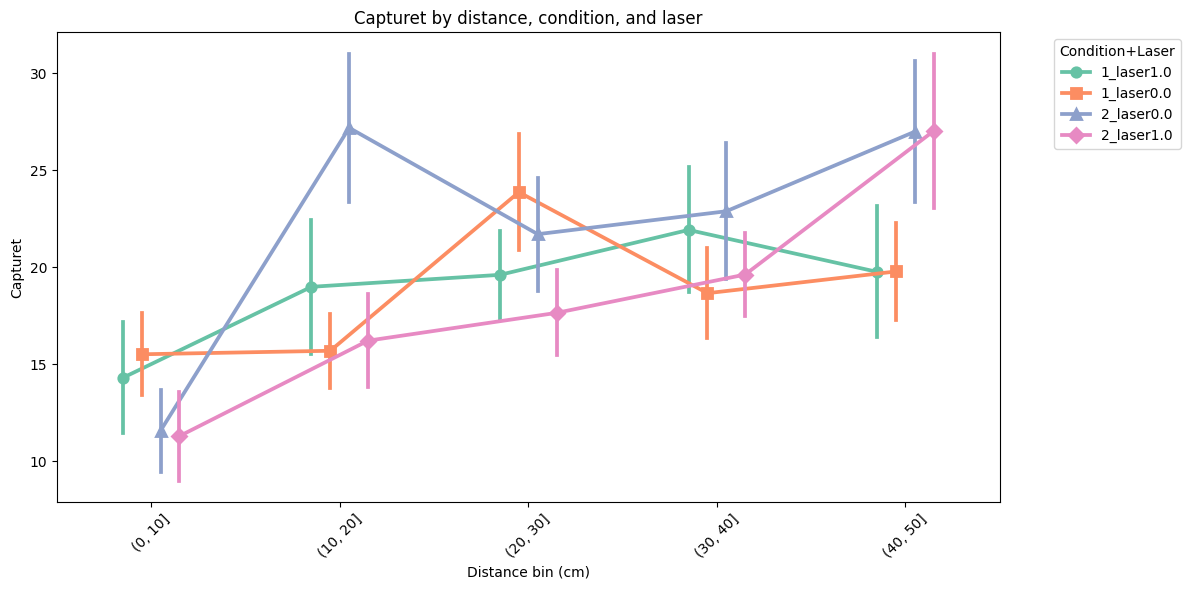

Kruskal-Wallis tests for corrected_capduration by condition+laser per distance bin:
(0, 10]: H=7.112, p=6.841e-02
(10, 20]: H=1.324, p=7.235e-01
(20, 30]: H=7.486, p=5.792e-02
(30, 40]: H=1.344, p=7.187e-01
(40, 50]: H=2.175, p=5.369e-01


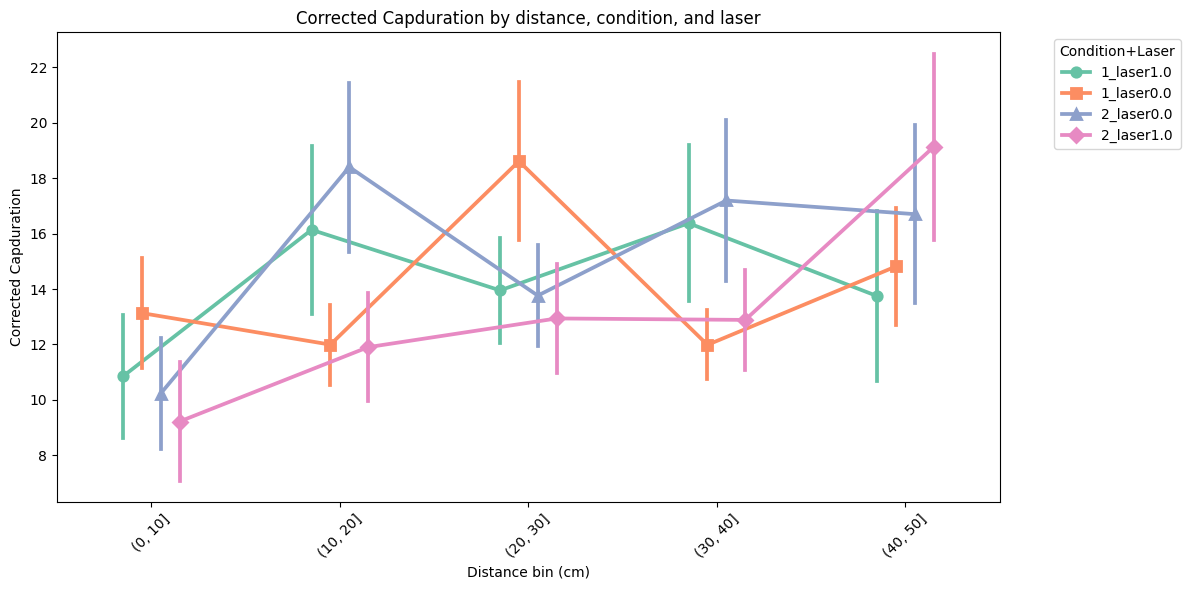

In [152]:
# Example 1: plot captureT
plot_capture_metrics_by_distance(
    cleaned_conds_keep,
    metric_col='captureT',
    dist_col='dist_50_after_drop',
    dist_bin_size=10,
    plot_type='point'
)

# Example 2: plot corrected_capduration
plot_capture_metrics_by_distance(
    cleaned_conds_keep,
    metric_col='corrected_capduration',
    dist_col='dist_50_after_drop',
    dist_bin_size=10,
    plot_type='point'
)


Kruskal-Wallis tests for captureT by condition+laser per distance bin:
(0, 10]: H=8.291, p=4.037e-02
(10, 20]: H=3.798, p=2.842e-01
(20, 30]: H=6.386, p=9.429e-02
(30, 40]: H=0.388, p=9.427e-01
(40, 50]: H=4.695, p=1.956e-01


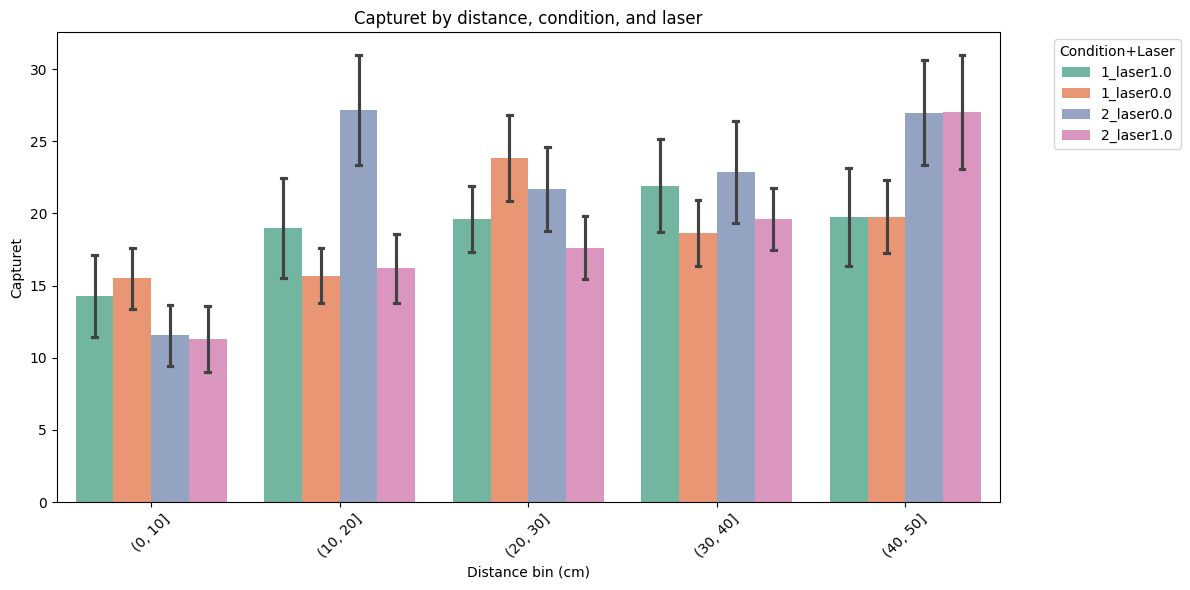

Kruskal-Wallis tests for corrected_capduration by condition+laser per distance bin:
(0, 10]: H=7.112, p=6.841e-02
(10, 20]: H=1.324, p=7.235e-01
(20, 30]: H=7.486, p=5.792e-02
(30, 40]: H=1.344, p=7.187e-01
(40, 50]: H=2.175, p=5.369e-01


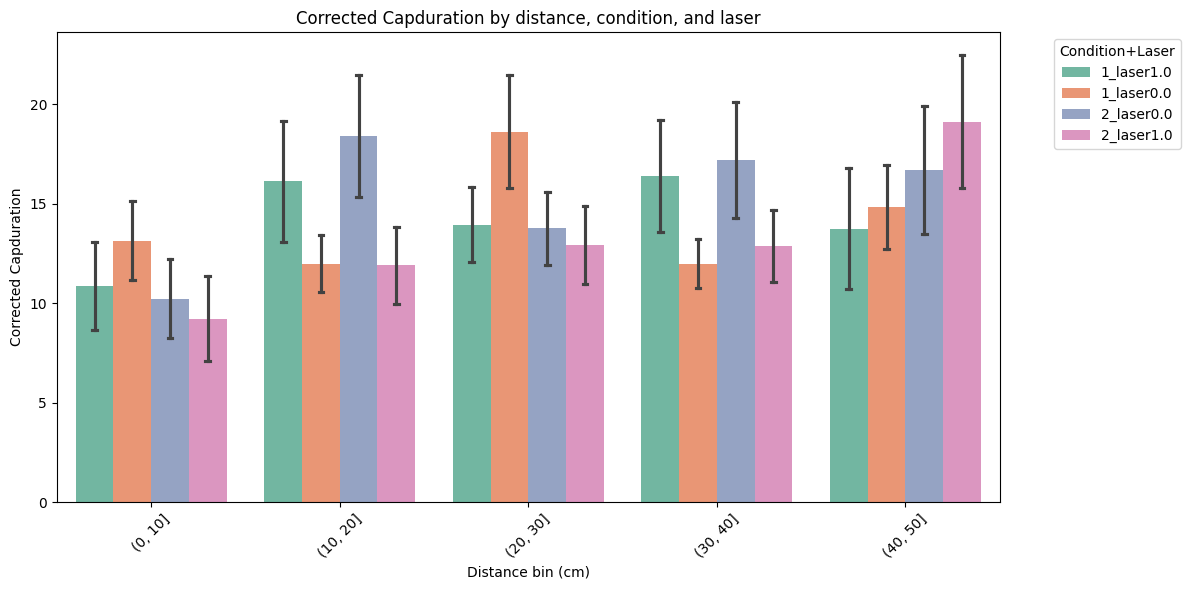

In [157]:
# Example 1: plot captureT
plot_capture_metrics_by_distance(
    cleaned_conds_keep,
    metric_col='captureT',
    dist_col='dist_50_after_drop',
    dist_bin_size=10,
    plot_type='bar'
)

# Example 2: plot corrected_capduration
plot_capture_metrics_by_distance(
    cleaned_conds_keep,
    metric_col='corrected_capduration',
    dist_col='dist_50_after_drop',
    dist_bin_size=10,
    plot_type='bar'
)

Kruskal-Wallis tests for captureT by condition+laser per distance bin:
(0, 10]: H=6.271, p=9.915e-02
(10, 20]: H=2.140, p=5.439e-01
(20, 30]: H=9.196, p=2.679e-02
(30, 40]: H=1.373, p=7.118e-01
(40, 50]: H=6.437, p=9.217e-02


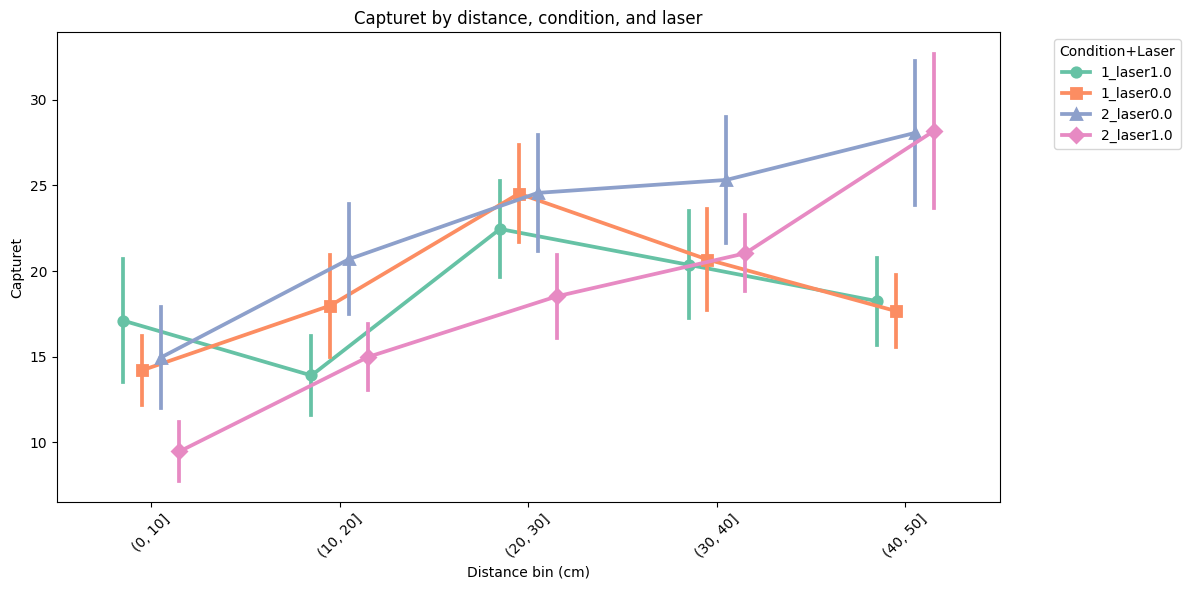

Kruskal-Wallis tests for corrected_capduration by condition+laser per distance bin:
(0, 10]: H=7.347, p=6.161e-02
(10, 20]: H=2.179, p=5.361e-01
(20, 30]: H=9.722, p=2.108e-02
(30, 40]: H=0.997, p=8.019e-01
(40, 50]: H=1.816, p=6.115e-01


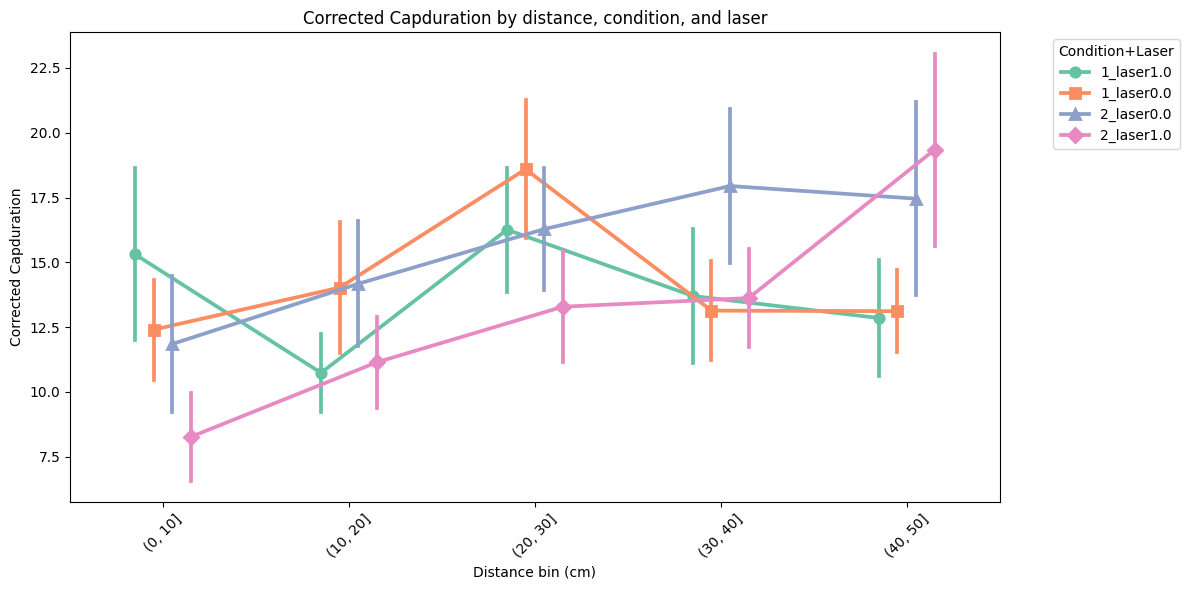

In [158]:
# Example 1: plot captureT
plot_capture_metrics_by_distance(
    cleaned_conds_keep,
    metric_col='captureT',
    dist_col='dist_100_after_drop',
    dist_bin_size=10,
    plot_type='point'
)

# Example 2: plot corrected_capduration
plot_capture_metrics_by_distance(
    cleaned_conds_keep,
    metric_col='corrected_capduration',
    dist_col='dist_100_after_drop',
    dist_bin_size=10,
    plot_type='point'
)

Kruskal-Wallis tests for captureT by condition+laser per distance bin:
(0, 10]: H=6.271, p=9.915e-02
(10, 20]: H=2.140, p=5.439e-01
(20, 30]: H=9.196, p=2.679e-02
(30, 40]: H=1.373, p=7.118e-01
(40, 50]: H=6.437, p=9.217e-02


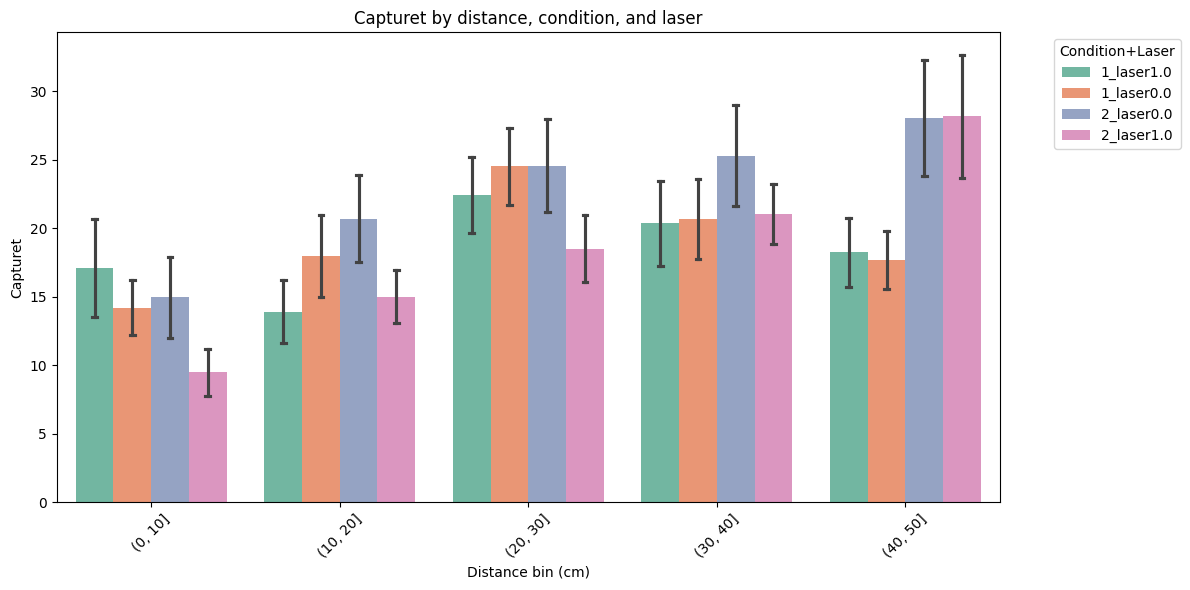

Kruskal-Wallis tests for corrected_capduration by condition+laser per distance bin:
(0, 10]: H=7.347, p=6.161e-02
(10, 20]: H=2.179, p=5.361e-01
(20, 30]: H=9.722, p=2.108e-02
(30, 40]: H=0.997, p=8.019e-01
(40, 50]: H=1.816, p=6.115e-01


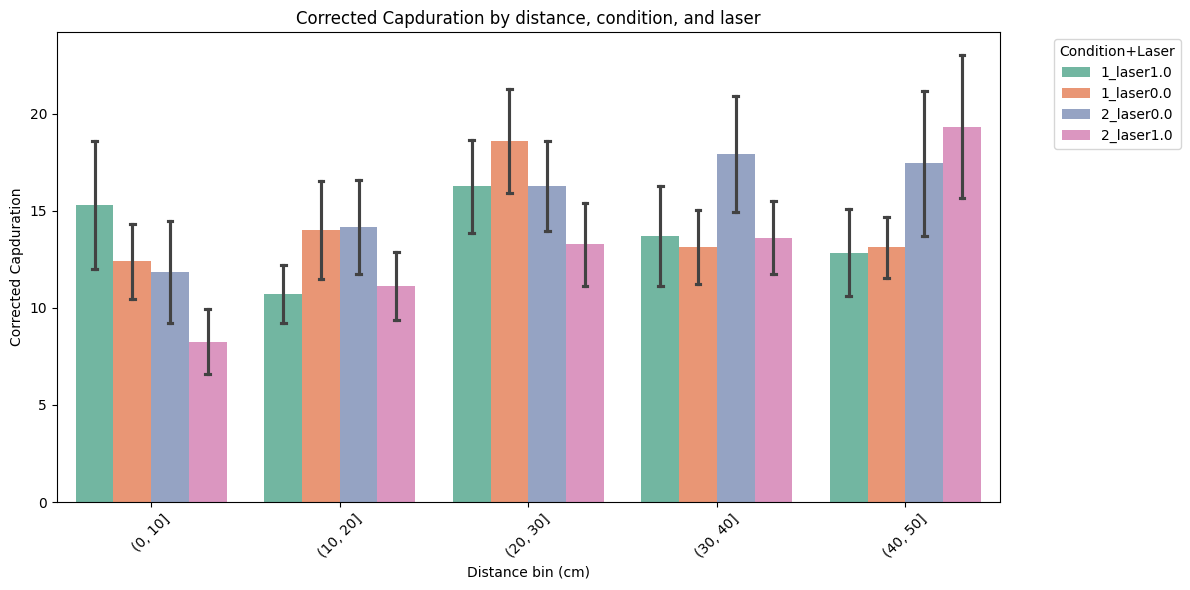

In [159]:
# Example 1: plot captureT
plot_capture_metrics_by_distance(
    cleaned_conds_keep,
    metric_col='captureT',
    dist_col='dist_100_after_drop',
    dist_bin_size=10,
    plot_type='bar'
)

# Example 2: plot corrected_capduration
plot_capture_metrics_by_distance(
    cleaned_conds_keep,
    metric_col='corrected_capduration',
    dist_col='dist_100_after_drop',
    dist_bin_size=10,
    plot_type='bar'
)

In [187]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind, mannwhitneyu

def plot_laser_effect_with_significance(
    df,
    metric_col,
    dist_col='dist_50_after_drop',
    condition_col='condition',
    laser_col='laser_value',
    max_dist=60,
    dist_bin_size=10,
    effect_type='cohens_d',     # 'cohens_d' or 'rank_biserial'
    stat_test='param',           # 'param' (t-test) or 'nonparam' (Mann-Whitney)
    palette='Set2',
    title=None
):
    """
    Plot laser effect sizes per distance bin and condition with significance stars.

    Returns:
        effect_df: DataFrame with dist_bin, condition, effect_size, p_val
    """

    # ----------------------------
    # Filter + bin distances
    # ----------------------------
    df_plot = df[[dist_col, metric_col, condition_col, laser_col]].dropna()
    df_plot = df_plot[df_plot[dist_col] <= max_dist]

    if df_plot.empty:
        print("No data left after filtering.")
        return None

    # Distance bins
    dist_bins = np.arange(0, max_dist + dist_bin_size, dist_bin_size)
    df_plot['dist_bin'] = pd.cut(df_plot[dist_col], bins=dist_bins, right=False)

    # ----------------------------
    # Effect size functions
    # ----------------------------
    def cohens_d(x1, x0):
        n1, n0 = len(x1), len(x0)
        s1, s0 = x1.std(ddof=1), x0.std(ddof=1)
        s_pooled = np.sqrt(((n1-1)*s1**2 + (n0-1)*s0**2) / (n1+n0-2))
        if s_pooled == 0:
            return np.nan
        return (x1.mean() - x0.mean()) / s_pooled

    def rank_biserial(x1, x0):
        if len(x1)==0 or len(x0)==0:
            return np.nan
        U, _ = mannwhitneyu(x1, x0, alternative='two-sided')
        return 2*U/(len(x1)*len(x0)) - 1

    # ----------------------------
    # Calculate effect sizes & p-values
    # ----------------------------
    records = []
    for (dist_bin, cond), group in df_plot.groupby(['dist_bin', condition_col]):
        x1 = group.loc[group[laser_col]==1, metric_col]
        x0 = group.loc[group[laser_col]==0, metric_col]

        if effect_type == 'cohens_d':
            eff = cohens_d(x1, x0)
        elif effect_type == 'rank_biserial':
            eff = rank_biserial(x1, x0)
        else:
            raise ValueError("effect_type must be 'cohens_d' or 'rank_biserial'")

        # Statistical test
        if stat_test == 'param':
            if len(x1)>1 and len(x0)>1:
                stat, p_val = ttest_ind(x1, x0, equal_var=False)
            else:
                p_val = np.nan
        elif stat_test == 'nonparam':
            if len(x1)>0 and len(x0)>0:
                _, p_val = mannwhitneyu(x1, x0, alternative='two-sided')
            else:
                p_val = np.nan
        else:
            raise ValueError("stat_test must be 'param' or 'nonparam'")

        records.append({
            'dist_bin': dist_bin,
            'condition': cond,
            'effect_size': eff,
            'p_val': p_val
        })

    effect_df = pd.DataFrame(records)

    # ----------------------------
    # Plot
    # ----------------------------
    # Sort by distance bin
    effect_df = effect_df.sort_values(['dist_bin', 'condition'])

    plt.figure(figsize=(10,6))
    ax = sns.barplot(
        data=effect_df,
        x='dist_bin',
        y='effect_size',
        hue='condition',
        palette=palette,
        dodge=True
    )
    plt.axhline(0, color='k', linestyle='--')
    plt.ylabel(f'Laser effect ({effect_type})')
    plt.xlabel('Distance bin')
    if title:
        plt.title(title)

    # Significance stars
    def get_star(p):
        if pd.isna(p):
            return ''
        if p < 0.001:
            return '***'
        elif p < 0.01:
            return '**'
        elif p < 0.05:
            return '*'
        else:
            return ''

    for bar, (_, row) in zip(ax.patches, effect_df.iterrows()):
        star = get_star(row['p_val'])
        if star:
            height = bar.get_height()
            ax.text(
                bar.get_x() + bar.get_width()/2,
                height + 0.05*np.sign(height),
                star,
                ha='center',
                va='bottom',
                fontsize=12,
                color='k'
            )

    plt.xticks(rotation=45)
    plt.legend(title='Condition', bbox_to_anchor=(1.05,1), loc='upper left')
    plt.tight_layout()
    plt.show()

    return effect_df


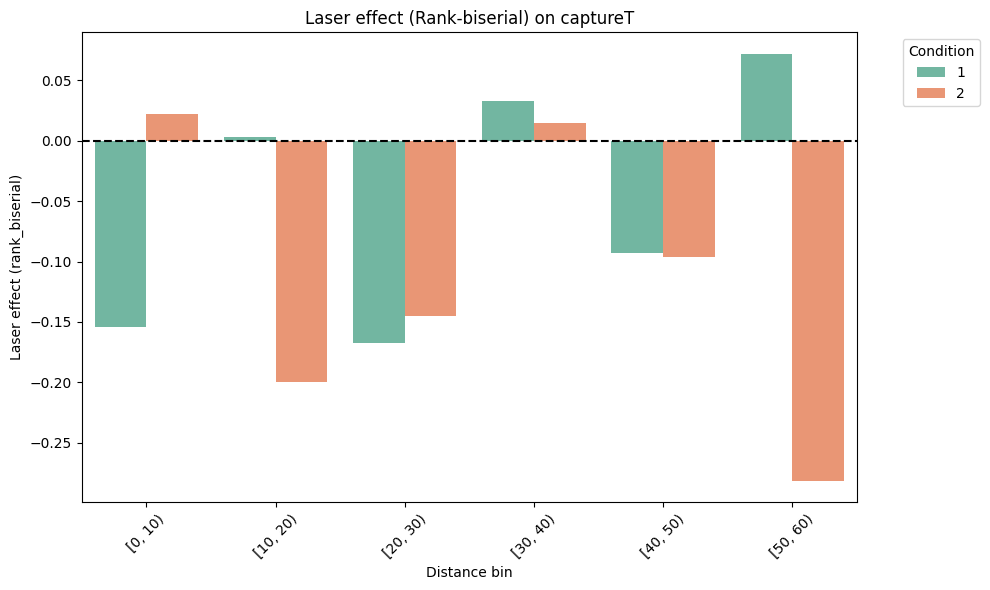

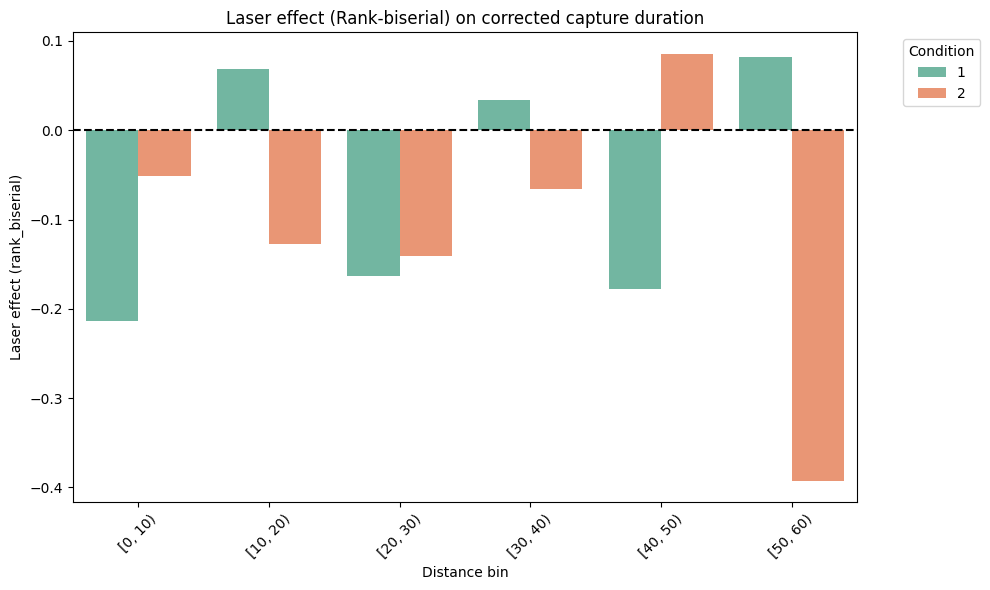

In [188]:
# Example 1: captureT
effect_stats1 = plot_laser_effect_with_significance(
    cleaned_conds_keep,
    metric_col='captureT',
    effect_type='rank_biserial',
    stat_test='nonparam',
    dist_bin_size=10,
    title='Laser effect (Rank-biserial) on captureT'
)

# Example 2: corrected_capduration
effect_stats2 = plot_laser_effect_with_significance(
    cleaned_conds_keep,
    metric_col='corrected_capduration',
    effect_type='rank_biserial',
    stat_test='nonparam',
    dist_bin_size=10,
    title='Laser effect (Rank-biserial) on corrected capture duration'
)


In [190]:
def plot_laser_effect_heatmap(
    df,
    metric_col,
    dist_col='dist_50_after_drop',
    condition_col='condition',
    laser_col='laser_value',
    max_dist=60,
    dist_bin_size=10,
    effect_type='cohens_d',     # 'cohens_d' or 'rank_biserial'
    stat_test='param',           # 'param' (t-test) or 'nonparam' (Mann-Whitney)
    cmap='coolwarm',
    title=None
):
    """
    Plot laser effect sizes as a heatmap per distance bin and condition with significance stars.

    Returns:
        effect_df: DataFrame with dist_bin, condition, effect_size, p_val
    """

    # ----------------------------
    # Filter + bin distances
    # ----------------------------
    df_plot = df[[dist_col, metric_col, condition_col, laser_col]].dropna()
    df_plot = df_plot[df_plot[dist_col] <= max_dist]

    if df_plot.empty:
        print("No data left after filtering.")
        return None

    dist_bins = np.arange(0, max_dist + dist_bin_size, dist_bin_size)
    df_plot['dist_bin'] = pd.cut(df_plot[dist_col], bins=dist_bins, right=False)

    # ----------------------------
    # Effect size functions
    # ----------------------------
    def cohens_d(x1, x0):
        n1, n0 = len(x1), len(x0)
        s1, s0 = x1.std(ddof=1), x0.std(ddof=1)
        s_pooled = np.sqrt(((n1-1)*s1**2 + (n0-1)*s0**2) / (n1+n0-2))
        if s_pooled == 0:
            return np.nan
        return (x1.mean() - x0.mean()) / s_pooled

    def rank_biserial(x1, x0):
        if len(x1)==0 or len(x0)==0:
            return np.nan
        from scipy.stats import mannwhitneyu
        U, _ = mannwhitneyu(x1, x0, alternative='two-sided')
        return 2*U/(len(x1)*len(x0)) - 1

    # ----------------------------
    # Calculate effect sizes & p-values
    # ----------------------------
    records = []
    for (dist_bin, cond), group in df_plot.groupby(['dist_bin', condition_col]):
        x1 = group.loc[group[laser_col]==1, metric_col]
        x0 = group.loc[group[laser_col]==0, metric_col]

        if effect_type == 'cohens_d':
            eff = cohens_d(x1, x0)
        elif effect_type == 'rank_biserial':
            eff = rank_biserial(x1, x0)
        else:
            raise ValueError("effect_type must be 'cohens_d' or 'rank_biserial'")

        # Statistical test
        if stat_test == 'param':
            if len(x1)>1 and len(x0)>1:
                from scipy.stats import ttest_ind
                _, p_val = ttest_ind(x1, x0, equal_var=False)
            else:
                p_val = np.nan
        elif stat_test == 'nonparam':
            if len(x1)>0 and len(x0)>0:
                from scipy.stats import mannwhitneyu
                _, p_val = mannwhitneyu(x1, x0, alternative='two-sided')
            else:
                p_val = np.nan
        else:
            raise ValueError("stat_test must be 'param' or 'nonparam'")

        records.append({
            'dist_bin': dist_bin,
            'condition': cond,
            'effect_size': eff,
            'p_val': p_val
        })

    effect_df = pd.DataFrame(records)

    # ----------------------------
    # Pivot for heatmap
    # ----------------------------
    heat_df = effect_df.pivot(index='condition', columns='dist_bin', values='effect_size')
    p_df = effect_df.pivot(index='condition', columns='dist_bin', values='p_val')

    plt.figure(figsize=(12, max(4, len(heat_df)*0.8)))
    sns.heatmap(
        heat_df,
        cmap=cmap,
        annot=False,
        center=0,
        cbar_kws={'label': f'Laser effect ({effect_type})'}
    )
    plt.xlabel('Distance bin')
    plt.ylabel('Condition')
    if title:
        plt.title(title)

    # ----------------------------
    # Overlay significance stars
    # ----------------------------
    def get_star(p):
        if pd.isna(p):
            return ''
        if p < 0.001:
            return '***'
        elif p < 0.01:
            return '**'
        elif p < 0.05:
            return '*'
        else:
            return ''

    # Loop over all heatmap cells
    for y_idx, cond in enumerate(heat_df.index):
        for x_idx, dist_bin in enumerate(heat_df.columns):
            p_val = p_df.loc[cond, dist_bin]
            star = get_star(p_val)
            if star:
                plt.text(
                    x_idx + 0.5,
                    y_idx + 0.5,
                    star,
                    ha='center',
                    va='center',
                    color='k',
                    fontsize=12
                )

    plt.tight_layout()
    plt.show()

    return effect_df


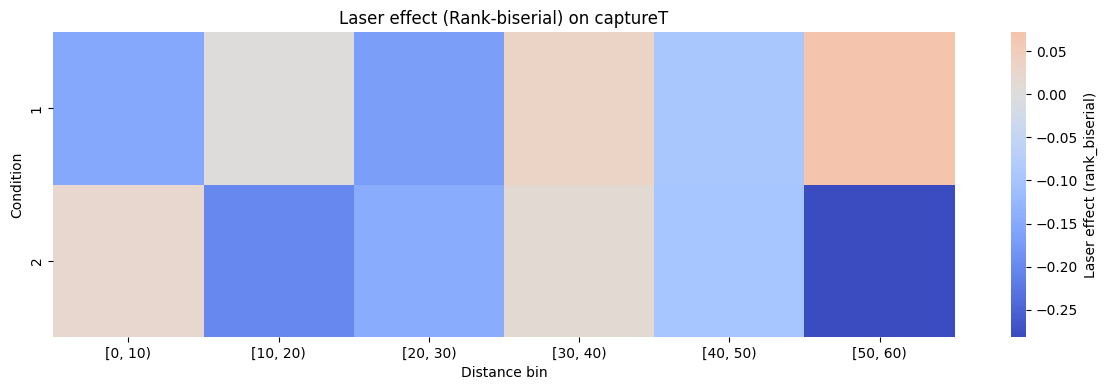

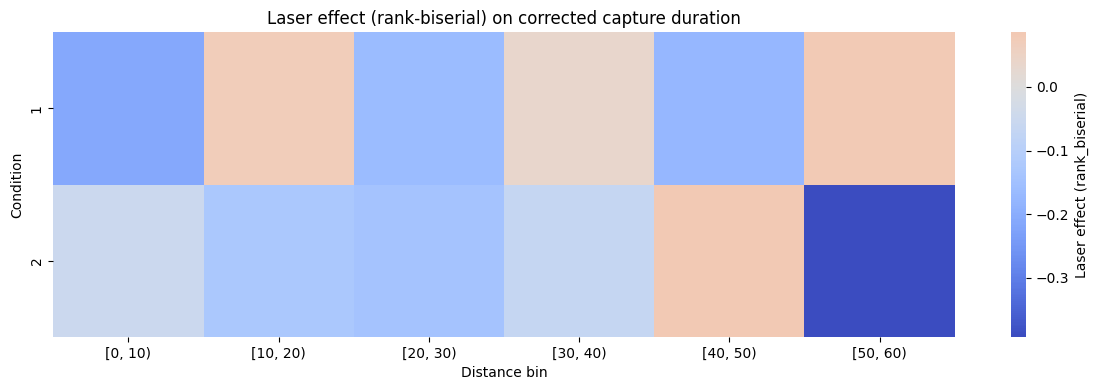

In [191]:
# Capture time heatmap
heat_stats1 = plot_laser_effect_heatmap(
    cleaned_conds_keep,
    metric_col='captureT',
    effect_type='rank_biserial',
    stat_test='nonparam',
    dist_bin_size=10,
    title='Laser effect (Rank-biserial) on captureT'
)

# Corrected capture duration heatmap
heat_stats2 = plot_laser_effect_heatmap(
    cleaned_conds_keep,
    metric_col='corrected_capduration',
    effect_type='rank_biserial',
    stat_test='nonparam',
    dist_bin_size=10,
    title='Laser effect (rank-biserial) on corrected capture duration'
)


In [193]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu, ttest_ind, kruskal
import scikit_posthocs as sp

def plot_laser_effect_by_bin(
    df,
    metric_col,
    dist_col='dist_50_after_drop',
    condition_col='condition',
    laser_col='laser_value',
    max_dist=60,
    dist_bin_size=10,
    effect_type='rank_biserial',   # 'cohens_d' or 'rank_biserial'
    stat_test='nonparam',          # 'param' or 'nonparam'
    palette='Set2',
    plot_type='bar',               # 'bar' or 'heatmap'
    show_posthoc=True,
    title=None
):
    """
    Calculate and plot laser effect sizes per distance bin & condition.
    
    Returns:
        effect_df: DataFrame with effect_size, p-values, n per bin & condition
        posthoc_dict: dict of post-hoc Dunn test DataFrames per condition (optional)
    """
    # ----------------------------
    # Filter
    # ----------------------------
    plot_df = df[[dist_col, metric_col, condition_col, laser_col]].dropna()
    plot_df = plot_df[plot_df[dist_col] <= max_dist]
    
    if plot_df.empty:
        print("No data after filtering.")
        return None, None
    
    # ----------------------------
    # Define bins
    # ----------------------------
    dist_bins = np.arange(0, max_dist + dist_bin_size, dist_bin_size)
    plot_df['dist_bin'] = pd.cut(plot_df[dist_col], bins=dist_bins, right=False)
    
    # ----------------------------
    # Compute effect size & stats
    # ----------------------------
    effect_list = []
    
    for cond, group in plot_df.groupby(condition_col):
        for dbin, sub in group.groupby('dist_bin'):
            laser_on = sub[sub[laser_col]==1][metric_col].values
            laser_off = sub[sub[laser_col]==0][metric_col].values
            n_on = len(laser_on)
            n_off = len(laser_off)
            
            if len(laser_on) < 2 or len(laser_off) < 2:
                effect_size = np.nan
                p_val = np.nan
            else:
                if effect_type == 'cohens_d':
                    pooled_sd = np.sqrt(
                        ((n_on - 1)*laser_on.std(ddof=1)**2 + (n_off - 1)*laser_off.std(ddof=1)**2) /
                        (n_on + n_off - 2)
                    )
                    effect_size = (laser_on.mean() - laser_off.mean()) / pooled_sd
                elif effect_type == 'rank_biserial':
                    u_stat, p_val = mannwhitneyu(laser_on, laser_off, alternative='two-sided')
                    effect_size = 1 - 2 * u_stat / (n_on * n_off)
                else:
                    raise ValueError("effect_type must be 'cohens_d' or 'rank_biserial'")
                
                if stat_test == 'param' and effect_type=='cohens_d':
                    t_stat, p_val = ttest_ind(laser_on, laser_off, equal_var=False)
                elif stat_test == 'nonparam':
                    u_stat, p_val = mannwhitneyu(laser_on, laser_off, alternative='two-sided')
            
            effect_list.append({
                'condition': cond,
                'dist_bin': dbin,
                'effect_size': effect_size,
                'p_val': p_val,
                'n_on': n_on,
                'n_off': n_off
            })
    
    effect_df = pd.DataFrame(effect_list)
    
    # Sort by absolute effect size
    effect_df['abs_effect'] = effect_df['effect_size'].abs()
    effect_df = effect_df.sort_values('abs_effect', ascending=False)
    
    # ----------------------------
    # Post-hoc Dunn test across bins (optional)
    # ----------------------------
    posthoc_dict = {}
    if show_posthoc:
        for cond, group in plot_df.groupby(condition_col):
            bins_list = [group[group['dist_bin']==b][metric_col].values
                         for b in group['dist_bin'].unique()]
            if all(len(x) > 2 for x in bins_list):
                dunn = sp.posthoc_dunn(bins_list, p_adjust='bonferroni')
                dunn.index = dunn.columns = group['dist_bin'].unique()
                posthoc_dict[cond] = dunn
    
    # ----------------------------
    # Plot
    # ----------------------------
    effect_df_plot = effect_df.copy()
    effect_df_plot['dist_bin'] = effect_df_plot['dist_bin'].astype(str)
    
    def get_star(p):
        if pd.isna(p):
            return ''
        elif p < 0.001:
            return '***'
        elif p < 0.01:
            return '**'
        elif p < 0.05:
            return '*'
        else:
            return ''
    
    if plot_type=='bar':
        effect_df_plot = effect_df_plot.sort_values(['dist_bin', 'condition'])
        plt.figure(figsize=(10,6))
        ax = sns.barplot(
            data=effect_df_plot,
            x='dist_bin',
            y='effect_size',
            hue='condition',
            palette=palette,
            dodge=True
        )
        plt.axhline(0, color='k', linestyle='--')
        plt.ylabel(f'Laser effect ({effect_type})')
        plt.xlabel('Distance bin')
        if title:
            plt.title(title)
        
        # Add stars
        for bar, (_, row) in zip(ax.patches, effect_df_plot.iterrows()):
            star = get_star(row['p_val'])
            if star:
                height = bar.get_height()
                ax.text(
                    bar.get_x() + bar.get_width()/2,
                    height + 0.05*np.sign(height),
                    star,
                    ha='center',
                    va='bottom',
                    fontsize=12,
                    color='k'
                )
        plt.xticks(rotation=45)
        plt.legend(title='Condition', bbox_to_anchor=(1.05,1), loc='upper left')
        plt.tight_layout()
        plt.show()
    
    elif plot_type=='heatmap':
        pivot = effect_df_plot.pivot(index='condition', columns='dist_bin', values='effect_size')
        plt.figure(figsize=(10,5))
        sns.heatmap(pivot, annot=True, fmt='.2f', cmap='coolwarm', center=0, cbar_kws={'label': effect_type})
        plt.ylabel('Condition')
        plt.xlabel('Distance bin')
        if title:
            plt.title(title)
        plt.tight_layout()
        plt.show()
    
    return effect_df, posthoc_dict




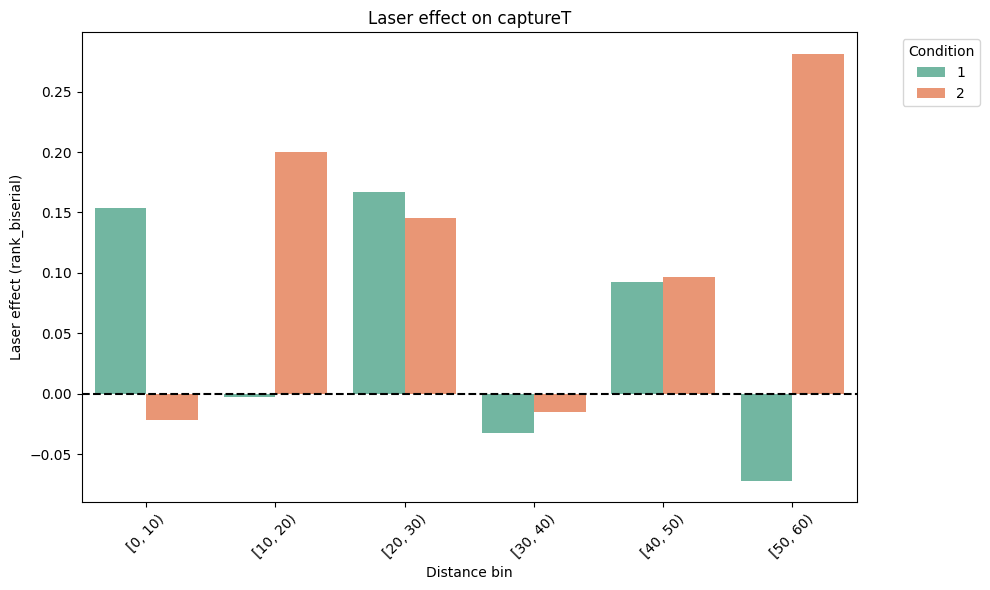

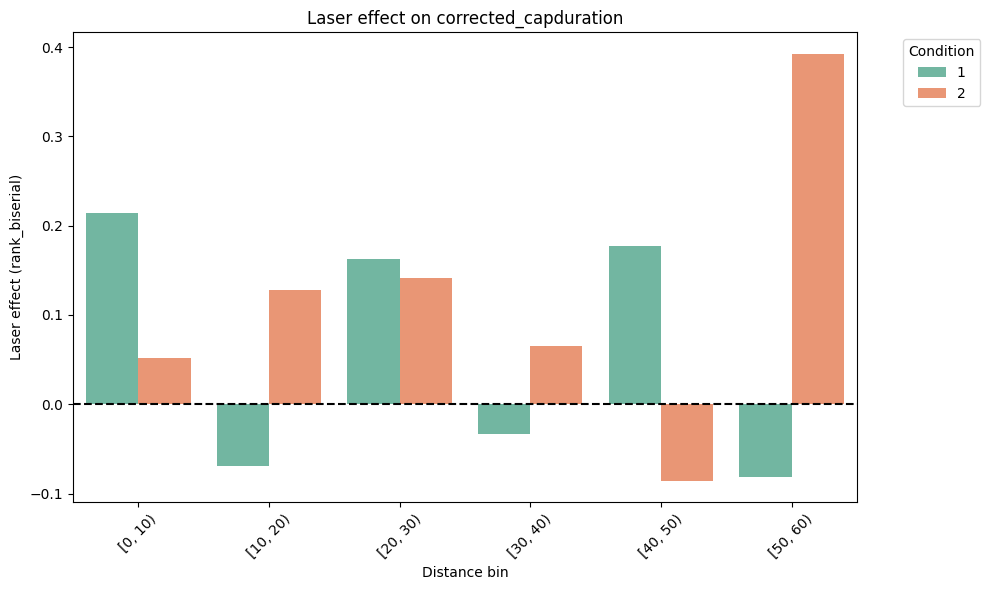

,condition,dist_bin,effect_size,p_val,n_on,n_off
11,2,"[50, 60)",0.281481,0.269868,15,9
7,2,"[10, 20)",0.200104,0.109967,37,52
2,1,"[20, 30)",0.167251,0.139219,62,46
0,1,"[0, 10)",0.153846,0.483577,13,18
8,2,"[20, 30)",0.145352,0.175284,71,50
10,2,"[40, 50)",0.096599,0.470768,42,35
4,1,"[40, 50)",0.092768,0.495820,37,37
5,1,"[50, 60)",-0.072115,0.707234,26,16
3,1,"[30, 40)",-0.032558,0.795811,43,45
6,2,"[0, 10)",-0.022059,0.893248,24,34


In [194]:
# Capture time effect
effect_df, posthoc = plot_laser_effect_by_bin(
    cleaned_conds_keep,
    metric_col='captureT',
    effect_type='rank_biserial',
    stat_test='nonparam',
    dist_bin_size=10,
    plot_type='bar',
    title='Laser effect on captureT'
)

# Corrected capture duration effect
effect_df2, posthoc2 = plot_laser_effect_by_bin(
    cleaned_conds_keep,
    metric_col='corrected_capduration',
    effect_type='rank_biserial',
    stat_test='nonparam',
    dist_bin_size=10,
    plot_type='bar',
    title='Laser effect on corrected_capduration'
)

# View the top bins by effect size
effect_df[['condition','dist_bin','effect_size','p_val','n_on','n_off']].head(10)


In [209]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
import seaborn as sns


def plot_metric_vs_distance_condition_laser_bootstrap(
    df,
    dist_col='dist_100_after_drop',
    metric_col='captureT',
    condition_col='condition',
    laser_col='laser_value',
    metric_bin_size=10,
    max_dist=60,
    bandwidth=2,
    n_boot=500,
    ci=95,
    min_n=10,
    cmap='Spectral',
    title=None
):
    """
    Continuous-distance stacked percentage plots faceted by condition × laser,
    with bootstrap confidence bands.
    """

    # ----------------------------
    # Filter + prep
    # ----------------------------
    plot_df = df[[dist_col, metric_col, condition_col, laser_col]].dropna()
    plot_df = plot_df[plot_df[dist_col] <= max_dist]

    conditions = sorted(plot_df[condition_col].unique())
    lasers = sorted(plot_df[laser_col].unique())

    # Metric bins
    max_metric = np.ceil(plot_df[metric_col].max() / metric_bin_size) * metric_bin_size
    metric_bins = np.arange(0, max_metric + metric_bin_size, metric_bin_size)

    metric_labels = [
        f'{int(metric_bins[i])}–{int(metric_bins[i+1])}'
        for i in range(len(metric_bins) - 1)
    ]

    plot_df['metric_bin'] = pd.cut(
        plot_df[metric_col],
        bins=metric_bins,
        labels=metric_labels,
        right=False
    )

    # Distance grid
    x_grid = np.linspace(0, max_dist, 300)

    # Figure
    fig, axes = plt.subplots(
        len(conditions),
        len(lasers),
        figsize=(4 * len(lasers), 3 * len(conditions)),
        sharex=True,
        sharey=True
    )

    if len(conditions) == 1:
        axes = np.array([axes])
    if len(lasers) == 1:
        axes = axes[:, np.newaxis]

    colors = plt.cm.get_cmap(cmap, len(metric_labels))
    alpha_low = (100 - ci) / 2
    alpha_high = 100 - alpha_low

    # ----------------------------
    # Main loop
    # ----------------------------
    for i, cond in enumerate(conditions):
        for j, laser in enumerate(lasers):

            ax = axes[i, j]
            sub_df = plot_df[
                (plot_df[condition_col] == cond) &
                (plot_df[laser_col] == laser)
            ]

            if sub_df.empty:
                ax.set_axis_off()
                continue

            # ---- Point estimate ----
            densities = []

            for label in metric_labels:
                d = sub_df[sub_df['metric_bin'] == label][dist_col]
                if len(d) < min_n:
                    densities.append(np.zeros_like(x_grid))
                    continue

                kde = gaussian_kde(
                    d,
                    bw_method=bandwidth / d.std()
                )
                densities.append(kde(x_grid))

            densities = np.array(densities)
            norm = densities.sum(axis=0)
            norm[norm == 0] = np.nan
            densities = densities / norm * 100

            # ---- Bootstrap ----
            boot_cumsums = []

            for _ in range(n_boot):
                boot = sub_df.sample(frac=1, replace=True)
                boot_dens = []

                for label in metric_labels:
                    d = boot[boot['metric_bin'] == label][dist_col]
                    if len(d) < min_n:
                        boot_dens.append(np.zeros_like(x_grid))
                        continue

                    kde = gaussian_kde(
                        d,
                        bw_method=bandwidth / d.std()
                    )
                    boot_dens.append(kde(x_grid))

                boot_dens = np.array(boot_dens)
                norm = boot_dens.sum(axis=0)
                norm[norm == 0] = np.nan
                boot_dens = boot_dens / norm * 100

                boot_cumsums.append(np.cumsum(boot_dens, axis=0))

            boot_cumsums = np.array(boot_cumsums)

            lower = np.nanpercentile(boot_cumsums, alpha_low, axis=0)
            upper = np.nanpercentile(boot_cumsums, alpha_high, axis=0)
            mean_cum = np.cumsum(densities, axis=0)

            # ---- Plot ----
            ax.stackplot(
                x_grid,
                densities,
                colors=[colors(k) for k in range(len(metric_labels))]
            )

            # Confidence bands
            for k in range(len(metric_labels)):
                ax.fill_between(
                    x_grid,
                    lower[k],
                    upper[k],
                    color=colors(k),
                    alpha=0.2,
                    linewidth=0
                )

            ax.set_title(f'Cond: {cond} | Laser: {laser}')
            ax.set_ylabel('Percentage (%)')

    # ----------------------------
    # Final formatting
    # ----------------------------
    for ax in axes[-1]:
        ax.set_xlabel('Distance (continuous)')

    handles = [
        plt.Line2D([0], [0], color=colors(i), lw=6)
        for i in range(len(metric_labels))
    ]

    fig.legend(
        handles,
        metric_labels,
        title=f'{metric_col} bins',
        bbox_to_anchor=(1.02, 0.5),
        loc='center left'
    )

    if title:
        fig.suptitle(title, y=1.02, fontsize=14)
    sns.despine()
    plt.tight_layout()
    plt.show()


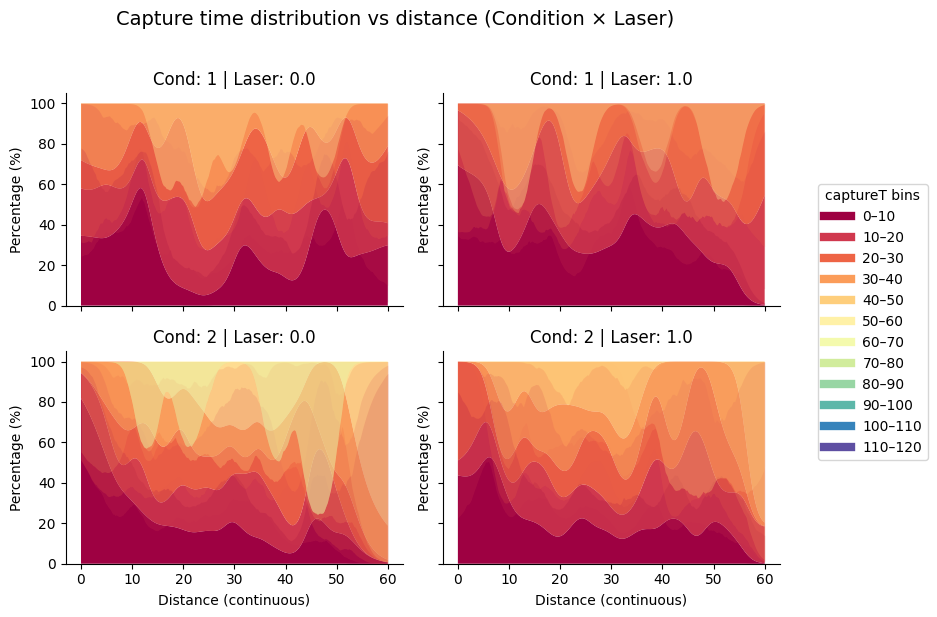

In [210]:
plot_metric_vs_distance_condition_laser_bootstrap(
    cleaned_conds_keep,
    metric_col='captureT',
    metric_bin_size=10,
    max_dist=60,
    title='Capture time distribution vs distance (Condition × Laser)'
)


In [232]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.stats import gaussian_kde, mannwhitneyu


# ----------------------------
# Effect size helpers
# ----------------------------
def rank_biserial(x, y):
    u, _ = mannwhitneyu(x, y, alternative='two-sided')
    return 1 - (2 * u) / (len(x) * len(y))


def bootstrap_rank_biserial(x, y, n_boot=300, ci=95):
    if len(x) < 3 or len(y) < 3:
        return np.nan, np.nan, np.nan

    boots = []
    for _ in range(n_boot):
        xb = np.random.choice(x, len(x), replace=True)
        yb = np.random.choice(y, len(y), replace=True)
        boots.append(rank_biserial(xb, yb))

    lo = np.percentile(boots, (100 - ci) / 2)
    hi = np.percentile(boots, 100 - (100 - ci) / 2)
    return np.mean(boots), lo, hi


# ----------------------------
# Main plotting function
# ----------------------------
def plot_metric_vs_distance_condition_laser_with_effects(
    df,
    dist_col='dist_50_after_drop',
    metric_col='captureT',
    condition_col='condition',
    laser_col='laser_value',
    metric_bin_size=10,
    max_dist=60,
    bandwidth=2,
    window=5,
    min_n=10,
    n_boot=300,
    ci=95,
    cmap='Spectral',
    title=None
):
    """
    Continuous-distance stacked distributions (condition × laser),
    with bootstrap CI bands and laser effect-size curves (rank-biserial).
    """

    # ----------------------------
    # Prep data
    # ----------------------------
    plot_df = df[[dist_col, metric_col, condition_col, laser_col]].dropna()
    plot_df = plot_df[plot_df[dist_col] <= max_dist]

    conditions = sorted(plot_df[condition_col].unique())
    lasers = sorted(plot_df[laser_col].unique())

    # Metric bins
    max_metric = np.ceil(plot_df[metric_col].max() / metric_bin_size) * metric_bin_size
    metric_bins = np.arange(0, max_metric + metric_bin_size, metric_bin_size)
    metric_labels = [
        f'{int(metric_bins[i])}–{int(metric_bins[i+1])}'
        for i in range(len(metric_bins) - 1)
    ]

    plot_df['metric_bin'] = pd.cut(
        plot_df[metric_col],
        bins=metric_bins,
        labels=metric_labels,
        right=False
    )

    x_grid = np.linspace(0, max_dist, 250)
    colors = plt.cm.get_cmap(cmap, len(metric_labels))

    # ----------------------------
    # Figure layout (GridSpec)
    # ----------------------------
    n_cond = len(conditions)
    n_laser = len(lasers)

    fig = plt.figure(figsize=(4 * n_laser, 4 * n_cond))
    gs = gridspec.GridSpec(
        nrows=2 * n_cond,
        ncols=n_laser,
        height_ratios=[3, 1] * n_cond,
        hspace=0.35,
        wspace=0.2
    )

    # ----------------------------
    # Loop over conditions
    # ----------------------------
    for ci_idx, cond in enumerate(conditions):
        top_row = ci_idx * 2
        eff_row = top_row + 1

        cond_df = plot_df[plot_df[condition_col] == cond]

        # ---------- Stacked KDEs ----------
        for lj, laser in enumerate(lasers):
            ax = fig.add_subplot(gs[top_row, lj])
            sub = cond_df[cond_df[laser_col] == laser]

            if sub.empty:
                ax.set_axis_off()
                continue

            densities = []

            for label in metric_labels:
                d = sub[sub['metric_bin'] == label][dist_col]
                if len(d) < min_n or d.std() == 0:
                    densities.append(np.zeros_like(x_grid))
                    continue

                kde = gaussian_kde(d, bw_method=bandwidth / d.std())
                densities.append(kde(x_grid))

            densities = np.array(densities)
            norm = densities.sum(axis=0)
            norm[norm == 0] = np.nan
            densities = densities / norm * 100

            ax.stackplot(
                x_grid,
                densities,
                colors=[colors(i) for i in range(len(metric_labels))]
            )

            ax.set_title(f'Condition {cond} | Laser {laser}')
            ax.set_ylabel('% trials')

        # ---------- Effect size curve ----------
        eff_ax = fig.add_subplot(gs[eff_row, :])

        effects, lo_ci, hi_ci = [], [], []

        for x in x_grid:
            off = cond_df[
                (cond_df[laser_col] == lasers[0]) &
                (np.abs(cond_df[dist_col] - x) <= window)
            ][metric_col].values

            on = cond_df[
                (cond_df[laser_col] == lasers[1]) &
                (np.abs(cond_df[dist_col] - x) <= window)
            ][metric_col].values

            if len(off) < min_n or len(on) < min_n:
                effects.append(np.nan)
                lo_ci.append(np.nan)
                hi_ci.append(np.nan)
                continue

            mean_r, lo, hi = bootstrap_rank_biserial(
                off, on,
                n_boot=n_boot,
                ci=ci
            )

            effects.append(mean_r)
            lo_ci.append(lo)
            hi_ci.append(hi)

        effects = np.array(effects)
        lo_ci = np.array(lo_ci)
        hi_ci = np.array(hi_ci)

        eff_ax.plot(x_grid, effects, color='black', lw=2)
        eff_ax.fill_between(
            x_grid, lo_ci, hi_ci,
            color='black', alpha=0.25
        )

        eff_ax.axhline(0, color='gray', ls='--')
        eff_ax.set_ylabel('Rank-biserial r')
        eff_ax.set_ylim(-1, 1)
        eff_ax.set_title(f'Laser effect size — Condition {cond}')

    # ----------------------------
    # Final formatting
    # ----------------------------
    for ax in fig.axes[-n_laser:]:
        ax.set_xlabel('Distance (continuous)')

    handles = [
        plt.Line2D([0], [0], color=colors(i), lw=6)
        for i in range(len(metric_labels))
    ]

    fig.legend(
        handles,
        metric_labels,
        title=f'{metric_col} bins',
        bbox_to_anchor=(1.02, 0.5),
        loc='center left'
    )

    if title:
        fig.suptitle(title, y=1.02, fontsize=14)
    sns.despine()
    # plt.tight_layout()
    plt.show()


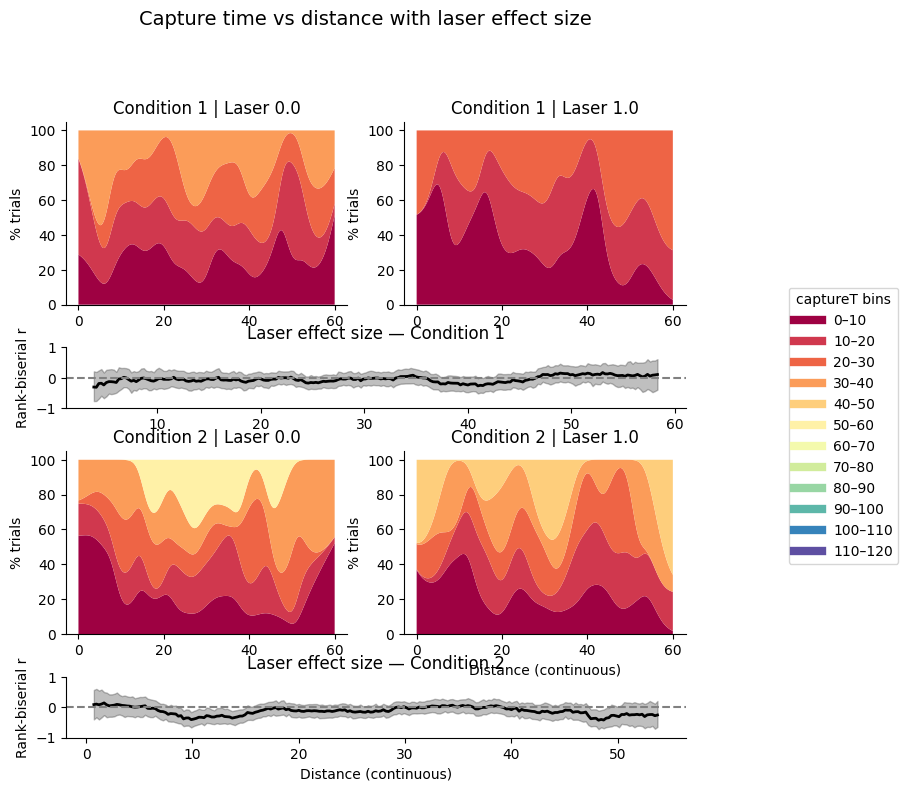

In [233]:
plot_metric_vs_distance_condition_laser_with_effects(
    cleaned_conds_keep,
    metric_col='captureT',
    metric_bin_size=10,
    title='Capture time vs distance with laser effect size'
)

